# Keeping Credit-Card Fraud Detectors Reliable Under Concept Drift: A Comparison of Adaptive Model-Maintenance Strategies

Credit-card fraud models face two problems at once: fraud is extremely rare (0.17% of transactions), and fraud
patterns change over time (*concept drift*). A model that is never updated silently stops working. This project
asks **how best to keep a classical fraud model reliable**. It compares the adaptive strategies a bank could use
against a frozen model:
- periodic retraining
- online learning
- retraining triggered by the ADWIN or DDM drift detectors
- the DDM warning-window method
- our accumulate-after-drift variant

**This notebook is the whole project in one file.**

| Part | Contents |
|---|---|
| 0. Setup | How the code cells work; switches for re-running experiments |
| A. Project code | Every module of `src/`, verbatim |
| B. Exploratory data analysis | The ULB data, imbalance, drift injection, the synthetic stream |
| C. Experiments | Every experiment script, verbatim, with a switch to re-run it |
| D. Results and analysis | Three research questions, the strategy ranking, why detectors trail, synthesis |
| E. Reproducibility check | Confirms the code here is identical to the repository; optional test run |

**How to use it.** Open it with the project's `.venv` kernel and use Run All. This takes about a minute.
- The experiments are **switched off** by default, because together they take about 5 hours.
- With the experiments off, Part D reads their saved outputs from `results/`.
- Switching an experiment on in Part 0 re-runs the identical script and rewrites its files in `results/`. The
  seeds are fixed, so the numbers come out the same.
- The ULB data must be at `data/raw/creditcard.csv`.

## 0. Setup

Each code cell in Parts A and C starts with `%%module <name>`. That line runs the cell as the module of that
name (for example `src.models.retrain`), with the same file path it has in the repository. Imports between
modules (`from src.models.retrain import PeriodicRetrain`) and the scripts' output folders therefore work
exactly as when the code runs from the repository.

In [1]:
import os
import sys
import types
from pathlib import Path

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT))
NOTEBOOK_SOURCES = {}  # module name -> source defined in this notebook (checked in Part E)


def define_module(name, source):
    """Run `source` as module `name`, registered like a normal import (same name and __file__)."""
    parts = name.split(".")
    for i in range(1, len(parts)):  # parent packages, e.g. src and src.models
        pkg = ".".join(parts[:i])
        if pkg not in sys.modules:
            package = types.ModuleType(pkg)
            package.__path__ = []  # nothing is loaded from disk: every module must be defined in this notebook
            sys.modules[pkg] = package
            if i > 1:
                setattr(sys.modules[".".join(parts[:i - 1])], parts[i - 1], package)
    module = types.ModuleType(name)
    module.__file__ = str(PROJECT.joinpath(*parts).with_suffix(".py"))
    module.__package__ = ".".join(parts[:-1])
    sys.modules[name] = module
    exec(compile(source, module.__file__, "exec"), module.__dict__)
    setattr(sys.modules[module.__package__], parts[-1], module)
    NOTEBOOK_SOURCES[name] = source
    return module


try:  # register the %%module cell magic in Jupyter
    get_ipython().register_magic_function(lambda line, cell: define_module(line.strip(), cell), "cell", "module")
except NameError:
    pass

# --- switches for Part C (False = use the saved results in results/) ----------------------------------------
ULB = str(PROJECT / "data" / "raw" / "creditcard.csv")
RUN = {
    "main experiments": False,        # ~20 min
    "imbalance": False,               # ~10 min
    "reported vs deployed": False,    # ~5 min
    "sensitivity": False,             # ~25 min
    "protocol": False,                # ~3 h (resumable)
    "severity": False,                # ~7 min
    "error analysis": False,          # ~2 min
    "shap": False,                    # ~2 min
    "detector signals": False,        # ~2 min
    "supplementary": False,           # ~1.5 h (resumable)
    "tests": False,                   # ~1 min, runs pytest on the repository
}


def run_script(module, *args):
    """Run an experiment script exactly like `python experiments/<script>.py <args>` from the project root."""
    old_argv, old_cwd = sys.argv, os.getcwd()
    sys.argv = [module.__file__, *args]
    os.chdir(PROJECT)
    try:
        module.main()
    finally:
        sys.argv = old_argv
        os.chdir(old_cwd)


print("project root:", PROJECT, "| ULB data found:", Path(ULB).exists())

project root: d:\Documents\COLLEGE\SEM5\ML LAB\project | ULB data found: True


## Part A: Project code

The `src/` package, one module per cell, in dependency order. Nothing runs here except definitions.

### A. `src/data`: Data: loading, streaming, synthetic data and drift injection

**`src/data/synthetic.py`**: Synthetic, time-ordered, imbalanced transaction stream with one abrupt concept drift.

In [2]:
%%module src.data.synthetic
"""Synthetic, time-ordered, imbalanced transaction stream with one abrupt concept drift.

Layout mirrors the ULB dataset (Time, V1..Vn, Amount, Class) so every downstream
module works unchanged on synthetic and real data.

Before the drift point, fraud is shifted *up* on V1-V3 and has larger amounts.
After it, fraud is shifted *down* on V4-V6 (V1-V3 look legitimate again) and
amounts are small ("card testing"). A model frozen on the early pattern should
lose most of its recall after the drift.
"""
import numpy as np
import pandas as pd


def generate_synthetic_stream(
    n_samples=50_000,
    n_features=10,
    fraud_rate=0.01,
    drift_at=0.5,
    shift=2.0,
    duration=172_800,
    seed=42,
):
    """Return a DataFrame sorted by Time with columns Time, V1..Vn, Amount, Class.

    drift_at is the fraction of the stream (by time order) where the fraud pattern changes.
    """
    if n_features < 6:
        raise ValueError("n_features must be >= 6 (V1-V3 and V4-V6 carry the two fraud patterns)")

    rng = np.random.default_rng(seed)
    time = np.sort(rng.uniform(0, duration, n_samples))
    y = (rng.random(n_samples) < fraud_rate).astype(int)
    X = rng.standard_normal((n_samples, n_features))
    amount = rng.lognormal(mean=3.0, sigma=1.0, size=n_samples)

    after = np.arange(n_samples) >= int(drift_at * n_samples)
    early_fraud = (y == 1) & ~after
    late_fraud = (y == 1) & after

    X[np.ix_(early_fraud, [0, 1, 2])] += shift
    X[np.ix_(late_fraud, [3, 4, 5])] -= shift
    amount[early_fraud] = rng.lognormal(mean=4.0, sigma=1.2, size=early_fraud.sum())
    amount[late_fraud] = rng.lognormal(mean=1.5, sigma=0.8, size=late_fraud.sum())

    df = pd.DataFrame(X, columns=[f"V{i + 1}" for i in range(n_features)])
    df.insert(0, "Time", time)
    df["Amount"] = amount.round(2)
    df["Class"] = y
    return df

<module 'src.data.synthetic' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\data\\synthetic.py'>

**`src/data/loader.py`**: Load a dataset into the common format: a Time column, a binary Class column, numeric features.

In [3]:
%%module src.data.loader
"""Load a dataset into the common format: a Time column, a binary Class column, numeric features."""
import pandas as pd

from src.data.synthetic import generate_synthetic_stream

TIME = "Time"
TARGET = "Class"  # 1 = fraud, 0 = legitimate

# IEEE-CIS uses different names for the same roles
_RENAMES = {"TransactionDT": TIME, "isFraud": TARGET}
_ID_COLUMNS = ["TransactionID"]


def get_feature_columns(df):
    """Every column except Time and Class, so ULB, IEEE-CIS and synthetic all work."""
    return [c for c in df.columns if c not in (TIME, TARGET)]


def load_dataset(path=None, **synthetic_kwargs):
    """Load a CSV (or generate the synthetic stream when path is None), validate it, sort by Time."""
    if path is None:
        df = generate_synthetic_stream(**synthetic_kwargs)
    else:
        df = pd.read_csv(path)
        df = df.rename(columns=_RENAMES)
        df = df.drop(columns=[c for c in _ID_COLUMNS if c in df.columns])
        df = _clean(df)

    _validate(df)
    return df.sort_values(TIME, kind="stable").reset_index(drop=True)


def _clean(df):
    """Median-impute numeric columns; fill and integer-encode categoricals (needed for IEEE-CIS).

    Note: medians are taken over the whole file, a mild look-ahead that is acceptable for
    imputation but should be mentioned in the report.
    """
    df = df.copy()
    features = get_feature_columns(df)
    numeric = df[features].select_dtypes(include="number").columns
    categorical = [c for c in features if c not in numeric]

    df[numeric] = df[numeric].fillna(df[numeric].median())
    for col in categorical:
        df[col] = df[col].fillna("missing").astype("category").cat.codes
    return df


def _validate(df):
    missing = {TIME, TARGET} - set(df.columns)
    if missing:
        raise ValueError(f"dataset is missing required columns: {sorted(missing)}")
    if not set(df[TARGET].unique()) <= {0, 1}:
        raise ValueError(f"{TARGET} must be binary 0/1")
    if df[get_feature_columns(df)].isna().any().any():
        raise ValueError("features contain missing values after cleaning")

<module 'src.data.loader' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\data\\loader.py'>

**`src/data/drift_injection.py`**: Inject a known concept drift into a real dataset (the controlled experiment on ULB).

In [4]:
%%module src.data.drift_injection
"""Inject a known concept drift into a real dataset (the controlled experiment on ULB).

Feature swap: from the drift point onwards, pairs of features exchange values for every transaction.
The data stay real, but the columns a model learned to watch stop carrying the fraud signal and other
columns start to, i.e. P(fraud | X) changes at a known time.

Pairs are either the k features most correlated with fraud swapped with the k least correlated
(default: a severe, targeted drift; note the choice uses the labels of the whole file, which only
designs the experiment and is never seen by a model), or k random pairs (pair_seed: a drift of
random, usually milder, severity). width > 0 makes the drift gradual: within the window that starts
at `at`, each row is swapped with a probability rising linearly from 0 to 1.
"""
import numpy as np

from src.data.loader import TARGET, get_feature_columns


def _candidate_features(df):
    return [c for c in get_feature_columns(df) if c != "Amount"]


def choose_swap_pairs(df, k=4):
    """Pair the k most fraud-correlated features with the k least correlated ones."""
    features = _candidate_features(df)
    corr = df[features].corrwith(df[TARGET]).abs().sort_values(ascending=False)
    strongest, weakest = list(corr.index[:k]), list(corr.index[-k:][::-1])
    return list(zip(strongest, weakest))


def choose_random_pairs(df, k=4, seed=0):
    """k disjoint random pairs of features, ignoring how predictive they are."""
    picked = np.random.default_rng(seed).choice(_candidate_features(df), size=2 * k, replace=False)
    return [(str(a), str(b)) for a, b in zip(picked[:k], picked[k:])]


def inject_feature_swap(df, at=0.5, k=4, pairs=None, pair_seed=None, width=0.0, seed=0):
    """Return (drifted copy of df, pairs swapped). df must be time-sorted; at and width are fractions of rows."""
    if pairs is None:
        pairs = choose_random_pairs(df, k, pair_seed) if pair_seed is not None else choose_swap_pairs(df, k)
    n = len(df)
    start, end = int(at * n), min(n, int((at + width) * n))
    swap = np.zeros(n, dtype=bool)
    swap[end:] = True
    if end > start:  # gradual: probability of a row being swapped rises linearly across the window
        ramp = (np.arange(start, end) - start + 1) / (end - start)
        swap[start:end] = np.random.default_rng(seed).random(end - start) < ramp

    out = df.copy()
    for a, b in pairs:
        # explicit copies: to_numpy() can return a view, so writing column a first would
        # overwrite the values column b is about to receive
        a_vals = out[a].to_numpy(copy=True)
        b_vals = out[b].to_numpy(copy=True)
        a_new, b_new = a_vals.copy(), b_vals.copy()
        a_new[swap], b_new[swap] = b_vals[swap], a_vals[swap]
        out[a], out[b] = a_new, b_new
    return out, pairs

<module 'src.data.drift_injection' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\data\\drift_injection.py'>

**`src/data/stream.py`**: Contract 1: the data stream. Batches are yielded strictly in time order, never shuffled.

In [5]:
%%module src.data.stream
"""Contract 1: the data stream. Batches are yielded strictly in time order, never shuffled."""
from src.data.loader import TARGET, TIME, get_feature_columns, load_dataset  # noqa: F401


def make_stream(df, batch_size=2000, features=None):
    """Yield (X_batch, y_batch) in time order. The last batch may be smaller."""
    if not df[TIME].is_monotonic_increasing:
        raise ValueError("df must be sorted by Time; use load_dataset()")
    features = features or get_feature_columns(df)
    for start in range(0, len(df), batch_size):
        batch = df.iloc[start:start + batch_size]
        yield batch[features], batch[TARGET]

<module 'src.data.stream' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\data\\stream.py'>

### A. `src/drift`: Drift detectors

**`src/drift/detectors.py`**: Drift detectors behind one tiny interface: update(errors) -> bool.

In [6]:
%%module src.drift.detectors
"""Drift detectors behind one tiny interface: update(errors) -> bool.

`errors` is the per-sample 0/1 error signal for one batch (the harness feeds one value per
fraudulent transaction: 1 if the model missed it). The wrapped River detector sees every value
in order; update returns True if it signalled drift anywhere in the batch.

After a detection the River detector is replaced with a fresh one: the model is about to be
refit, so its error rate will change again, and the old statistics would trigger a spurious
second alarm.

ADWIN flags a change in either direction, but only a rise in errors means the model is going
stale; a fall (e.g. a model recovering after a refit) is ignored. DDM only detects rises anyway.
"""
from river import drift


class DriftDetector:
    def __init__(self, name, prototype):
        self.name = name
        self.prototype = prototype
        self.detector = prototype.clone()

    def update(self, errors):
        for e in errors:
            before = getattr(self.detector, "estimation", None)
            self.detector.update(e)
            if not self.detector.drift_detected:
                continue
            # ADWIN drops the older part of its window on a change: if the mean went down,
            # the dropped (older) errors were higher, i.e. the model got better
            if before is not None and self.detector.estimation < before:
                continue
            self.detector = self.prototype.clone()
            return True
        return False


class NoDriftDetector:
    """Fallback that never fires, so 'no detector' runs through the same code path."""
    name = "none"

    def update(self, errors):
        return False


def make_adwin(delta=0.002):
    # clock=1 checks for a change after every value instead of every 32
    return DriftDetector("adwin", drift.ADWIN(delta=delta, clock=1))


def make_ddm(warm_start=30, drift_threshold=3.0):
    return DriftDetector("ddm", drift.binary.DDM(warm_start=warm_start, drift_threshold=drift_threshold))

<module 'src.drift.detectors' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\drift\\detectors.py'>

### A. `src/evaluation`: Evaluation: metrics, prequential loop, drift response and statistics

**`src/evaluation/drift_metrics.py`**: How a model reacts to drift (objectives 2 and 3): size of the drop, recovery time, slow decay.

In [7]:
%%module src.evaluation.drift_metrics
"""How a model reacts to drift (objectives 2 and 3): size of the drop, recovery time, slow decay.

All functions read the per-batch results format written by prequential_eval, so they work on
any saved results CSV without rerunning a model.
"""
import math

import numpy as np
import pandas as pd


def drift_response(run, drift_batch, recover_frac=0.9, smooth=3, metric="pr_auc"):
    """Summarise one model run around a known drift that starts at (possibly fractional) drift_batch.

    before / after:   mean metric over batches entirely before / entirely after the drift
                      (the batch that straddles the drift point counts as neither)
    drop, drop_pct:   before - after, absolute and as % of before
    worst_after:      lowest `smooth`-batch rolling mean after the drift
    batches_below:    post-drift batches whose rolling mean is under recover_frac x before
    recovery_batches: batches from the drift until the rolling mean is back at or above
                      recover_frac x before, after having fallen below it.
                      0 = never fell below; NaN = fell and never came back within the stream.
    """
    run = run.sort_values("batch_idx")
    before = run.loc[run["batch_idx"] < math.floor(drift_batch), metric].mean()
    after = run.loc[run["batch_idx"] >= math.ceil(drift_batch), metric]
    # smooth within the post-drift period only, so pre-drift scores can't mask the drop
    rolling = after.rolling(smooth, min_periods=1).mean().to_numpy()
    target = recover_frac * before
    below = rolling < target

    if not below.any():
        recovery = 0.0
    else:
        first_drop = int(np.argmax(below))
        back = np.flatnonzero(~below[first_drop:] & ~np.isnan(rolling[first_drop:]))
        recovery = float(first_drop + back[0]) if back.size else np.nan

    return {
        "before": before,
        "after": after.mean(),
        "drop": before - after.mean(),
        "drop_pct": 100 * (before - after.mean()) / before if before else np.nan,
        "worst_after": np.nanmin(rolling) if len(rolling) else np.nan,
        "batches_below": int(below.sum()),
        "recovery_batches": recovery,
    }


def trend_per_10_batches(run, metric="pr_auc"):
    """Least-squares slope of the metric over time, scaled to 'change per 10 batches'.

    For data without a known drift point, a clearly negative value means slow decay.
    """
    points = run[["batch_idx", metric]].dropna()
    if len(points) < 3:
        return np.nan
    slope = np.polyfit(points["batch_idx"], points[metric], 1)[0]
    return 10 * slope


def drift_response_table(results, drift_batch, **kwargs):
    """drift_response for every model_name in a results DataFrame, one row each."""
    rows = {name: drift_response(run, drift_batch, **kwargs) for name, run in results.groupby("model_name", sort=False)}
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("model_name").reset_index()

<module 'src.evaluation.drift_metrics' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\evaluation\\drift_metrics.py'>

**`src/evaluation/metrics.py`**: Imbalance-aware metrics for one batch of scores.

In [ ]:
%%module src.evaluation.metrics
"""Imbalance-aware metrics for one batch of scores."""
import numpy as np
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

METRIC_KEYS = ["pr_auc", "roc_auc", "recall_at_p", "fpr", "threshold"]


OPERATIONAL_KEYS = ["op_recall", "op_precision", "op_fpr"]


def operational_metrics(y_true, y_score, threshold):
    """Recall, precision and FPR when flagging every score >= threshold, a threshold fixed in advance.

    All NaN when there is no usable threshold yet (inf); op_recall is NaN for a batch with no fraud and
    op_precision NaN when nothing is flagged.
    """
    if not np.isfinite(threshold):
        return {k: np.nan for k in OPERATIONAL_KEYS}
    y_true = np.asarray(y_true)
    flagged = np.asarray(y_score, dtype=float) >= threshold
    tp = int(np.sum(flagged & (y_true == 1)))
    n_fraud, n_legit, n_flagged = int(np.sum(y_true == 1)), int(np.sum(y_true == 0)), int(flagged.sum())
    return {
        "op_recall": tp / n_fraud if n_fraud else np.nan,
        "op_precision": tp / n_flagged if n_flagged else np.nan,
        "op_fpr": (n_flagged - tp) / n_legit if n_legit else np.nan,
    }


def compute_metrics(y_true, y_score, precision_target=0.90):
    """Return {pr_auc, roc_auc, recall_at_p, fpr, threshold}.

    recall_at_p is the highest recall reachable while precision >= precision_target;
    threshold is the score cut-off that achieves it and fpr is the false-positive rate there.
    The threshold is chosen with this batch's own labels, so recall_at_p is an oracle upper bound;
    operational_metrics() measures a threshold fixed in advance.
    If the batch has only one class, every value is NaN.
    """
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score, dtype=float)
    if len(np.unique(y_true)) < 2:
        return {k: np.nan for k in METRIC_KEYS}

    precision, recall, thresholds = precision_recall_curve(y_true, y_score)
    # the curve's final point (precision=1, recall=0) has no threshold, so drop it
    meets_target = precision[:-1] >= precision_target
    if meets_target.any():
        best = np.argmax(np.where(meets_target, recall[:-1], -1.0))
        threshold, recall_at_p = thresholds[best], recall[best]
    else:
        threshold, recall_at_p = np.inf, 0.0

    negatives = y_true == 0
    fpr = np.mean(y_score[negatives] >= threshold)

    return {
        # average precision: the standard step-wise estimate of the area under the PR curve
        "pr_auc": average_precision_score(y_true, y_score),
        "roc_auc": roc_auc_score(y_true, y_score),
        "recall_at_p": float(recall_at_p),
        "fpr": float(fpr),
        "threshold": float(threshold),
    }

<module 'src.evaluation.metrics' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\evaluation\\metrics.py'>

**`src/evaluation/prequential.py`**: Contract 3: prequential (test-then-train) evaluation down a time-ordered stream.

In [9]:
%%module src.evaluation.prequential
"""Contract 3: prequential (test-then-train) evaluation down a time-ordered stream."""
from collections import deque

import numpy as np
import pandas as pd

from src.evaluation.metrics import compute_metrics, operational_metrics

RESULT_COLUMNS = [
    "model_name", "batch_idx", "n", "n_fraud",
    "pr_auc", "roc_auc", "recall_at_p", "fpr", "threshold",
    "op_recall", "op_precision", "op_fpr", "drift_flag",
]


def prequential_eval(model, stream, drift_detector=None, precision_target=0.90,
                     warmup_batches=1, error_threshold=0.5, label_delay=0, score_sink=None):
    """Warm up on the first warmup_batches batches, then for every later batch: predict -> score -> update.

    Metrics per batch:
      pr_auc, roc_auc               ranking quality
      recall_at_p, fpr, threshold   at the threshold reaching precision_target on THIS batch's labels
                                    (an oracle upper bound: a live system can't pick it this way)
      op_recall, op_precision, op_fpr  at the threshold carried over from the previous batch whose
                                    labels are known (what a live system could actually achieve)

    label_delay: labels of a batch reach the model and the detector only label_delay batches after the
    batch was scored (0 = immediately). Evaluation itself always uses the true labels.

    drift_detector, if given, needs update(errors) -> bool. It receives one 0/1 value per fraudulent
    transaction of a labelled batch (1 = missed: scored below error_threshold when it was scored); when it
    fires, the model is refit on that batch instead of the usual partial_fit. A model that runs its own
    detector can report an alarm through a truthy `last_alarm` attribute after partial_fit.

    score_sink: optional list; each scored batch appends a DataFrame of (batch_idx, row, y, score).

    Returns one row per evaluated batch; batch_idx counts from the start of the stream. With a detector,
    model_name is "<model>+<detector>".
    """
    stream = iter(stream)
    warmup = [next(stream) for _ in range(warmup_batches)]
    model.fit(pd.concat([X for X, _ in warmup]), pd.concat([y for _, y in warmup]))

    name = model.name if drift_detector is None else f"{model.name}+{drift_detector.name}"
    pending = deque()  # scored batches whose labels haven't arrived yet: (X, y, scores)
    live_threshold = np.inf  # latest threshold learnt from labelled data
    rows = []
    for batch_idx, (X, y) in enumerate(stream, start=warmup_batches):
        scores = model.predict_proba(X)
        metrics = compute_metrics(y, scores, precision_target)
        operational = operational_metrics(y, scores, live_threshold)
        if score_sink is not None:
            score_sink.append(pd.DataFrame({"batch_idx": batch_idx, "row": X.index, "y": np.asarray(y), "score": scores}))

        pending.append((X, y, scores, metrics["threshold"]))
        drift = False
        while len(pending) > label_delay:
            X_l, y_l, s_l, thr_l = pending.popleft()  # this batch's labels are now known
            if np.isfinite(thr_l):
                live_threshold = thr_l
            alarm = False
            is_fraud = np.asarray(y_l) == 1
            if drift_detector is not None and is_fraud.any():
                missed = (s_l[is_fraud] < error_threshold).astype(int)
                alarm = bool(drift_detector.update(missed))
            if alarm:
                model.refit(X_l, y_l)
            else:
                model.partial_fit(X_l, y_l)
            drift = drift or alarm or bool(getattr(model, "last_alarm", False))

        rows.append({
            "model_name": name,
            "batch_idx": batch_idx,
            "n": len(y),
            "n_fraud": int(np.sum(y)),
            **metrics,
            **operational,
            "drift_flag": int(drift),
        })

    return pd.DataFrame(rows, columns=RESULT_COLUMNS)

<module 'src.evaluation.prequential' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\evaluation\\prequential.py'>

**`src/evaluation/stats.py`**: Uncertainty for comparisons between strategies.

In [10]:
%%module src.evaluation.stats
"""Uncertainty for comparisons between strategies.

Per-batch scores are noisy (PR-AUC sd ~0.2 per batch on ULB) and neighbouring batches are correlated,
so a difference between two strategies is judged with a paired moving-block bootstrap over batches:
the per-batch difference (averaged over seeds when there are several runs) is resampled in blocks of
consecutive batches, which keeps short-range correlation inside each block.
"""
import numpy as np
import pandas as pd


def block_bootstrap_mean(values, block=3, n_boot=5000, seed=0, level=0.95):
    """Mean of a time-ordered series and its moving-block bootstrap confidence interval."""
    x = np.asarray(pd.Series(values).dropna(), dtype=float)
    n = len(x)
    if n == 0:
        return np.nan, np.nan, np.nan
    block = max(1, min(block, n))
    rng = np.random.default_rng(seed)
    n_blocks = -(-n // block)
    starts = rng.integers(0, n - block + 1, size=(n_boot, n_blocks))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]
    means = x[idx].mean(axis=1)
    alpha = (1 - level) / 2
    return x.mean(), np.quantile(means, alpha), np.quantile(means, 1 - alpha)


def paired_difference(a, b, block=3, n_boot=5000, seed=0):
    """Mean of a - b with a block-bootstrap CI.

    a, b: Series indexed by batch_idx, or DataFrames indexed by batch_idx with one column per seed
    (seeds are averaged per batch first). Returns dict(mean, lo, hi, n_batches, significant).
    """
    diff = (pd.DataFrame(a) - pd.DataFrame(b)).mean(axis=1).sort_index().dropna()
    mean, lo, hi = block_bootstrap_mean(diff, block=block, n_boot=n_boot, seed=seed)
    return {"mean": mean, "lo": lo, "hi": hi, "n_batches": len(diff), "significant": bool(lo > 0 or hi < 0)}

<module 'src.evaluation.stats' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\evaluation\\stats.py'>

### A. `src/explain`: Explainability (SHAP)

**`src/explain/shap_analysis.py`**: Which features a tree model relies on: mean |SHAP value| per feature for the fraud class.

In [11]:
%%module src.explain.shap_analysis
"""Which features a tree model relies on: mean |SHAP value| per feature for the fraud class."""
import numpy as np
import pandas as pd
import shap
from sklearn.pipeline import Pipeline


def _tree_model(model):
    """The fitted tree estimator inside a StaticModel (a resampling pipeline's samplers only act at fit time)."""
    est = model.model
    return est.steps[-1][1] if isinstance(est, Pipeline) else est


def sample_rows(X, y, max_rows=2000, seed=42):
    """All frauds plus a random sample of legitimate rows, at most max_rows in total."""
    y = pd.Series(np.asarray(y), index=X.index)
    fraud = y.index[y == 1]
    legit = y.index[y == 0]
    n_legit = max(0, min(len(legit), max_rows - len(fraud)))
    keep = fraud.union(pd.Index(np.random.default_rng(seed).choice(legit, n_legit, replace=False)))
    return X.loc[keep]


def shap_importance(model, X, y, max_rows=2000, seed=42):
    """Mean |SHAP value| per feature for the fraud class, sorted descending.

    model: a fitted StaticModel wrapping a random forest or gradient boosting model.
    Shapes differ by model (shap 0.53): random forest returns (rows, features, 2) -> fraud slice [:, :, 1];
    gradient boosting returns (rows, features) already for the fraud class.
    """
    rows = sample_rows(X, y, max_rows, seed)
    values = np.asarray(shap.TreeExplainer(_tree_model(model)).shap_values(rows))
    if values.ndim == 3:
        values = values[:, :, 1]
    return pd.Series(np.abs(values).mean(axis=0), index=X.columns).sort_values(ascending=False)

<module 'src.explain.shap_analysis' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\explain\\shap_analysis.py'>

### A. `src/imbalance`: Imbalance handling

**`src/imbalance/samplers.py`**: Imbalance handling for the static (scikit-learn) models: class weights or resampling.

In [12]:
%%module src.imbalance.samplers
"""Imbalance handling for the static (scikit-learn) models: class weights or resampling.

Resampling happens only while a model is trained; scoring always runs on the real, untouched
transactions. (The online River models handle imbalance with their own undersampler.)
"""
import numpy as np
from imblearn import FunctionSampler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

METHODS = {
    "none": "no handling",
    "weights": "class weights",
    "smote": "SMOTE",
    "undersample": "undersampling",
}


def _counts(y):
    n_fraud = int(np.sum(np.asarray(y) == 1))
    return n_fraud, len(y) - n_fraud


def smote(X, y, ratio=0.5, seed=42):
    """Add synthetic frauds until there are `ratio` frauds per legitimate transaction.

    SMOTE needs k_neighbors < number of frauds, and single ULB batches can hold as few as 3,
    so k shrinks to fit; with fewer than 2 frauds there is nothing to interpolate between.
    """
    n_fraud, n_legit = _counts(y)
    if n_fraud < 2 or n_fraud >= ratio * n_legit:
        return X, y
    k = min(5, n_fraud - 1)
    return SMOTE(sampling_strategy=ratio, k_neighbors=k, random_state=seed).fit_resample(X, y)


def undersample(X, y, ratio=0.5, seed=42):
    """Drop legitimate transactions at random until there are `ratio` frauds per legitimate one."""
    n_fraud, n_legit = _counts(y)
    if n_fraud == 0 or n_fraud >= ratio * n_legit:
        return X, y
    return RandomUnderSampler(sampling_strategy=ratio, random_state=seed).fit_resample(X, y)


def with_imbalance_handling(estimator, method="weights", ratio=0.5, seed=42):
    """Return a copy of `estimator` (a classifier, or a Pipeline ending in one) set up for `method`.

    weights:              class_weight on the classifier ("balanced_subsample" for random forests)
    none:                 class_weight removed, data used as-is
    smote / undersample:  a sampler inserted just before the classifier (after any scaler, since
                          SMOTE interpolates between neighbours in feature space)
    """
    if method not in METHODS:
        raise ValueError(f"unknown imbalance method {method!r}; choose from {list(METHODS)}")

    steps = list(clone(estimator).steps) if isinstance(estimator, Pipeline) else [("clf", clone(estimator))]
    clf = steps[-1][1]
    if "class_weight" in clf.get_params():
        weight = "balanced_subsample" if isinstance(clf, RandomForestClassifier) else "balanced"
        clf.set_params(class_weight=weight if method == "weights" else None)

    if method in ("smote", "undersample"):
        func = smote if method == "smote" else undersample
        sampler = FunctionSampler(func=func, kw_args={"ratio": ratio, "seed": seed}, validate=False)
        return ImbPipeline(steps[:-1] + [("sampler", sampler), steps[-1]])
    return Pipeline(steps) if len(steps) > 1 else clf

<module 'src.imbalance.samplers' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\imbalance\\samplers.py'>

### A. `src/models`: Models and adaptive strategies

**`src/models/base.py`**: Contract 2: every model exposes the same four methods so the harness can treat them alike.

In [13]:
%%module src.models.base
"""Contract 2: every model exposes the same four methods so the harness can treat them alike."""


class BaseDetector:
    name = "base"

    def fit(self, X, y):
        """Batch training / warm-up."""
        raise NotImplementedError

    def partial_fit(self, X, y):
        """Per-batch update. Default is a no-op, i.e. a frozen model."""
        return self

    def predict_proba(self, X):
        """P(fraud) in [0, 1], shape (n,)."""
        raise NotImplementedError

    def refit(self, X, y):
        """Adapt after a detected drift. Default: full re-fit on the given data."""
        return self.fit(X, y)

<module 'src.models.base' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\models\\base.py'>

**`src/models/baselines.py`**: Static models: fit once at warm-up, then frozen (partial_fit is a no-op).

In [14]:
%%module src.models.baselines
"""Static models: fit once at warm-up, then frozen (partial_fit is a no-op)."""
import numpy as np
import pandas as pd
from scipy.special import expit
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.imbalance.samplers import with_imbalance_handling
from src.models.base import BaseDetector


def has_both_classes(y):
    return len(np.unique(y)) == 2


class StaticModel(BaseDetector):
    """Wraps any scikit-learn classifier with predict_proba."""

    def __init__(self, name, estimator):
        self.name = name
        self.estimator = estimator
        self.model = None

    def fit(self, X, y):
        if not has_both_classes(y):
            raise ValueError(f"{self.name}: training data needs both classes; use more warm-up batches")
        self.model = clone(self.estimator).fit(X, y)
        return self

    def refit(self, X, y):
        # a drift batch with no fraud can't train a classifier, so keep the current one
        return self.fit(X, y) if has_both_classes(y) else self

    def predict_proba(self, X):
        return self.model.predict_proba(X)[:, 1]


def _static(name, estimator, imbalance, seed):
    # class weights are the default, so those models keep their plain names
    suffix = "" if imbalance == "weights" else f"_{imbalance}"
    return StaticModel(name + suffix, with_imbalance_handling(estimator, imbalance, seed=seed))


def make_logreg(seed=42, imbalance="weights"):
    return _static("logreg", make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=seed),
    ), imbalance, seed)


def make_random_forest(seed=42, imbalance="weights"):
    return _static("random_forest", RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=seed,
    ), imbalance, seed)


def make_gradient_boosting(seed=42, imbalance="weights"):
    # early_stopping off: its default ("auto") silently holds out 10% of the training data, i.e. only a
    # handful of frauds, to decide when to stop; max_iter is the default 100, now stated explicitly
    return _static("gradient_boosting", HistGradientBoostingClassifier(
        max_iter=100, early_stopping=False, random_state=seed,
    ), imbalance, seed)


class SingleFeatureRule(BaseDetector):
    """Trivial baseline: flag transactions by ONE feature, the one most correlated with fraud in the
    training data (sign included). Shows how much the ML models add over a one-line rule."""

    name = "rule"

    def fit(self, X, y):
        if not has_both_classes(y):
            raise ValueError(f"{self.name}: training data needs both classes")
        corr = X.corrwith(pd.Series(np.asarray(y), index=X.index)).fillna(0)
        self.feature = corr.abs().idxmax()
        self.sign = np.sign(corr[self.feature]) or 1.0
        self.mean, self.std = X[self.feature].mean(), X[self.feature].std() or 1.0
        return self

    def refit(self, X, y):
        return self.fit(X, y) if has_both_classes(y) else self

    def predict_proba(self, X):
        z = self.sign * (X[self.feature].to_numpy() - self.mean) / self.std
        return expit(z)


def make_rule(seed=42, imbalance="weights"):
    return SingleFeatureRule()

<module 'src.models.baselines' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\models\\baselines.py'>

**`src/models/drift_retrain.py`**: Drift-triggered retraining schemes for static models.

In [15]:
%%module src.models.drift_retrain
"""Drift-triggered retraining schemes for static models.

AccumulateAfterDrift (this project's variant): plain "+ detector" refits a static model on the
single alarm batch and freezes it again, so the new model rests on very little fraud. This wrapper
instead keeps refitting on every batch since the alarm (a growing window of post-drift data) until
it holds `accumulate` batches, then freezes. Between drifts it costs nothing, like a static model.
It is a variant of DDM's own scheme (below): the window starts at the alarm instead of the warning.

WarningWindowRetrain (Gama et al., 2004, "Learning with Drift Detection"): DDM's warning level
starts a buffer of examples; when the drift level is reached, a new model is learnt from the
examples since the warning only. Used here as the established baseline for AccumulateAfterDrift.
"""
import numpy as np
import pandas as pd
from river import drift

from src.models.base import BaseDetector
from src.models.baselines import has_both_classes


class AccumulateAfterDrift(BaseDetector):
    def __init__(self, inner, accumulate=6):
        """inner: a StaticModel; accumulate: post-drift batches to gather before freezing again."""
        self.inner = inner
        self.accumulate = accumulate
        self.name = f"{inner.name}_acc{accumulate}"
        self.buffer = []  # batches since the last alarm; empty when frozen

    def fit(self, X, y):
        self.buffer = []
        self.inner.fit(X, y)
        return self

    def refit(self, X, y):
        self.buffer = [(X, y)]
        self._refit_on_buffer()
        return self

    def partial_fit(self, X, y):
        if 0 < len(self.buffer) < self.accumulate:
            self.buffer.append((X, y))
            self._refit_on_buffer()
        return self

    def predict_proba(self, X):
        return self.inner.predict_proba(X)

    def _refit_on_buffer(self):
        y = pd.concat([b[1] for b in self.buffer])
        if has_both_classes(y):
            self.inner.fit(pd.concat([b[0] for b in self.buffer]), y)


class WarningWindowRetrain(BaseDetector):
    """DDM with its warning window, run inside the model (use it with drift_detector=None).

    On each labelled batch the model scores it, feeds DDM one 0/1 error per fraud (missed = score
    below error_threshold), and then: drift -> refit on the batches buffered since the warning
    (plus this one) and restart DDM; warning -> buffer the batch; otherwise -> clear the buffer.
    `last_alarm` tells the evaluation loop when a drift was handled, so it is recorded as an alarm.
    """

    def __init__(self, inner, error_threshold=0.5, max_buffer=10):
        self.inner = inner
        self.error_threshold = error_threshold
        self.max_buffer = max_buffer
        self.name = f"{inner.name}_ddmwarn"
        self.buffer = []
        self.last_alarm = False

    def fit(self, X, y):
        self.inner.fit(X, y)
        self.detector = drift.binary.DDM()
        self.buffer = []
        self.last_alarm = False
        return self

    def refit(self, X, y):
        self.buffer = [(X, y)]
        self._refit_on_buffer()
        return self

    def partial_fit(self, X, y):
        self.last_alarm = False
        is_fraud = np.asarray(y) == 1
        if not is_fraud.any():
            return self
        missed = self.inner.predict_proba(X)[is_fraud] < self.error_threshold
        warning = drifted = False
        for e in missed.astype(int):
            self.detector.update(e)
            warning = warning or self.detector.warning_detected
            if self.detector.drift_detected:
                drifted = True
                break
        if drifted:
            self.buffer.append((X, y))
            self._refit_on_buffer()
            self.detector = drift.binary.DDM()
            self.buffer = []
            self.last_alarm = True
        elif warning:
            self.buffer = (self.buffer + [(X, y)])[-self.max_buffer:]
        else:
            self.buffer = []
        return self

    def predict_proba(self, X):
        return self.inner.predict_proba(X)

    def _refit_on_buffer(self):
        y = pd.concat([b[1] for b in self.buffer])
        if has_both_classes(y):
            self.inner.fit(pd.concat([b[0] for b in self.buffer]), y)

<module 'src.models.drift_retrain' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\models\\drift_retrain.py'>

**`src/models/online.py`**: Online models (River): learn from every transaction, one at a time, as the stream goes by.

In [16]:
%%module src.models.online
"""Online models (River): learn from every transaction, one at a time, as the stream goes by."""
import numpy as np
from river import forest, imblearn, linear_model, optim, preprocessing

from src.models.base import BaseDetector


class OnlineModel(BaseDetector):
    """Wraps a River classifier. `prototype` is cloned fresh on fit/refit."""

    def __init__(self, name, prototype):
        self.name = name
        self.prototype = prototype
        self.model = None

    def fit(self, X, y):
        self.model = self.prototype.clone()
        return self.partial_fit(X, y)

    def partial_fit(self, X, y):
        for x, label in zip(X.to_dict(orient="records"), y):
            self.model.learn_one(x, int(label))
        return self

    def predict_proba(self, X):
        return np.array([
            self.model.predict_proba_one(x).get(1, 0.0)
            for x in X.to_dict(orient="records")
        ])


def _balanced(classifier, seed):
    # River's answer to class_weight: drop legitimate transactions until fraud is ~20% of what is learned
    return imblearn.RandomUnderSampler(classifier, desired_dist={0: 0.8, 1: 0.2}, seed=seed)


def make_online_logreg(seed=42):
    return OnlineModel("online_logreg", _balanced(
        preprocessing.StandardScaler() | linear_model.LogisticRegression(optimizer=optim.SGD(0.05)),
        seed,
    ))


def make_arf(seed=42):
    return OnlineModel("online_arf", _balanced(
        forest.ARFClassifier(n_models=10, seed=seed),
        seed,
    ))

<module 'src.models.online' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\models\\online.py'>

**`src/models/retrain.py`**: Periodic retraining: keep a sliding window of recent batches and refit on it every N batches.

In [17]:
%%module src.models.retrain
"""Periodic retraining: keep a sliding window of recent batches and refit on it every N batches."""
from collections import deque

import pandas as pd

from src.models.base import BaseDetector
from src.models.baselines import has_both_classes


class PeriodicRetrain(BaseDetector):
    def __init__(self, inner, every=5, window=10, eager_after_reset=False):
        """inner: a StaticModel; every: refit interval in batches; window: batches kept for refitting.

        eager_after_reset: after a drift alarm (refit), refit on EVERY new batch until the window is full
        of post-drift batches again, then go back to the fixed schedule. This combines periodic retraining
        (no blind period while a detector is still deciding) with accumulate-after-drift's fast rebuild.
        """
        self.inner = inner
        self.every = every
        self.window = window
        self.eager_after_reset = eager_after_reset
        self.name = f"{inner.name}_retrain{every}" + ("_reset" if eager_after_reset else "")
        self.buffer = deque(maxlen=window)
        self.since_refit = 0
        self.eager = False

    def fit(self, X, y):
        self.buffer.clear()
        self.buffer.append((X, y))
        self.inner.fit(X, y)
        self.since_refit = 0
        return self

    def partial_fit(self, X, y):
        self.buffer.append((X, y))
        self.since_refit += 1
        if self.eager:
            self._refit_on_buffer()
            self.eager = len(self.buffer) < self.window
        elif self.since_refit >= self.every:
            self._refit_on_buffer()
        return self

    def refit(self, X, y):
        # after a drift, older batches describe the old concept: start the window again
        self.buffer.clear()
        self.buffer.append((X, y))
        self._refit_on_buffer()
        self.eager = self.eager_after_reset
        return self

    def predict_proba(self, X):
        return self.inner.predict_proba(X)

    def _refit_on_buffer(self):
        X = pd.concat([b[0] for b in self.buffer])
        y = pd.concat([b[1] for b in self.buffer])
        if has_both_classes(y):
            self.inner.fit(X, y)
            self.since_refit = 0

<module 'src.models.retrain' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\models\\retrain.py'>

### A. `src/viz`: Figures

**`src/viz/plots.py`**: Figures for the report. Plots only read results DataFrames (the CSVs in results/), never models.

In [18]:
%%module src.viz.plots
"""Figures for the report. Plots only read results DataFrames (the CSVs in results/), never models.

Colour follows the adaptation strategy, never a line's position, so a strategy has the same
colour in every panel and every run.
"""
import math

import matplotlib

matplotlib.use("Agg")  # write files only, never open a window
import matplotlib.pyplot as plt

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"

# fixed categorical order (colour-blind-safe for adjacent lines)
STRATEGY_COLORS = {
    "base": "#2a78d6",
    "periodic retrain": "#eb6834",
    "+ ADWIN": "#1baf7a",
    "+ DDM": "#eda100",
    "+ ADWIN + accumulate": "#e87ba4",
    "DDM warning window": "#008300",
}
IMBALANCE_COLORS = {
    "no handling": "#2a78d6",
    "class weights": "#eb6834",
    "SMOTE": "#1baf7a",
    "undersampling": "#eda100",
}
SINGLE_SERIES = STRATEGY_COLORS["base"]
# DDM is drawn first and wider so that where it matches ADWIN exactly (same alarm batch) the
# ADWIN line stays visible on top of it instead of being hidden
LINE_WIDTHS = {"+ DDM": 3.4}
DRAW_ORDER = ["+ DDM", "+ ADWIN", "DDM warning window", "periodic retrain", "+ ADWIN + accumulate", "base"]

METRIC_LABELS = {
    "pr_auc": "PR-AUC",
    "roc_auc": "ROC-AUC",
    "recall_at_p": "Recall at 90% precision (oracle threshold)",
    "op_recall": "Recall at the previous batch's 90%-precision threshold",
    "fpr": "False-positive rate",
    "mean_pr_auc": "Mean PR-AUC across batches",
    "mean_pr_auc_after_drift": "Mean PR-AUC after the drift",
    "mean_recall_at_p": "Mean recall at 90% precision (oracle threshold)",
    "mean_op_recall": "Mean operational recall",
}


def apply_style():
    """Apply the project chart style (colours, fonts, grid) to matplotlib."""
    plt.rcParams.update({
        "font.family": ["Segoe UI", "DejaVu Sans"],
        "font.size": 10,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
        "savefig.facecolor": SURFACE,
        "savefig.dpi": 150,
    })


def plot_metric_over_time(results, out_path, metric="pr_auc", drift_batch=None, smooth=3, title=None):
    """One panel per base model ("family"), one line per strategy; dots mark batches where a detector fired.

    results needs columns family, strategy, batch_idx, drift_flag and the metric.
    smooth is a rolling-mean window in batches (1 = raw), since per-batch PR-AUC is noisy.
    """
    apply_style()
    families = list(dict.fromkeys(results["family"]))
    ncols = min(3, len(families))
    nrows = math.ceil(len(families) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.1 * nrows + 0.8),
                             sharex=True, sharey=True, squeeze=False)

    for ax, family in zip(axes.flat, families):
        fam = results[results["family"] == family]
        for z, strategy in enumerate(DRAW_ORDER):
            run = fam[fam["strategy"] == strategy].sort_values("batch_idx")
            if run.empty:
                continue
            color = STRATEGY_COLORS[strategy]
            y = run[metric].rolling(smooth, min_periods=1).mean()
            ax.plot(run["batch_idx"], y, color=color, linewidth=LINE_WIDTHS.get(strategy, 1.6),
                    solid_capstyle="round", zorder=2 + z)
            fired = run["drift_flag"] == 1
            ax.plot(run.loc[fired, "batch_idx"], y[fired], "o", color=color, markersize=6,
                    markeredgecolor=SURFACE, markeredgewidth=1.5, linestyle="none", zorder=10 + z)
        # a detector that never fires leaves its line hidden under "base", so say so
        detectors = {"+ ADWIN": "ADWIN", "+ DDM": "DDM", "DDM warning window": "DDM warning window"}
        silent = [label for s, label in detectors.items()
                  if (fam["strategy"] == s).any() and fam.loc[fam["strategy"] == s, "drift_flag"].sum() == 0]
        if silent:
            ax.text(0.99, 0.03, f"no alarms from {' or '.join(silent)} (lines = base)", transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=8.5, color=INK_SECONDARY)
        if drift_batch is not None:
            ax.axvline(drift_batch, color=MUTED, linewidth=1)
            ax.annotate("true drift", (drift_batch, 1.0), xytext=(4, -2), textcoords="offset points",
                        color=INK_SECONDARY, fontsize=8.5, va="top")
        ax.set_title(family, loc="left")
        ax.set_ylim(0, 1.02)

    for ax in axes.flat[len(families):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel("Batch (time order)")
    for ax in axes[:, 0]:
        ax.set_ylabel(METRIC_LABELS.get(metric, metric))

    handles = [plt.Line2D([], [], color=c, linewidth=LINE_WIDTHS.get(s, 1.6)) for s, c in STRATEGY_COLORS.items()]
    handles.append(plt.Line2D([], [], marker="o", color=MUTED, markeredgecolor=SURFACE, linestyle="none", markersize=6))
    labels = list(STRATEGY_COLORS) + ["drift detected"]
    top = 1 - 0.6 / fig.get_figheight()  # leave a fixed band for title + legend
    smooth_note = f" ({smooth}-batch rolling mean)" if smooth > 1 else ""
    fig.suptitle(title or f"{METRIC_LABELS.get(metric, metric)} over time{smooth_note}",
                 x=0.01, y=0.995, ha="left", va="top", fontsize=12, color=INK)
    fig.legend(handles, labels, loc="upper left", ncol=len(labels), fontsize=9,
               bbox_to_anchor=(0.005, 1 - 0.3 / fig.get_figheight()))
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.savefig(out_path)
    plt.close(fig)
    return out_path


def plot_grouped_bars(summary, out_path, metrics, group="family", color_by="imbalance", row_by="strategy",
                      colors=IMBALANCE_COLORS, title=None):
    """Grid of grouped horizontal bar charts: one row per `row_by` value, one column per metric;
    inside each panel, one group of bars per `group` value, one coloured bar per `color_by` level."""
    apply_style()
    rows = list(dict.fromkeys(summary[row_by]))
    groups = list(dict.fromkeys(summary[group]))
    levels = [c for c in colors if c in set(summary[color_by])]
    slot = 0.8 / len(levels)
    panel_h = 0.24 * len(groups) * len(levels) + 0.7
    fig, axes = plt.subplots(len(rows), len(metrics), figsize=(5.4 * len(metrics), panel_h * len(rows) + 0.9),
                             squeeze=False, sharey=True)

    for i, row in enumerate(rows):
        sub = summary[summary[row_by] == row]
        for j, metric in enumerate(metrics):
            ax = axes[i, j]
            ax.set_axisbelow(True)
            for g_i, g in enumerate(groups):
                for l_i, level in enumerate(levels):
                    value = sub.loc[(sub[group] == g) & (sub[color_by] == level), metric]
                    if value.empty or value.isna().all():
                        continue
                    v = float(value.iloc[0])
                    y = g_i + (l_i - (len(levels) - 1) / 2) * slot
                    ax.barh(y, v, height=slot * 0.85, color=colors[level])
                    ax.annotate(f"{v:.2f}", (v, y), xytext=(3, 0), textcoords="offset points",
                                va="center", fontsize=8, color=INK_SECONDARY)
            ax.set_yticks(range(len(groups)), groups)
            ax.set_xlim(0, 1.1)
            ax.grid(axis="y", visible=False)
            ax.grid(axis="x", visible=True)
            ax.tick_params(axis="y", length=0, labelcolor=INK_SECONDARY)
            ax.set_title(f"{row}: {METRIC_LABELS.get(metric, metric)}", loc="left", fontsize=10)
    # first group and first legend level on top; the y-axis is shared, so flip it exactly once
    axes[0, 0].invert_yaxis()

    handles = [plt.Rectangle((0, 0), 1, 1, color=colors[level]) for level in levels]
    top = 1 - 0.55 / fig.get_figheight()
    fig.suptitle(title or "", x=0.01, y=0.995, ha="left", va="top", fontsize=12, color=INK)
    fig.legend(handles, levels, loc="upper left", ncol=len(levels), fontsize=9,
               bbox_to_anchor=(0.005, 1 - 0.3 / fig.get_figheight()))
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.savefig(out_path)
    plt.close(fig)
    return out_path


FAMILY_COLORS = {
    "Logistic regression (static)": "#2a78d6",
    "Random forest (static)": "#eb6834",
    "Gradient boosting (static)": "#1baf7a",
}


def plot_comparison_intervals(comparisons, out_path, reference, title=None):
    """Forest plot: one panel per alternative strategy; per scenario, the reference minus that strategy
    (post-drift PR-AUC) with its 95% CI for each model. Filled marker = CI excludes 0."""
    apply_style()
    # "vs base" (the frozen model) is left to the tables: its large gaps would squash the shared scale
    others = [s for s in ["periodic retrain", "+ ADWIN", "+ DDM", "DDM warning window"]
              if s in set(comparisons["vs"])]
    scenarios = list(dict.fromkeys(comparisons["scenario"]))
    families = [f for f in FAMILY_COLORS if f in set(comparisons["family"])]
    fig, axes = plt.subplots(1, len(others), figsize=(3.6 * len(others), 0.42 * len(scenarios) + 1.8),
                             sharey=True, sharex=True, squeeze=False)
    offsets = {f: (i - (len(families) - 1) / 2) * 0.22 for i, f in enumerate(families)}
    for ax, other in zip(axes[0], others):
        ax.axvline(0, color=INK_SECONDARY, linewidth=1, zorder=1)
        ax.spines["left"].set_visible(False)
        for y, scenario in enumerate(scenarios):
            for family in families:
                row = comparisons[(comparisons["scenario"] == scenario) & (comparisons["family"] == family)
                                  & (comparisons["vs"] == other)]
                if row.empty:
                    continue
                r = row.iloc[0]
                color = FAMILY_COLORS[family]
                yy = y + offsets[family]
                ax.plot([r["lo"], r["hi"]], [yy, yy], color=color, linewidth=1.6, solid_capstyle="round")
                ax.plot(r["mean"], yy, "o", markersize=6, color=color, markeredgecolor=color,
                        markerfacecolor=color if r["significant"] else SURFACE, markeredgewidth=1.5)
        ax.set_title(f"vs {other}", loc="left", fontsize=10)
        ax.grid(axis="y", visible=False)
        ax.grid(axis="x", visible=True)
        ax.set_xlabel("Difference in post-drift PR-AUC")
    axes[0, 0].set_yticks(range(len(scenarios)), scenarios)
    axes[0, 0].invert_yaxis()
    axes[0, 0].tick_params(axis="y", length=0, labelcolor=INK_SECONDARY)

    handles = [plt.Line2D([], [], color=FAMILY_COLORS[f], marker="o", linewidth=1.6) for f in families]
    handles += [plt.Line2D([], [], color=MUTED, marker="o", markerfacecolor=MUTED, linestyle="none"),
                plt.Line2D([], [], color=MUTED, marker="o", markerfacecolor=SURFACE, linestyle="none")]
    labels = [f.replace(" (static)", "") for f in families] + ["95% CI excludes 0", "CI includes 0"]
    top = 1 - 0.6 / fig.get_figheight()
    fig.suptitle(title or f"{reference} minus each alternative (right of 0 = {reference} better)",
                 x=0.01, y=0.995, ha="left", va="top", fontsize=12, color=INK)
    fig.legend(handles, labels, loc="upper left", ncol=len(labels), fontsize=9,
               bbox_to_anchor=(0.005, 1 - 0.3 / fig.get_figheight()))
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.savefig(out_path)
    plt.close(fig)
    return out_path


MODEL_COLORS = {"Logistic regression": "#2a78d6", "Random forest": "#eb6834", "Gradient boosting": "#1baf7a"}


def plot_severity(table, out_path, title=None):
    """Drift severity study: per dataset (row), post-drift PR-AUC of the frozen model (hollow) and of
    accumulate-after-drift (filled), and ADWIN's detection delay, against the severity level."""
    apply_style()
    datasets = list(dict.fromkeys(table["dataset"]))
    fig, axes = plt.subplots(len(datasets), 2, figsize=(10, 3.3 * len(datasets) + 0.8), squeeze=False)
    for row, dataset in zip(axes, datasets):
        d = table[table["dataset"] == dataset]
        for model, g in d.groupby("model", sort=False):
            g = g.sort_values("level")
            color = MODEL_COLORS.get(model, MUTED)
            row[0].plot(g["level"], g["frozen_pr_auc_after"], color=color, linewidth=1.6, marker="o", markersize=6,
                        markerfacecolor=SURFACE, markeredgecolor=color, markeredgewidth=1.5)
            row[0].plot(g["level"], g["accumulate_pr_auc_after"], color=color, linewidth=1.6, marker="o",
                        markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
            row[1].plot(g["level"], g["adwin_delay_batches"], color=color, linewidth=1.6, marker="o", markersize=6,
                        markeredgecolor=SURFACE, markeredgewidth=1.5)
        axis_name = d["axis"].iloc[0]
        row[0].set_title(f"{dataset}: post-drift PR-AUC", loc="left")
        row[0].set_ylim(0, 1.02)
        row[1].set_title(f"{dataset}: ADWIN detection delay (batches)", loc="left")
        row[1].set_ylim(bottom=0)
        for ax in row:
            ax.set_xlabel(f"Drift severity: {axis_name}")
    handles = [plt.Line2D([], [], color=c, linewidth=1.6) for m, c in MODEL_COLORS.items() if m in set(table["model"])]
    labels = [m for m in MODEL_COLORS if m in set(table["model"])]
    handles += [plt.Line2D([], [], color=MUTED, marker="o", markerfacecolor=SURFACE, linestyle="none"),
                plt.Line2D([], [], color=MUTED, marker="o", markerfacecolor=MUTED, linestyle="none")]
    labels += ["frozen model", "+ ADWIN + accumulate"]
    top = 1 - 0.6 / fig.get_figheight()
    fig.suptitle(title or "Drift severity vs performance loss and detection", x=0.01, y=0.995, ha="left",
                 va="top", fontsize=12, color=INK)
    fig.legend(handles, labels, loc="upper left", ncol=len(labels), fontsize=9,
               bbox_to_anchor=(0.005, 1 - 0.3 / fig.get_figheight()))
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.savefig(out_path)
    plt.close(fig)
    return out_path


def plot_feature_importance(tables, out_path, top=10, title=None):
    """Side-by-side horizontal bars: the top features of each importance table (e.g. before/after drift)."""
    apply_style()
    fig, axes = plt.subplots(1, len(tables), figsize=(3.9 * len(tables), 0.32 * top + 1.6), squeeze=False)
    for ax, (label, series) in zip(axes[0], tables.items()):
        s = series.sort_values(ascending=False).head(top)[::-1]
        ax.set_axisbelow(True)
        ax.barh(s.index, s.values, color=SINGLE_SERIES, height=0.7)
        for y, v in enumerate(s.values):
            ax.annotate(f"{v:.3f}", (v, y), xytext=(3, 0), textcoords="offset points", va="center",
                        fontsize=8, color=INK_SECONDARY)
        ax.set_xlim(0, s.max() * 1.25 if len(s) else 1)
        ax.grid(axis="y", visible=False)
        ax.grid(axis="x", visible=True)
        ax.tick_params(axis="y", length=0, labelcolor=INK_SECONDARY)
        ax.set_title(label, loc="left", fontsize=10)
        ax.set_xlabel("mean |SHAP value|")
    fig.suptitle(title or "", x=0.01, y=0.99, ha="left", va="top", fontsize=12, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / fig.get_figheight()))
    fig.savefig(out_path)
    plt.close(fig)
    return out_path


REPORTED_COLORS = {
    "deployed": "#2a78d6",
    "reported, random split": "#eb6834",
    "reported, time-ordered split": "#1baf7a",
}


def plot_reported_vs_deployed(raw, out_path, train_pct, drift_pct=None, metric="pr_auc", title=None):
    """One panel per model: deployed score per slice of the stream (line) against the scores the
    developer would have reported before deployment (horizontal lines over the deployment period)."""
    apply_style()
    families = list(dict.fromkeys(raw["family"]))
    fig, axes = plt.subplots(1, len(families), figsize=(4.4 * len(families), 3.6), sharey=True, squeeze=False)
    for ax, family in zip(axes[0], families):
        fam = raw[raw["family"] == family]
        dep = fam[fam["evaluation"] == "deployed"].sort_values("position_pct")
        span = (dep["start_pct"].min(), dep["end_pct"].max())
        for evaluation in ["reported, random split", "reported, time-ordered split"]:
            level = fam.loc[fam["evaluation"] == evaluation, metric].mean()
            ax.hlines(level, *span, color=REPORTED_COLORS[evaluation], linewidth=1.6)
        ax.plot(dep["position_pct"], dep[metric], color=REPORTED_COLORS["deployed"], linewidth=2,
                marker="o", markersize=6, markeredgecolor=SURFACE, markeredgewidth=1.5)
        ax.axvspan(0, train_pct, color=GRID, alpha=0.5, linewidth=0)
        ax.annotate("training data", (train_pct / 2, 1.0), ha="center", va="top", fontsize=8.5, color=INK_SECONDARY)
        if drift_pct is not None:
            ax.axvline(drift_pct, color=MUTED, linewidth=1)
            ax.annotate("true drift", (drift_pct, 0.9), xytext=(4, 0), textcoords="offset points",
                        fontsize=8.5, color=INK_SECONDARY)
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 1.02)
        ax.set_title(family, loc="left")
        ax.set_xlabel("Position in the stream (%)")
    axes[0, 0].set_ylabel(METRIC_LABELS.get(metric, metric))

    handles = [plt.Line2D([], [], color=c, linewidth=2 if k == "deployed" else 1.6,
                          marker="o" if k == "deployed" else None, markeredgecolor=SURFACE)
               for k, c in REPORTED_COLORS.items()]
    labels = ["deployed (scored on each later slice)", "reported: random split", "reported: time-ordered split"]
    top = 1 - 0.6 / fig.get_figheight()
    fig.suptitle(title or "", x=0.01, y=0.995, ha="left", va="top", fontsize=12, color=INK)
    fig.legend(handles, labels, loc="upper left", ncol=3, fontsize=9, bbox_to_anchor=(0.005, 1 - 0.3 / fig.get_figheight()))
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.savefig(out_path)
    plt.close(fig)
    return out_path


def plot_summary(summary, out_path, metric="mean_pr_auc", title=None):
    """Horizontal bars, one per model run, sorted best first, value printed at each bar end."""
    apply_style()
    data = summary.dropna(subset=[metric]).sort_values(metric)
    fig, ax = plt.subplots(figsize=(7.5, 0.32 * len(data) + 1.2))
    ax.set_axisbelow(True)
    bars = ax.barh(data["model_name"], data[metric], color=SINGLE_SERIES, height=0.7)
    for bar, value in zip(bars, data[metric]):
        ax.annotate(f"{value:.2f}", (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5, color=INK_SECONDARY)
    ax.set_xlim(0, 1.08)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.tick_params(axis="y", length=0, labelcolor=INK_SECONDARY)
    ax.set_xlabel(METRIC_LABELS.get(metric, metric))
    ax.set_title(title or METRIC_LABELS.get(metric, metric), loc="left", fontsize=12)
    fig.tight_layout()
    fig.savefig(out_path)
    plt.close(fig)
    return out_path

<module 'src.viz.plots' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\src\\viz\\plots.py'>

## Part B: Exploratory data analysis


This notebook explores the ULB credit-card dataset (the primary dataset of this project) before any
modelling. Each section ends with what it means for the modelling choices made in the project.

| Section | Question |
|---|---|
| 1 | What does the data look like, and how clean is it? |
| 2 | How imbalanced is it? |
| 3 | Do fraud amounts differ from legitimate ones? |
| 4 | How is activity spread over time, and does fraud change over the 48 hours? |
| 5 | Which features separate fraud from legitimate transactions? |
| 6 | What does the injected drift change? |
| 7 | How large should evaluation batches be? |
| 8 | What does the synthetic drifting stream look like? |
| 9 | Summary: what the EDA means for the models |

**Data:** download `creditcard.csv` from https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud into `data/raw/`.

In [19]:
import sys
sys.path.insert(0, "..")  # so the project's src/ package can be imported

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.loader import load_dataset, get_feature_columns
from src.data.drift_injection import inject_feature_swap
from src.viz.plots import apply_style, SINGLE_SERIES, MUTED, INK_SECONDARY

apply_style()
LEGIT, FRAUD = "#2a78d6", "#eb6834"  # fixed colours for the two classes in every chart below
pd.set_option("display.precision", 4)

raw = pd.read_csv("../data/raw/creditcard.csv")  # as downloaded
df = load_dataset("../data/raw/creditcard.csv")   # validated and time-sorted, as the models see it
features = get_feature_columns(df)

### 1. Overview and data quality

In [20]:
dupes = raw.duplicated()
overview = pd.Series({
    "rows": len(raw),
    "columns": raw.shape[1],
    "feature columns (V1-V28, Amount)": len(features),
    "missing values": int(raw.isna().sum().sum()),
    "exact duplicate rows": int(dupes.sum()),
    "  of which fraud": int(raw.loc[dupes, "Class"].sum()),
    "already sorted by Time": bool(raw["Time"].is_monotonic_increasing),
    "time span (hours)": round(raw["Time"].max() / 3600, 1),
})
overview.to_frame("value")

,value
rows,284807
columns,31
"feature columns (V1-V28, Amount)",29
missing values,0
exact duplicate rows,1081
of which fraud,19
already sorted by Time,True
time span (hours),48.0


In [21]:
raw[["Time", "V1", "V14", "Amount", "Class"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.4814e+04,47488.1460,0.0000,54201.5000,84692.0000,139320.5000,172792.0000
V1,284807.0,1.1752e-15,1.9587,-56.4075,-0.9204,0.0181,1.3156,2.4549
V14,284807.0,1.2135e-15,0.9586,-19.2143,-0.4256,0.0506,0.4931,10.5268
Amount,284807.0,8.8350e+01,250.1201,0.0000,5.6000,22.0000,77.1650,25691.1600
Class,284807.0,1.7275e-03,0.0415,0.0000,0.0000,0.0000,0.0000,1.0000


**Interpretation**

- 284,807 transactions over exactly 48 hours, 31 columns: `Time` (seconds since the first
  transaction), `V1`–`V28`, `Amount` and `Class`. `V1`–`V28` are PCA components released instead of
  the original (confidential) attributes, so they have no business meaning and are already centred
  near 0; `Time` and `Amount` are raw.
- **No missing values**, and the file is **already in time order**, which the streaming evaluation
  relies on.
- 1,081 rows (0.4%) are exact duplicates, 19 of them fraud. We keep them: repeated identical
  transactions are plausible (e.g. retried payments), and dropping rows would alter the stream the
  models see.
- `Time` is used only to order the stream, never as a model input: a model that learns "hour 26 of
  this file" wouldn't generalise to any other period.

### 2. Class imbalance

In [22]:
counts = raw["Class"].value_counts().rename({0: "legitimate", 1: "fraud"})
pd.DataFrame({"transactions": counts, "share (%)": (100 * counts / len(raw)).round(3)})

,transactions,share (%)
Class,,
legitimate,284315,99.827
fraud,492,0.173


In [23]:
always_legit_accuracy = 1 - raw["Class"].mean()
print(f"A model that always answers 'legitimate' is {always_legit_accuracy:.2%} accurate - and catches no fraud.")
print(f"A random ranking scores a PR-AUC of about {raw['Class'].mean():.4f} (the fraud rate).")
print(f"Legitimate transactions per fraud: {counts['legitimate'] / counts['fraud']:.0f}")

A model that always answers 'legitimate' is 99.83% accurate - and catches no fraud.
A random ranking scores a PR-AUC of about 0.0017 (the fraud rate).
Legitimate transactions per fraud: 578


**Interpretation**

- Only **492 of 284,807 transactions (0.173%) are fraud**, about 1 per 578 legitimate ones.
- A model that never flags fraud is **99.83% accurate**, so accuracy is useless here. This is why the
  project measures **PR-AUC**, **recall at 90% precision** and the **false-positive rate** (research
  question 1). For reference, a random ranking scores a PR-AUC of about 0.0017.
- Without correction, a model sees ~578 legitimate examples per fraud and can minimise its error by
  ignoring fraud. This motivates the imbalance handling compared in the project (class weights
  ≈ 578× per fraud, SMOTE, undersampling).

### 3. Transaction amounts

In [24]:
amount_stats = raw.groupby("Class")["Amount"].describe(percentiles=[.25, .5, .75, .95])
amount_stats.index = ["legitimate", "fraud"]
amount_stats.round(2)

,count,mean,std,min,25%,50%,75%,95%,max
legitimate,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,364.41,25691.16
fraud,492.0,122.21,256.68,0.0,1.00,9.25,105.89,640.90,2125.87


In [25]:
by_class = raw.groupby("Class")["Amount"]
pd.DataFrame({
    "amount = 0 (%)": by_class.apply(lambda a: 100 * (a == 0).mean()),
    "amount <= 1 (%)": by_class.apply(lambda a: 100 * (a <= 1).mean()),
    "amount > 500 (%)": by_class.apply(lambda a: 100 * (a > 500).mean()),
}).rename(index={0: "legitimate", 1: "fraud"}).round(1)

,amount = 0 (%),amount <= 1 (%),amount > 500 (%)
Class,,,
legitimate,0.6,10.7,3.2
fraud,5.5,36.8,7.1


In [26]:
fig, ax = plt.subplots(figsize=(8, 3.6))
log_amount = np.log10(raw["Amount"] + 1)  # +1 keeps zero amounts on the axis
bins = np.linspace(0, log_amount.max(), 50)
for cls, color, label in [(0, LEGIT, "legitimate"), (1, FRAUD, "fraud")]:
    ax.hist(log_amount[raw["Class"] == cls], bins=bins, density=True,
            histtype="step", linewidth=2, color=color, label=label)
ticks = [0, 1, 10, 100, 1000, 10000]
ax.set_xticks(np.log10(np.array(ticks) + 1), [str(t) for t in ticks])
ax.set_xlabel("Amount (log scale)")
ax.set_ylabel("Density")
ax.set_title("Transaction amount by class", loc="left")
ax.legend()
plt.show()

C:\Users\Diya Moogi\AppData\Local\Temp\ipykernel_49120\4193963933.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Interpretation**

- Fraud amounts are **not** simply larger: the median fraud is **9.25** against **22.00** for
  legitimate transactions.
- Fraud splits into two groups. **36.8% of frauds are for 1 or less** (5.5% are exactly 0), against
  10.7% of legitimate transactions: the typical "card-testing" pattern, where small charges check
  that a stolen card works. Fraud also has a heavier large-amount tail (**7.1% above 500** vs 3.2%).
- `Amount` therefore carries some signal but can't separate the classes alone, and its scale
  (0 to 25,691) is very different from the V features, which is why logistic regression is
  trained on standardised features.

### 4. Activity and fraud over time

In [27]:
hourly = raw.assign(hour=(raw["Time"] // 3600).astype(int)).groupby("hour").agg(
    transactions=("Class", "size"), frauds=("Class", "sum"))
hourly["fraud_rate_pct"] = 100 * hourly["frauds"] / hourly["transactions"]

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for ax, col, label in zip(axes, ["transactions", "frauds", "fraud_rate_pct"],
                          ["Transactions per hour", "Frauds per hour", "Fraud rate per hour (%)"]):
    ax.bar(hourly.index, hourly[col], color=SINGLE_SERIES, width=0.8)
    ax.set_title(label, loc="left")
axes[-1].set_xlabel("Hour since the start of the dataset (48 hours = 2 days)")
fig.tight_layout()
plt.show()

C:\Users\Diya Moogi\AppData\Local\Temp\ipykernel_49120\2064945964.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [28]:
day = np.where(hourly.index < 24, "day 1", "day 2")
by_day = hourly.groupby(day)[["transactions", "frauds"]].sum()
by_day["fraud_rate_pct"] = 100 * by_day["frauds"] / by_day["transactions"]
# the dataset doesn't state the clock time of hour 0; hours 0-7 and 24-31 are the visibly quiet
# periods in the chart above (most likely night-time)
quiet = hourly.index % 24 < 7
by_period = hourly.groupby(np.where(quiet, "quiet hours (0-7, 24-31)", "busy hours"))[["transactions", "frauds"]].sum()
by_period["fraud_rate_pct"] = 100 * by_period["frauds"] / by_period["transactions"]
by_period["share_of_all_frauds_pct"] = 100 * by_period["frauds"] / by_period["frauds"].sum()
pd.concat({"by day": by_day, "by activity level": by_period}).round(3)

transactions  frauds  \
by day            day 1                           144786     281   
                  day 2                           140021     211   
by activity level busy hours                      256772     359   
                  quiet hours (0-7, 24-31)         28035     133   

                                            fraud_rate_pct  \
by day            day 1                              0.194   
                  day 2                              0.151   
by activity level busy hours                         0.140   
                  quiet hours (0-7, 24-31)           0.474   

                                            share_of_all_frauds_pct  
by day            day 1                                         NaN  
                  day 2                                         NaN  
by activity level busy hours                                 72.967  
                  quiet hours (0-7, 24-31)                   27.033

**Interpretation**

- Activity follows a clear **daily cycle**: two busy periods separated by quiet hours (hours 0–7
  and 24–31 of the stream, most likely night-time; the dataset doesn't state the clock time).
- Fraud is concentrated in the quiet hours: they hold **9.8% of transactions but 27% of frauds**
  (fraud rate 0.474% vs 0.140%, about 3.4× higher). Short spikes (e.g. hours 2, 26 and 28) dominate
  the per-hour fraud rate.
- Day 1 and day 2 look much alike (fraud rate 0.194% vs 0.151%). **Two days is too short for fraud
  tactics to change**, so ULB has little natural concept drift. That is why, on the raw data, the
  ADWIN detector never fired and a frozen random forest stayed strong. To study drift (objectives 2
  and 3) we inject a known one (section 6); IEEE-CIS (6 months) is the optional natural-drift source.

### 5. Which features separate fraud?

In [29]:
corr = df[features].corrwith(df["Class"])
top = corr.abs().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.set_axisbelow(True)
ax.barh(top.index[::-1], top.values[::-1], color=SINGLE_SERIES, height=0.7)
for y, v in enumerate(top.values[::-1]):
    ax.annotate(f"{v:.2f}", (v, y), xytext=(3, 0), textcoords="offset points", va="center",
                fontsize=8.5, color=INK_SECONDARY)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("|correlation with Class|")
ax.set_title("Top 10 features by correlation with fraud", loc="left")
plt.show()

print("Signed correlations:", corr[top.index].round(3).to_dict())
print("Weakest 4:", corr.abs().sort_values().head(4).round(4).to_dict())

Signed correlations: {'V17': -0.326, 'V14': -0.303, 'V12': -0.261, 'V10': -0.217, 'V16': -0.197, 'V3': -0.193, 'V7': -0.187, 'V11': 0.155, 'V4': 0.133, 'V18': -0.111}
Weakest 4: {'V22': 0.0008, 'V23': 0.0027, 'V25': 0.0033, 'V15': 0.0042}


C:\Users\Diya Moogi\AppData\Local\Temp\ipykernel_49120\301612586.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [30]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.5))
for ax, feat in zip(axes.flat, top.index[:4]):
    lo, hi = df[feat].quantile([0.001, 0.999])
    bins = np.linspace(min(lo, df.loc[df["Class"] == 1, feat].min()), hi, 60)
    for cls, color, label in [(0, LEGIT, "legitimate"), (1, FRAUD, "fraud")]:
        ax.hist(df.loc[df["Class"] == cls, feat], bins=bins, density=True,
                histtype="step", linewidth=2, color=color, label=label)
    ax.set_title(feat, loc="left")
axes[0, 0].legend()
fig.suptitle("Distribution of the 4 most fraud-correlated features", x=0.01, ha="left")
fig.tight_layout()
plt.show()

C:\Users\Diya Moogi\AppData\Local\Temp\ipykernel_49120\2833130822.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Interpretation**

- The strongest individual signals are **V17, V14, V12 and V10** (|correlation| 0.22–0.33), all
  negative: legitimate transactions sit in a narrow peak around 0, while frauds spread far into
  negative values (down to about −25).
- The weakest are **V22, V23, V25 and V15** (|correlation| below 0.005), essentially no linear
  signal.
- Correlation only captures *linear*, one-feature-at-a-time relationships; tree models (random
  forest, gradient boosting) can also use non-linear combinations, which is one reason they
  outperform logistic regression in the experiments.
- These two lists define the injected drift in the next section.

### 6. The injected drift

ULB covers only 48 hours, so it has little natural drift (section 4). For the controlled experiment we
inject one with `inject_feature_swap`: from the halfway point on, the 4 features most correlated with
fraud swap values with the 4 least correlated. The transactions stay real, but the place where fraud
"shows up" moves.

In [31]:
drifted, pairs = inject_feature_swap(df, at=0.5)
half = len(df) // 2
print("Swapped pairs:", pairs)
print(f"Drift starts at row {half:,} (hour {df['Time'].iloc[half] / 3600:.1f})")

fraud = drifted["Class"] == 1
before, after = fraud & (drifted.index < half), fraud & (drifted.index >= half)
pd.DataFrame({
    "fraud mean, before drift": drifted.loc[before, [a for a, _ in pairs] + [b for _, b in pairs]].mean(),
    "fraud mean, after drift": drifted.loc[after, [a for a, _ in pairs] + [b for _, b in pairs]].mean(),
    "legitimate mean (whole stream)": drifted.loc[~fraud, [a for a, _ in pairs] + [b for _, b in pairs]].mean(),
}).round(2)

Swapped pairs: [('V17', 'V22'), ('V14', 'V23'), ('V12', 'V25'), ('V10', 'V15')]
Drift starts at row 142,403 (hour 23.5)


,"fraud mean, before drift","fraud mean, after drift",legitimate mean (whole stream)
V17,-7.51,0.41,0.09
V14,-7.26,0.06,0.04
V12,-6.46,-0.16,-0.04
V10,-5.75,-0.47,-0.12
V22,-0.32,-5.64,-0.08
V23,-0.12,-6.62,-0.03
V25,0.21,-6.02,0.05
V15,0.22,-5.59,0.13


In [32]:
strong, weak = pairs[1]  # V14 <-> V23
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
bins = np.linspace(-20, 6, 60)
for ax, feat in zip(axes, [strong, weak]):
    ax.hist(drifted.loc[~fraud, feat].clip(-20, 6), bins=bins, density=True, histtype="stepfilled",
            color=MUTED, alpha=0.25, label="legitimate")
    ax.hist(drifted.loc[before, feat].clip(-20, 6), bins=bins, density=True, histtype="step",
            linewidth=2, color=LEGIT, label="fraud, before drift")
    ax.hist(drifted.loc[after, feat].clip(-20, 6), bins=bins, density=True, histtype="step",
            linewidth=2, color=FRAUD, label="fraud, after drift")
    ax.set_title(feat, loc="left")
axes[0].legend()
fig.suptitle(f"Injected drift: fraud signal moves from {strong} to {weak}", x=0.01, ha="left")
fig.tight_layout()
plt.show()

C:\Users\Diya Moogi\AppData\Local\Temp\ipykernel_49120\1521215723.py:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Interpretation**

- From row 142,403 (hour 23.5) on, each strong feature swaps values with a weak one:
  V17↔V22, V14↔V23, V12↔V25, V10↔V15.
- Before the drift, fraud shows up as very low **V14** (mean −7.26) while V23 is near 0 (−0.12).
  After it, fraud shows up in **V23** (−6.62) while V14 looks normal (0.06). The same happens for
  the other three pairs.
- Legitimate transactions are centred near 0 in all eight features, so they look much the same
  before and after. What changes is **where fraud appears**: a change in P(fraud | features),
  i.e. genuine *concept* drift.
- Consequence: a model trained before the drift keeps looking at V14, V17, V12 and V10, which no
  longer reveal fraud. That is exactly the failure a frozen model shows after the drift in the
  experiments.

### 7. How large should evaluation batches be?

In [33]:
rows = []
for size in [2000, 5000, 10000, 20000]:
    per_batch = df["Class"].groupby(np.arange(len(df)) // size).sum()
    rows.append({"batch size": size, "batches": len(per_batch),
                 "frauds per batch (median)": per_batch.median(), "min": per_batch.min(),
                 "batches with < 5 frauds (%)": round(100 * (per_batch < 5).mean(), 1),
                 "batches with no fraud": int((per_batch == 0).sum())})
pd.DataFrame(rows).set_index("batch size")

,batches,frauds per batch (median),min,batches with < 5 frauds (%),batches with no fraud
batch size,,,,,
2000,143,2.0,0,76.2,25
5000,57,6.0,1,36.8,0
10000,29,13.0,3,13.8,0
20000,15,24.0,4,6.7,0


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, size in zip(axes, [2000, 10000]):
    per_batch = df["Class"].groupby(np.arange(len(df)) // size).sum()
    ax.bar(per_batch.index, per_batch.values, color=SINGLE_SERIES, width=0.8)
    ax.set_title(f"Frauds per batch, batch size {size:,}", loc="left")
    ax.set_xlabel("Batch (time order)")
fig.tight_layout()
plt.show()

C:\Users\Diya Moogi\AppData\Local\Temp\ipykernel_49120\1073334135.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Interpretation**

The models are scored batch by batch, and PR-AUC needs at least one fraud in a batch (and several
for a stable value).

| Batch size | Batches | Median frauds/batch | Batches with < 5 frauds | Batches with no fraud |
|---|---|---|---|---|
| 2,000 | 143 | 2 | 76% | 25 |
| 5,000 | 57 | 6 | 37% | 0 |
| **10,000** | **29** | **13** | **14%** | **0** |
| 20,000 | 15 | 24 | 7% | 0 |

At 2,000, a quarter of the batches contain no fraud at all and most hold fewer than 5, so their
scores are mostly noise. **10,000** gives a median of 13 frauds per batch, never fewer than 3, while
keeping 29 points in time to watch performance change. This is the batch size used for every ULB
experiment. Fraud also arrives unevenly (batch 15 alone holds 63 frauds), so per-batch scores
remain somewhat noisy, which is why the over-time plots use a 3-batch rolling mean.

### 8. The synthetic drifting stream

Built in `src/data/synthetic.py` so the pipeline could be developed and tested before any download,
on data where the drift is known exactly.

In [35]:
syn = load_dataset(seed=42)  # 50,000 rows, 1% fraud, drift at the halfway point
h = len(syn) // 2
syn_fraud = syn["Class"] == 1
print(f"{len(syn):,} rows, fraud rate {syn['Class'].mean():.4f}")
pd.DataFrame({
    "fraud mean, first half": syn.loc[syn_fraud & (syn.index < h), ["V1", "V2", "V3", "V4", "V5", "V6"]].mean(),
    "fraud mean, second half": syn.loc[syn_fraud & (syn.index >= h), ["V1", "V2", "V3", "V4", "V5", "V6"]].mean(),
    "legitimate mean": syn.loc[~syn_fraud, ["V1", "V2", "V3", "V4", "V5", "V6"]].mean(),
}).round(2)

50,000 rows, fraud rate 0.0105


,"fraud mean, first half","fraud mean, second half",legitimate mean
V1,1.93,0.08,0.00
V2,2.04,0.02,-0.00
V3,2.04,-0.06,0.01
V4,0.06,-2.08,-0.01
V5,0.02,-2.02,-0.00
V6,-0.06,-1.99,-0.00


**Interpretation**

The synthetic stream (50,000 transactions, 1% fraud) has a known, abrupt drift at the halfway
point. In the first half, fraud is shifted up by about +2 on **V1–V3**; in the second half, those
look legitimate and fraud is shifted down by about −2 on **V4–V6** instead. Legitimate
transactions stay at 0 throughout. Because the truth is known exactly, it was used to develop and
test the whole pipeline (detectors must flag the halfway point; frozen models must fail after it)
before the real data was used.

### 9. Summary: what the EDA means for the models

| Finding | Consequence in the project |
|---|---|
| Fraud is 0.173% of transactions (1 in 578) | Accuracy is useless: we report PR-AUC, recall at 90% precision and FPR; we compare class weights, SMOTE and undersampling |
| Data is clean and already time-ordered | Light preparation only; transactions are streamed in time order and never shuffled |
| `Time` only describes position in this 48-hour file | Used for ordering, never as a feature |
| `Amount` differs by class (card testing ≤ 1, heavier tail) but overlaps a lot | Kept as a feature; standardised for logistic regression |
| V17, V14, V12, V10 carry the strongest signal; V22, V23, V25, V15 almost none | Defines the injected drift (strong ↔ weak swap) |
| Two days show no clear change in fraud behaviour | Raw ULB has little natural drift, so we inject a known drift; IEEE-CIS is the optional natural-drift dataset |
| Fraud arrives unevenly; small batches often contain no fraud | Batch size 10,000 for ULB (median 13 frauds per batch); 3-batch smoothing in plots |
| Synthetic stream has a known drift on known features | Used to verify every component before the real data |

## Part C: Experiments

Each script is included verbatim, followed by the exact commands that produced the saved results.
- **The commands run only if the script's switch in Part 0 is `True`.** Otherwise Part D uses the files already
  in `results/`.
- **Order:** the scripts are listed in dependency order (`run_experiment` first, because the others reuse it).

### C. `experiments/run_experiment.py`
Run every model x adaptation strategy down the stream, save per-run CSVs, a summary and figures.

In [36]:
%%module experiments.run_experiment
"""Run every model x adaptation strategy down the stream, save per-run CSVs, a summary and figures.

    python experiments/run_experiment.py                                   # synthetic data
    python experiments/run_experiment.py --data data/raw/creditcard.csv --batch-size 10000
    python experiments/run_experiment.py --models logreg,online_logreg     # a subset
    python experiments/run_experiment.py --data data/raw/creditcard.csv --batch-size 10000 --inject-drift 0.5

Drift scenarios on real data (all need --inject-drift): --swap-k (features swapped, severity),
--pair-seed (random pairs instead of the most fraud-predictive ones), --drift-width (gradual drift).
--label-delay N makes labels reach models and detectors N batches after scoring.
"""
import argparse
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import pandas as pd  # noqa: E402

from src.data.drift_injection import inject_feature_swap  # noqa: E402
from src.data.loader import load_dataset  # noqa: E402
from src.data.stream import make_stream  # noqa: E402
from src.drift.detectors import make_adwin, make_ddm  # noqa: E402
from src.evaluation.drift_metrics import drift_response_table, trend_per_10_batches  # noqa: E402
from src.evaluation.prequential import prequential_eval  # noqa: E402
from src.models.baselines import make_gradient_boosting, make_logreg, make_random_forest, make_rule  # noqa: E402
from src.models.drift_retrain import AccumulateAfterDrift, WarningWindowRetrain  # noqa: E402
from src.models.online import make_arf, make_online_logreg  # noqa: E402
from src.models.retrain import PeriodicRetrain  # noqa: E402
from src.viz.plots import plot_metric_over_time, plot_summary  # noqa: E402

# key -> (panel title, factory, kind). Static models get every strategy; online models already update
# every batch, so they get only detectors; the rule is a trivial baseline, run as-is.
FAMILIES = {
    "rule": ("Single-feature rule (static)", make_rule, "rule"),
    "logreg": ("Logistic regression (static)", make_logreg, "static"),
    "random_forest": ("Random forest (static)", make_random_forest, "static"),
    "gradient_boosting": ("Gradient boosting (static)", make_gradient_boosting, "static"),
    "online_logreg": ("Logistic regression (online)", make_online_logreg, "online"),
    "online_arf": ("Adaptive random forest (online)", make_arf, "online"),
}
STRATEGIES = {
    "base": "base",
    "periodic": "periodic retrain",
    "adwin": "+ ADWIN",
    "ddm": "+ DDM",
    "accumulate": "+ ADWIN + accumulate",
    "ddmwarn": "DDM warning window",
    # supplementary (added after the held-out protocol; see run_supplementary.py). Not in the default run.
    "periodic_reset": "periodic + ADWIN reset",
}
DEFAULT_STRATEGIES = ["base", "periodic", "adwin", "ddm", "accumulate", "ddmwarn"]


def parse_args(argv=None):
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    add_common_args(p)
    p.add_argument("--models", default=",".join(FAMILIES), help=f"comma-separated subset of {list(FAMILIES)}")
    p.add_argument("--strategies", default=",".join(DEFAULT_STRATEGIES), help=f"comma-separated subset of {list(STRATEGIES)}")
    p.add_argument("--smooth", type=int, default=3, help="rolling-mean window for the over-time plots")
    return p.parse_args(argv)


def add_common_args(p):
    """Options shared by every experiment script (data, scenario, protocol settings)."""
    p.add_argument("--data", help="CSV path; omit to use the synthetic drifting stream")
    p.add_argument("--batch-size", type=int, default=2000)
    p.add_argument("--warmup-batches", type=int, default=6,
                   help="initial training batches; 6 = one periodic-retrain window, so every strategy starts "
                        "from the same amount of data")
    p.add_argument("--retrain-every", type=int, default=3, help="batches between periodic refits")
    p.add_argument("--retrain-window", type=int, default=6, help="batches kept for each periodic refit")
    p.add_argument("--accumulate", type=int, default=6,
                   help="after an ADWIN alarm, keep refitting static models until this many post-drift batches")
    p.add_argument("--adwin-delta", type=float, default=0.002, help="ADWIN confidence parameter")
    p.add_argument("--label-delay", type=int, default=0, help="batches before a batch's labels are available")
    p.add_argument("--precision-target", type=float, default=0.90)
    p.add_argument("--n-samples", type=int, default=50_000, help="synthetic stream length")
    p.add_argument("--synthetic-shift", type=float, default=2.0,
                   help="synthetic only: how far fraud is shifted on its signal features (drift severity)")
    p.add_argument("--inject-drift", type=float, metavar="FRACTION",
                   help="real data only: swap features from this fraction of the stream on")
    p.add_argument("--swap-k", type=int, default=4, help="number of feature pairs swapped (drift severity)")
    p.add_argument("--pair-seed", type=int, help="swap k random pairs (this seed) instead of the strongest features")
    p.add_argument("--drift-width", type=float, default=0.0, help="gradual drift: fraction of the stream it phases in over")
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--out", default=str(ROOT / "results"))


def build_runs(args):
    """Yield (family_title, strategy, model, detector_or_None) for every requested combination."""
    wanted = args.strategies.split(",")
    for key in args.models.split(","):
        title, factory, kind = FAMILIES[key]

        def make():
            return factory(seed=args.seed)

        if "base" in wanted:
            yield title, STRATEGIES["base"], make(), None
        if kind == "rule":
            continue
        if kind == "static" and "periodic" in wanted:
            yield (title, STRATEGIES["periodic"],
                   PeriodicRetrain(make(), every=args.retrain_every, window=args.retrain_window), None)
        if "adwin" in wanted:
            yield title, STRATEGIES["adwin"], make(), make_adwin(delta=args.adwin_delta)
        if "ddm" in wanted:
            yield title, STRATEGIES["ddm"], make(), make_ddm()
        if kind == "static" and "accumulate" in wanted:
            # this project's variant: ADWIN-triggered, then keep learning from post-drift batches
            yield (title, STRATEGIES["accumulate"],
                   AccumulateAfterDrift(make(), accumulate=args.accumulate), make_adwin(delta=args.adwin_delta))
        if kind == "static" and "periodic_reset" in wanted:
            # supplementary: periodic retraining whose window is reset by ADWIN, then rebuilt batch by batch
            yield (title, STRATEGIES["periodic_reset"],
                   PeriodicRetrain(make(), every=args.retrain_every, window=args.retrain_window,
                                   eager_after_reset=True), make_adwin(delta=args.adwin_delta))
        if kind == "static" and "ddmwarn" in wanted:
            # established scheme (Gama et al. 2004): retrain on the examples since DDM's warning
            yield title, STRATEGIES["ddmwarn"], WarningWindowRetrain(make()), None


def summarise(results, drift_batch):
    groups = results.groupby("model_name", sort=False)
    summary = pd.DataFrame({
        "family": groups["family"].first(),
        "strategy": groups["strategy"].first(),
        "mean_pr_auc": groups["pr_auc"].mean(),
        "mean_recall_at_p": groups["recall_at_p"].mean(),
        "mean_fpr": groups["fpr"].mean(),
        "mean_op_recall": groups["op_recall"].mean(),
        "mean_op_precision": groups["op_precision"].mean(),
        "mean_op_fpr": groups["op_fpr"].mean(),
        "n_drift_flags": groups["drift_flag"].sum(),
        "runtime_s": groups["runtime_s"].first(),
    })
    summary["pr_auc_trend_per_10_batches"] = groups.apply(trend_per_10_batches, include_groups=False)
    if drift_batch is not None:
        after = results[results["batch_idx"] >= drift_batch].groupby("model_name")
        summary["mean_pr_auc_after_drift"] = after["pr_auc"].mean()
        summary["mean_recall_at_p_after_drift"] = after["recall_at_p"].mean()
        summary["mean_op_recall_after_drift"] = after["op_recall"].mean()
        response = drift_response_table(results, drift_batch).set_index("model_name")
        for col in ["before", "drop", "drop_pct", "worst_after", "batches_below", "recovery_batches"]:
            summary[f"pr_auc_{col}" if col in ("before", "worst_after") else col] = response[col]
    return summary.reset_index()


def load_data(args):
    """Return (df, tag, drift_batch). drift_batch is where the known drift starts, or None."""
    delay = getattr(args, "label_delay", 0)
    if args.data:
        df = load_dataset(args.data)
        tag = Path(args.data).stem
        drift_batch = None  # real data: drift is unknown, that's what the detectors are for
        if args.inject_drift is not None:
            k, pair_seed, width = getattr(args, "swap_k", 4), getattr(args, "pair_seed", None), getattr(args, "drift_width", 0.0)
            df, pairs = inject_feature_swap(df, at=args.inject_drift, k=k, pair_seed=pair_seed, width=width)
            tag += f"_drift{round(args.inject_drift * 100)}"
            tag += f"_k{k}" if k != 4 else ""
            tag += f"_rand{pair_seed}" if pair_seed is not None else ""
            tag += f"_grad{round(width * 100)}" if width > 0 else ""
            drift_batch = args.inject_drift * len(df) / args.batch_size
            print("injected drift: swapping " + ", ".join(f"{a}<->{b}" for a, b in pairs)
                  + f" from row {int(args.inject_drift * len(df)):,}" + (f" over {width:.0%} of the stream" if width else ""))
    else:
        shift = getattr(args, "synthetic_shift", 2.0)
        df = load_dataset(n_samples=args.n_samples, seed=args.seed, shift=shift)
        tag = "synthetic" + (f"_shift{shift:g}" if shift != 2.0 else "")
        drift_batch = 0.5 * args.n_samples / args.batch_size  # generator's default drift_at=0.5
    tag += f"_delay{delay}" if delay else ""

    n_batches = -(-len(df) // args.batch_size)
    print(f"{tag}: {len(df):,} rows, fraud rate {df['Class'].mean():.4f}, "
          f"{n_batches} batches of {args.batch_size}, ~{df['Class'].mean() * args.batch_size:.1f} frauds per batch")
    return df, tag, drift_batch


def evaluate(model, detector, df, args, score_sink=None, **labels):
    """Run one model down the stream; `labels` (family, strategy, ...) become extra columns."""
    start = time.time()
    res = prequential_eval(model, make_stream(df, args.batch_size), drift_detector=detector,
                           precision_target=args.precision_target, warmup_batches=args.warmup_batches,
                           label_delay=getattr(args, "label_delay", 0), score_sink=score_sink)
    for column, value in labels.items():
        res[column] = value
    res["runtime_s"] = round(time.time() - start, 1)
    print(f"  {res['model_name'][0]:36s} mean PR-AUC {res['pr_auc'].mean():.3f}   "
          f"drift flags {res['drift_flag'].sum():2d}   {res['runtime_s'][0]:6.1f}s", flush=True)
    return res


def run(args, plots=True):
    """Run all requested combinations; write per-run CSVs and the summary. Returns (results, summary, tag)."""
    out = Path(args.out)
    figures = out / "figures"
    figures.mkdir(parents=True, exist_ok=True)
    df, tag, drift_batch = load_data(args)

    all_results = []
    for family, strategy, model, detector in build_runs(args):
        res = evaluate(model, detector, df, args, family=family, strategy=strategy)
        res.to_csv(out / f"{tag}_{res['model_name'][0]}.csv", index=False)
        all_results.append(res)

    results = pd.concat(all_results, ignore_index=True)
    summary = summarise(results, drift_batch)
    summary.to_csv(out / f"{tag}_summary.csv", index=False)

    if plots:
        plot_metric_over_time(results, figures / f"{tag}_pr_auc_over_time.png", metric="pr_auc",
                              drift_batch=drift_batch, smooth=args.smooth)
        plot_metric_over_time(results, figures / f"{tag}_recall_over_time.png", metric="op_recall",
                              drift_batch=drift_batch, smooth=args.smooth)
        headline = "mean_pr_auc_after_drift" if drift_batch is not None else "mean_pr_auc"
        plot_summary(summary, figures / f"{tag}_summary.png", metric=headline)
    return results, summary, tag


def main():
    args = parse_args()
    _, summary, tag = run(args)
    after = "mean_pr_auc_after_drift" in summary.columns
    headline = "mean_pr_auc_after_drift" if after else "mean_pr_auc"
    cols = ["model_name", "mean_pr_auc"] + (["mean_pr_auc_after_drift"] if after else []) + \
           ["mean_op_recall", "mean_op_precision", "n_drift_flags", "runtime_s"]
    print("\n" + summary[cols].sort_values(headline, ascending=False).round(3).to_string(index=False))
    print(f"\nCSVs and figures in {args.out}")


if __name__ == "__main__":
    main()

<module 'experiments.run_experiment' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\experiments\\run_experiment.py'>

In [37]:
run_experiment = sys.modules['experiments.run_experiment']
if RUN["main experiments"]:
    run_script(run_experiment)
    run_script(run_experiment, '--data', ULB, '--batch-size', '10000')
    run_script(run_experiment, '--data', ULB, '--batch-size', '10000', '--inject-drift', '0.5')
else:
    print("skipped (switch off): using the saved results in results/")

skipped (switch off): using the saved results in results/


### C. `experiments/run_detector_blindspot.py`
What the drift signal can and cannot see, and whether a richer or label-free signal detects drift sooner.

In [38]:
%%module experiments.run_detector_blindspot
"""What the drift signal can and cannot see, and whether a richer or label-free signal detects drift sooner.

A diagnostic on FROZEN models (trained on the 6 warm-up batches, then never updated; seed 42), which is
exactly the state a detector-triggered strategy is in while it waits for an alarm. Outputs:

  detector_blindspot.csv  fraud miss rate and share of legitimate transactions flagged at 0.5, before/after drift
  detector_signals.csv    for four drift signals, each watched by ADWIN (delta 0.002, reset after every alarm):
      missed frauds        one 0/1 per fraud (missed at 0.5). The signal used in all main experiments. Needs labels.
      fraud score drop     one value per fraud: 1 - score. Same frauds, but keeps HOW confident the model was.
                           Needs labels.
      alert rate           one 0/1 per transaction (flagged at 0.5), all transactions. Needs NO labels.
      mean score           the model's score of every transaction. Needs NO labels.
    The two label-based signals use the main experiments' rule (ignore alarms where the signal fell, i.e. the
    model got better); the label-free ones count a change in either direction, since either can mean drift.
    Reported per scenario: first alarm at or after the drift batch, and false alarms before it (or anywhere,
    on the undrifted data).

PRELIMINARY: no strategy uses the new signals; this only measures detection on frozen models.

    python experiments/run_detector_blindspot.py --data data/raw/creditcard.csv      (~5 minutes)
"""
import argparse
import math
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from river import drift

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))

from experiments.run_experiment import parse_args as experiment_args  # noqa: E402
from experiments.run_experiment import load_data  # noqa: E402
from src.data.loader import get_feature_columns  # noqa: E402
from src.drift.detectors import make_adwin  # noqa: E402
from src.models.baselines import make_gradient_boosting, make_logreg, make_random_forest  # noqa: E402

MAKERS = {"logreg": make_logreg, "random_forest": make_random_forest, "gradient_boosting": make_gradient_boosting}
SCENARIOS = {  # name -> extra run_experiment arguments
    "as recorded": [],
    "k2": ["--inject-drift", "0.5", "--swap-k", "2"],
    "k4 (dev)": ["--inject-drift", "0.5"],
    "k6": ["--inject-drift", "0.5", "--swap-k", "6"],
    "drift30": ["--inject-drift", "0.3"],
    "drift70": ["--inject-drift", "0.7"],
    "gradual": ["--inject-drift", "0.4", "--drift-width", "0.2"],
}
SIGNALS = {  # name -> (needs labels, per-batch values from (scores, labels), rising-only rule)
    "missed frauds": (True, lambda s, y: (s[y == 1] < 0.5).astype(float), True),
    "fraud score drop": (True, lambda s, y: 1.0 - s[y == 1], True),
    "alert rate": (False, lambda s, y: (s >= 0.5).astype(float), False),
    "mean score": (False, lambda s, y: s, False),
}


class AnyChangeADWIN:
    """ADWIN that alarms on a change in either direction and restarts after each alarm."""

    def __init__(self, delta=0.002):
        self.delta = delta
        self.detector = drift.ADWIN(delta=delta, clock=1)

    def update(self, values):
        for v in values:
            self.detector.update(float(v))
            if self.detector.drift_detected:
                self.detector = drift.ADWIN(delta=self.delta, clock=1)
                return True
        return False


def main():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--data", required=True)
    p.add_argument("--out", default=str(Path(__file__).resolve().parents[1] / "results"))
    args = p.parse_args()

    rates, signals = [], []
    for scenario, extra in SCENARIOS.items():
        a = experiment_args(["--data", args.data, "--batch-size", "10000"] + extra)
        df, _, drift_batch = load_data(a)
        X, y = df[get_feature_columns(df)], df["Class"].to_numpy()  # same features as the stream (no Time)
        bs, warm = a.batch_size, a.warmup_batches
        n_batches = math.ceil(len(df) / bs)
        db = None if drift_batch is None else math.floor(drift_batch)
        for name, make in MAKERS.items():
            model = make(seed=a.seed)
            model.fit(X.iloc[:warm * bs], y[:warm * bs])
            batches = []
            for b in range(warm, n_batches):
                sl = slice(b * bs, (b + 1) * bs)
                batches.append((b, np.asarray(model.predict_proba(X.iloc[sl])), y[sl]))
            if db is not None:
                for period, keep in [("before drift", lambda b: b < db),
                                     ("after drift", lambda b: b >= math.ceil(drift_batch))]:
                    sel = [(s, yy) for b, s, yy in batches if keep(b)]
                    s_all, y_all = np.concatenate([s for s, _ in sel]), np.concatenate([yy for _, yy in sel])
                    rates.append({"scenario": scenario, "model": name, "period": period,
                                  "fraud_miss_rate": float(np.mean(s_all[y_all == 1] < 0.5)),
                                  "legit_flagged_rate": float(np.mean(s_all[y_all == 0] >= 0.5))})
            for signal, (needs_labels, values, rising_only) in SIGNALS.items():
                det = make_adwin() if rising_only else AnyChangeADWIN()
                alarms = [b for b, s, yy in batches if det.update(values(s, yy))]
                signals.append({
                    "scenario": scenario, "model": name, "signal": signal, "needs_labels": needs_labels,
                    "drift_batch": db,
                    "false_alarms": len(alarms) if db is None else sum(b < db for b in alarms),
                    "first_alarm_after_drift": None if db is None else next((b for b in alarms if b >= db), None),
                    "delay_batches": None if db is None else next((b - db for b in alarms if b >= db), None)})
    out = Path(args.out)
    pd.DataFrame(rates).to_csv(out / "detector_blindspot.csv", index=False)
    pd.DataFrame(signals).to_csv(out / "detector_signals.csv", index=False)
    pd.set_option("display.width", 200)
    print(pd.DataFrame(signals).pivot_table(index=["model", "scenario"], columns="signal",
                                            values=["delay_batches", "false_alarms"], sort=False, dropna=False).to_string())


if __name__ == "__main__":
    main()

<module 'experiments.run_detector_blindspot' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\experiments\\run_detector_blindspot.py'>

In [39]:
run_detector_blindspot = sys.modules['experiments.run_detector_blindspot']
if RUN["detector signals"]:
    run_script(run_detector_blindspot, '--data', ULB)
else:
    print("skipped (switch off): using the saved results in results/")

skipped (switch off): using the saved results in results/


### C. `experiments/run_error_analysis.py`
Error analysis on the development scenario (ULB, drift at 50%), at the OPERATIONAL threshold.

In [40]:
%%module experiments.run_error_analysis
"""Error analysis on the development scenario (ULB, drift at 50%), at the OPERATIONAL threshold.

Every transaction is flagged when its score reaches the threshold learnt from the previous labelled batch
(the 90%-precision threshold of that batch), i.e. what a live system would do. For three random-forest
strategies (frozen, + ADWIN + accumulate, + DDM) it reports:
  confusion        TP / FN / FP / TN before and after the drift, alerts per 10,000 transactions, and the
                   share of fraud AMOUNT caught (a cost view: missing a large fraud costs more)
  missed frauds    recall by amount band and by quiet vs busy hours
  alarms           for + DDM: the batches where it fired, their fraud counts and missed-fraud rates

    python experiments/run_error_analysis.py --data data/raw/creditcard.csv --inject-drift 0.5
Output: results/<tag>_errors_confusion.csv, _errors_by_group.csv, _errors_alarms.csv
"""
import argparse
import math
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

from experiments.run_experiment import add_common_args, evaluate, load_data  # noqa: E402
from src.drift.detectors import make_adwin, make_ddm  # noqa: E402
from src.models.baselines import make_random_forest  # noqa: E402
from src.models.drift_retrain import AccumulateAfterDrift  # noqa: E402


def live_thresholds(results, label_delay=0):
    """Threshold in force for each batch: the latest finite 90%-precision threshold of a labelled batch."""
    thr = results.set_index("batch_idx")["threshold"].replace(np.inf, np.nan).ffill()
    return thr.shift(1 + label_delay)


def main():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    add_common_args(p)
    args = p.parse_args()
    out = Path(args.out)
    df, tag, drift_batch = load_data(args)
    if drift_batch is None:
        raise SystemExit("needs a known drift: --inject-drift")

    strategies = {
        "frozen": (make_random_forest(seed=args.seed), None),
        "+ ADWIN + accumulate": (AccumulateAfterDrift(make_random_forest(seed=args.seed), accumulate=args.accumulate),
                                 make_adwin(delta=args.adwin_delta)),
        "+ DDM": (make_random_forest(seed=args.seed), make_ddm()),
    }
    hours = (df["Time"] // 3600).astype(int) % 24
    band = pd.cut(df["Amount"], [-0.01, 1, 100, np.inf], labels=["amount <= 1", "1 < amount <= 100", "amount > 100"])

    confusion, groups, alarms = [], [], []
    for name, (model, detector) in strategies.items():
        sink = []
        res = evaluate(model, detector, df, args, score_sink=sink, family="Random forest", strategy=name)
        scores = pd.concat(sink, ignore_index=True)
        scores["threshold"] = scores["batch_idx"].map(live_thresholds(res, args.label_delay))
        scores = scores.dropna(subset=["threshold"])
        scores["flagged"] = scores["score"] >= scores["threshold"]
        scores["period"] = np.where(scores["batch_idx"] >= math.ceil(drift_batch), "after drift",
                                    np.where(scores["batch_idx"] < math.floor(drift_batch), "before drift", "drift batch"))
        scores["amount"] = df.loc[scores["row"], "Amount"].to_numpy()
        scores["band"] = band.loc[scores["row"]].astype(str).to_numpy()
        scores["hours"] = np.where(hours.loc[scores["row"]].to_numpy() < 7, "quiet hours", "busy hours")

        for period, g in scores[scores["period"] != "drift batch"].groupby("period"):
            fraud, flag = g["y"] == 1, g["flagged"]
            confusion.append({
                "strategy": name, "period": period, "transactions": len(g),
                "TP": int((fraud & flag).sum()), "FN": int((fraud & ~flag).sum()),
                "FP": int((~fraud & flag).sum()), "TN": int((~fraud & ~flag).sum()),
                "recall": (fraud & flag).sum() / fraud.sum(),
                "precision": (fraud & flag).sum() / flag.sum() if flag.sum() else np.nan,
                "alerts_per_10k": 1e4 * flag.mean(),
                "fraud_amount_caught_pct": 100 * g.loc[fraud & flag, "amount"].sum() / g.loc[fraud, "amount"].sum(),
            })
            for col in ["band", "hours"]:
                for value, h in g[fraud].groupby(col):
                    groups.append({"strategy": name, "period": period, "group": value, "frauds": len(h),
                                   "recall": h["flagged"].mean()})

        if name == "+ DDM":
            batch = scores.groupby("batch_idx").apply(
                lambda b: pd.Series({"frauds": int(b["y"].sum()),
                                     "missed_at_0.5": float((b.loc[b["y"] == 1, "score"] < 0.5).mean())}),
                include_groups=False)
            flags = res.set_index("batch_idx")["drift_flag"]
            batch["alarm"] = flags.reindex(batch.index).fillna(0).astype(int)
            batch["before_drift"] = batch.index < math.floor(drift_batch)
            alarms.append(batch.reset_index())

    pd.DataFrame(confusion).to_csv(out / f"{tag}_errors_confusion.csv", index=False)
    pd.DataFrame(groups).to_csv(out / f"{tag}_errors_by_group.csv", index=False)
    pd.concat(alarms).to_csv(out / f"{tag}_errors_alarms.csv", index=False)
    print(pd.DataFrame(confusion).round(3).to_string(index=False))
    print(pd.DataFrame(groups).round(3).to_string(index=False))
    a = pd.concat(alarms)
    print(a[a["alarm"] == 1].to_string(index=False))
    print(f"median frauds per batch {a['frauds'].median():.0f}; median missed share {a['missed_at_0.5'].median():.2f}")


if __name__ == "__main__":
    main()

<module 'experiments.run_error_analysis' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\experiments\\run_error_analysis.py'>

In [41]:
run_error_analysis = sys.modules['experiments.run_error_analysis']
if RUN["error analysis"]:
    run_script(run_error_analysis, '--data', ULB, '--batch-size', '10000', '--inject-drift', '0.5')
else:
    print("skipped (switch off): using the saved results in results/")

skipped (switch off): using the saved results in results/


### C. `experiments/run_imbalance.py`
Stage 5: compare imbalance handling (none / class weights / SMOTE / undersampling) for the static models.

In [42]:
%%module experiments.run_imbalance
"""Stage 5: compare imbalance handling (none / class weights / SMOTE / undersampling) for the static models.

Each static model runs frozen ("base") and with the best adaptive strategy ("+ ADWIN + accumulate").

    python experiments/run_imbalance.py                                            # synthetic
    python experiments/run_imbalance.py --data data/raw/creditcard.csv --batch-size 10000
    python experiments/run_imbalance.py --data data/raw/creditcard.csv --batch-size 10000 --inject-drift 0.5
"""
import argparse
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import pandas as pd  # noqa: E402

from experiments.run_experiment import add_common_args, evaluate, load_data  # noqa: E402
from src.drift.detectors import make_adwin  # noqa: E402
from src.imbalance.samplers import METHODS  # noqa: E402
from src.models.baselines import make_gradient_boosting, make_logreg, make_random_forest  # noqa: E402
from src.models.drift_retrain import AccumulateAfterDrift  # noqa: E402
from src.viz.plots import plot_grouped_bars  # noqa: E402

FAMILIES = {
    "logreg": ("Logistic regression", make_logreg),
    "random_forest": ("Random forest", make_random_forest),
    "gradient_boosting": ("Gradient boosting", make_gradient_boosting),
}


def parse_args():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    add_common_args(p)
    p.add_argument("--models", default=",".join(FAMILIES), help=f"comma-separated subset of {list(FAMILIES)}")
    p.add_argument("--methods", default=",".join(METHODS), help=f"comma-separated subset of {list(METHODS)}")
    p.add_argument("--ratio", type=float, default=0.5, help="frauds per legitimate transaction after resampling")
    return p.parse_args()


def main():
    args = parse_args()
    out = Path(args.out)
    (out / "figures").mkdir(parents=True, exist_ok=True)
    df, tag, drift_batch = load_data(args)

    all_results = []
    for key in args.models.split(","):
        title, factory = FAMILIES[key]
        for method in args.methods.split(","):
            def build():
                return factory(seed=args.seed, imbalance=method)
            labels = {"family": title, "imbalance": METHODS[method]}
            all_results.append(evaluate(build(), None, df, args, strategy="base", **labels))
            all_results.append(evaluate(AccumulateAfterDrift(build(), accumulate=args.accumulate),
                                        make_adwin(delta=args.adwin_delta),
                                        df, args, strategy="+ ADWIN + accumulate", **labels))

    results = pd.concat(all_results, ignore_index=True)
    results.to_csv(out / f"{tag}_imbalance.csv", index=False)

    keys = ["model_name", "family", "strategy", "imbalance"]
    summary = results.groupby(keys, sort=False).agg(
        mean_pr_auc=("pr_auc", "mean"),
        mean_recall_at_p=("recall_at_p", "mean"),
        mean_fpr=("fpr", "mean"),
        n_drift_flags=("drift_flag", "sum"),
        runtime_s=("runtime_s", "first"),
    ).reset_index()
    summary.to_csv(out / f"{tag}_imbalance_summary.csv", index=False)

    figure = plot_grouped_bars(summary, out / "figures" / f"{tag}_imbalance.png",
                               metrics=["mean_pr_auc", "mean_recall_at_p"],
                               title=f"Imbalance handling ({tag})")

    table = summary.pivot_table(index=["strategy", "family"], columns="imbalance", values="mean_pr_auc", sort=False)
    print("\nMean PR-AUC\n" + table.round(3).to_string())
    runtime = summary.pivot_table(index=["strategy", "family"], columns="imbalance", values="runtime_s", sort=False)
    print("\nRuntime (s)\n" + runtime.round(1).to_string())
    print(f"\nCSVs in {out}, figure {figure}")


if __name__ == "__main__":
    main()

<module 'experiments.run_imbalance' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\experiments\\run_imbalance.py'>

In [43]:
run_imbalance = sys.modules['experiments.run_imbalance']
if RUN["imbalance"]:
    run_script(run_imbalance)
    run_script(run_imbalance, '--data', ULB, '--batch-size', '10000')
    run_script(run_imbalance, '--data', ULB, '--batch-size', '10000', '--inject-drift', '0.5')
else:
    print("skipped (switch off): using the saved results in results/")

skipped (switch off): using the saved results in results/


### C. `experiments/run_protocol.py`
Frozen evaluation protocol: every strategy, several seeds, development AND held-out drift scenarios.

In [44]:
%%module experiments.run_protocol
"""Frozen evaluation protocol: every strategy, several seeds, development AND held-out drift scenarios.

The accumulate-after-drift method and the ADWIN "ignore falling error" rule were designed while looking at
the development scenario (ULB, drift at 50%, the 4 most fraud-predictive features swapped). The held-out
scenarios below were never used for design or tuning, so they test whether conclusions generalise.

    python experiments/run_protocol.py --data data/raw/creditcard.csv            # all scenarios (~2 h)
    python experiments/run_protocol.py --data data/raw/creditcard.csv --scenarios dev,k2 --seeds 0
    python experiments/run_protocol.py --aggregate-only                          # rebuild the summary

Runs already on disk are skipped, so an interrupted protocol resumes where it stopped.
Output: results/protocol/<scenario>/seed<k>/..., results/protocol_summary.csv,
results/protocol_comparisons.csv, results/figures/protocol_comparisons.png.
"""
import argparse
import math
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import pandas as pd  # noqa: E402

from experiments.run_experiment import parse_args as experiment_args  # noqa: E402
from experiments.run_experiment import run  # noqa: E402
from src.evaluation.stats import paired_difference  # noqa: E402
from src.viz.plots import plot_comparison_intervals  # noqa: E402

# name -> (role, extra run_experiment arguments). "synthetic" runs without --data.
SCENARIOS = {
    "dev": ("development", ["--inject-drift", "0.5"]),
    "drift30": ("held-out", ["--inject-drift", "0.3"]),
    "drift70": ("held-out", ["--inject-drift", "0.7"]),
    "k2": ("held-out", ["--inject-drift", "0.5", "--swap-k", "2"]),
    "k6": ("held-out", ["--inject-drift", "0.5", "--swap-k", "6"]),
    "random_pairs": ("held-out", ["--inject-drift", "0.5", "--pair-seed", "1"]),
    "gradual": ("held-out", ["--inject-drift", "0.4", "--drift-width", "0.2"]),
    "delay1": ("label delay", ["--inject-drift", "0.5", "--label-delay", "1"]),
    "delay3": ("label delay", ["--inject-drift", "0.5", "--label-delay", "3"]),
    "synthetic": ("development", []),
}
MODELS = "rule,logreg,random_forest,gradient_boosting,online_logreg"
REFERENCE = "+ ADWIN + accumulate"


def parse_args():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--data", default=str(ROOT / "data" / "raw" / "creditcard.csv"))
    p.add_argument("--scenarios", default=",".join(SCENARIOS))
    p.add_argument("--seeds", default="0,1,2")
    p.add_argument("--out", default=str(ROOT / "results"))
    p.add_argument("--aggregate-only", action="store_true")
    return p.parse_args()


def scenario_args(name, seed, data, out_dir):
    _, extra = SCENARIOS[name]
    base = ["--seed", str(seed), "--models", MODELS, "--out", str(out_dir)]
    if name == "synthetic":
        return base + ["--batch-size", "2000"]
    return base + ["--data", data, "--batch-size", "10000"] + extra


def drift_batch_of(name, args):
    if name == "synthetic":
        return 0.5 * args.n_samples / args.batch_size
    return args.inject_drift * 284_807 / args.batch_size


def aggregate(root, scenarios, seeds):
    """Pool every run: per-scenario summary over seeds, and paired comparisons against the reference."""
    summaries, comparisons = [], []
    for name in scenarios:
        role = SCENARIOS[name][0]
        runs = []
        for seed in seeds:
            seed_dir = root / name / f"seed{seed}"
            for path in seed_dir.glob("*_summary.csv"):
                tag = path.name[: -len("_summary.csv")]
                summary = pd.read_csv(path)
                for model_name in summary["model_name"]:
                    r = pd.read_csv(seed_dir / f"{tag}_{model_name}.csv")
                    r["seed"] = seed
                    runs.append(r)
        if not runs:
            continue
        runs = pd.concat(runs, ignore_index=True)
        db = drift_batch_of(name, experiment_args(scenario_args(name, seeds[0], "x.csv", root)))
        after = runs[runs["batch_idx"] >= math.ceil(db)]
        before = runs[runs["batch_idx"] < math.floor(db)]
        # an alarm in the batch that contains the drift point is a true detection, so count it
        detect = runs[runs["batch_idx"] >= math.floor(db)]
        n_seeds = runs["seed"].nunique()
        keys = ["family", "strategy"]
        s = after.groupby(keys, sort=False).agg(
            pr_auc_after=("pr_auc", "mean"), op_recall_after=("op_recall", "mean"),
            op_precision_after=("op_precision", "mean")).reset_index()
        extra = pd.DataFrame({
            "pr_auc_before": before.groupby(keys)["pr_auc"].mean(),
            "false_alarms_per_run": before.groupby(keys)["drift_flag"].sum() / n_seeds,
            "alarms_after_drift_per_run": detect.groupby(keys)["drift_flag"].sum() / n_seeds,
        }).reset_index()
        s = s.merge(extra, on=keys, how="left")
        s.insert(0, "scenario", name)
        s.insert(1, "role", role)
        summaries.append(s)

        # paired comparison: reference strategy vs every other strategy of the same static model
        wide = after.pivot_table(index="batch_idx", columns=["family", "strategy", "seed"], values="pr_auc")
        for family in after.loc[after["strategy"] == REFERENCE, "family"].unique():
            ref = wide[family][REFERENCE]
            for other in after.loc[after["family"] == family, "strategy"].unique():
                if other == REFERENCE:
                    continue
                c = paired_difference(ref, wide[family][other])
                comparisons.append({"scenario": name, "role": role, "family": family, "vs": other, **c})
    return pd.concat(summaries, ignore_index=True), pd.DataFrame(comparisons)


def main():
    args = parse_args()
    root = Path(args.out) / "protocol"
    scenarios = args.scenarios.split(",")
    seeds = [int(s) for s in args.seeds.split(",")]

    if not args.aggregate_only:
        for name in scenarios:
            for seed in seeds:
                out_dir = root / name / f"seed{seed}"
                if list(out_dir.glob("*_summary.csv")):
                    print(f"[skip] {name} seed {seed}: already done")
                    continue
                print(f"\n=== {name} ({SCENARIOS[name][0]}), seed {seed} ===", flush=True)
                run(experiment_args(scenario_args(name, seed, args.data, out_dir)), plots=False)

    summary, comparisons = aggregate(root, scenarios, seeds)
    summary.to_csv(Path(args.out) / "protocol_summary.csv", index=False)
    comparisons.to_csv(Path(args.out) / "protocol_comparisons.csv", index=False)
    plot_comparison_intervals(comparisons, Path(args.out) / "figures" / "protocol_comparisons.png",
                              reference=REFERENCE)

    print("\nPost-drift PR-AUC, mean over seeds")
    print(summary.pivot_table(index=["scenario", "family"], columns="strategy", values="pr_auc_after",
                              sort=False).round(3).to_string())
    print(f"\n{REFERENCE} minus each alternative (block-bootstrap 95% CI)")
    for _, c in comparisons.iterrows():
        mark = "significant" if c["significant"] else "ns"
        print(f"  {c['scenario']:13s} {c['family']:30s} vs {c['vs']:22s} {c['mean']:+.3f} [{c['lo']:+.3f}, {c['hi']:+.3f}] {mark}")


if __name__ == "__main__":
    main()

<module 'experiments.run_protocol' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\experiments\\run_protocol.py'>

In [45]:
run_protocol = sys.modules['experiments.run_protocol']
if RUN["protocol"]:
    run_script(run_protocol, '--data', ULB)
else:
    print("skipped (switch off): using the saved results in results/")

skipped (switch off): using the saved results in results/


### C. `experiments/run_reported_vs_deployed.py`
Reported vs deployed performance: the synopsis's core argument, measured.

In [46]:
%%module experiments.run_reported_vs_deployed
"""Reported vs deployed performance: the synopsis's core argument, measured.

A developer has the earliest --train-frac of the stream and reports a test score, then deploys the
model unchanged on everything that follows:
  reported, random split        shuffle the training period, test on a random 30% (the usual
                                evaluation in fraud papers); mean of --repeats shuffles
  reported, time-ordered split  train on the first 70% of the training period, test on the last 30%
  deployed                      model fitted on the whole training period, scored on each later
                                slice of the stream (--periods equal slices)

    python experiments/run_reported_vs_deployed.py                                          # synthetic
    python experiments/run_reported_vs_deployed.py --data data/raw/creditcard.csv --batch-size 10000
    python experiments/run_reported_vs_deployed.py --data data/raw/creditcard.csv --batch-size 10000 --inject-drift 0.5
"""
import argparse
import sys
import time
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.model_selection import train_test_split  # noqa: E402

from experiments.run_experiment import load_data  # noqa: E402
from src.data.loader import TARGET, get_feature_columns  # noqa: E402
from src.evaluation.metrics import compute_metrics  # noqa: E402
from src.models.baselines import make_gradient_boosting, make_logreg, make_random_forest  # noqa: E402
from src.viz.plots import plot_reported_vs_deployed  # noqa: E402

FAMILIES = {
    "logreg": ("Logistic regression", make_logreg),
    "random_forest": ("Random forest", make_random_forest),
    "gradient_boosting": ("Gradient boosting", make_gradient_boosting),
}
RANDOM, TIMED = "reported, random split", "reported, time-ordered split"


def parse_args():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--data", help="CSV path; omit to use the synthetic drifting stream")
    p.add_argument("--batch-size", type=int, default=2000, help="only used by load_data's log line")
    p.add_argument("--inject-drift", type=float, metavar="FRACTION")
    p.add_argument("--models", default=",".join(FAMILIES), help=f"comma-separated subset of {list(FAMILIES)}")
    p.add_argument("--train-frac", type=float, default=0.4, help="earliest share of the stream the developer has")
    p.add_argument("--periods", type=int, default=6, help="equal slices the rest of the stream is scored in")
    p.add_argument("--test-size", type=float, default=0.3)
    p.add_argument("--repeats", type=int, default=3, help="shuffles averaged for the random split")
    p.add_argument("--precision-target", type=float, default=0.90)
    p.add_argument("--n-samples", type=int, default=50_000)
    p.add_argument("--seed", type=int, default=42)
    p.add_argument("--out", default=str(ROOT / "results"))
    return p.parse_args()


def main():
    args = parse_args()
    out = Path(args.out)
    (out / "figures").mkdir(parents=True, exist_ok=True)
    df, tag, _ = load_data(args)
    # where the known drift sits, as a share of the stream (synthetic: generator default 0.5)
    drift_pos = args.inject_drift if args.data else 0.5
    if args.data and args.inject_drift is None:
        drift_pos = None
    X, y = df[get_feature_columns(df)], df[TARGET]
    n_train = int(args.train_frac * len(df))
    X_dev, y_dev = X.iloc[:n_train], y.iloc[:n_train]
    bounds = np.linspace(n_train, len(df), args.periods + 1).astype(int)

    def metrics(model, X_test, y_test):
        return compute_metrics(y_test, model.predict_proba(X_test), args.precision_target)

    rows = []
    for key in args.models.split(","):
        title, factory = FAMILIES[key]
        start = time.time()
        for r in range(args.repeats):
            X_tr, X_te, y_tr, y_te = train_test_split(X_dev, y_dev, test_size=args.test_size, stratify=y_dev,
                                                      random_state=args.seed + r)
            rows.append({"family": title, "evaluation": RANDOM, "repeat": r, "n_fraud": int(y_te.sum()),
                         **metrics(factory(seed=args.seed).fit(X_tr, y_tr), X_te, y_te)})
        cut = int((1 - args.test_size) * n_train)
        timed = factory(seed=args.seed).fit(X_dev.iloc[:cut], y_dev.iloc[:cut])
        rows.append({"family": title, "evaluation": TIMED, "repeat": 0, "n_fraud": int(y_dev.iloc[cut:].sum()),
                     **metrics(timed, X_dev.iloc[cut:], y_dev.iloc[cut:])})

        deployed = factory(seed=args.seed).fit(X_dev, y_dev)
        for lo, hi in zip(bounds[:-1], bounds[1:]):
            rows.append({"family": title, "evaluation": "deployed", "repeat": 0,
                         "start_pct": 100 * lo / len(df), "end_pct": 100 * hi / len(df),
                         "n_fraud": int(y.iloc[lo:hi].sum()), **metrics(deployed, X.iloc[lo:hi], y.iloc[lo:hi])})
        print(f"  {title:22s} done in {time.time() - start:5.1f}s", flush=True)

    raw = pd.DataFrame(rows)
    raw["position_pct"] = (raw["start_pct"] + raw["end_pct"]) / 2
    raw.to_csv(out / f"{tag}_reported_vs_deployed.csv", index=False)
    figure = plot_reported_vs_deployed(
        raw, out / "figures" / f"{tag}_reported_vs_deployed.png", train_pct=100 * args.train_frac,
        drift_pct=None if drift_pos is None else 100 * drift_pos,
        title=f"Reported vs deployed PR-AUC ({tag}): trained once on the first {args.train_frac:.0%}")

    reported = raw[raw["evaluation"] != "deployed"].groupby(["family", "evaluation"], sort=False)["pr_auc"].mean()
    table = reported.unstack()[[RANDOM, TIMED]]
    deployed = raw[raw["evaluation"] == "deployed"]
    if drift_pos is not None:
        before = deployed["end_pct"] <= 100 * drift_pos
        table["deployed, before drift"] = deployed[before].groupby("family")["pr_auc"].mean()
        table["deployed, after drift"] = deployed[deployed["start_pct"] >= 100 * drift_pos].groupby("family")["pr_auc"].mean()
    else:
        table["deployed, all later data"] = deployed.groupby("family")["pr_auc"].mean()
    print("\nPR-AUC\n" + table.round(3).to_string())
    print(f"\nCSV in {out}, figure {figure}")


if __name__ == "__main__":
    main()

<module 'experiments.run_reported_vs_deployed' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\experiments\\run_reported_vs_deployed.py'>

In [47]:
run_reported_vs_deployed = sys.modules['experiments.run_reported_vs_deployed']
if RUN["reported vs deployed"]:
    run_script(run_reported_vs_deployed)
    run_script(run_reported_vs_deployed, '--data', ULB, '--batch-size', '10000')
    run_script(run_reported_vs_deployed, '--data', ULB, '--batch-size', '10000', '--inject-drift', '0.5')
else:
    print("skipped (switch off): using the saved results in results/")

skipped (switch off): using the saved results in results/


### C. `experiments/run_sensitivity.py`
Hyperparameter sensitivity on the DEVELOPMENT scenarios only (synthetic, and ULB with drift at 50%).

In [48]:
%%module experiments.run_sensitivity
"""Hyperparameter sensitivity on the DEVELOPMENT scenarios only (synthetic, and ULB with drift at 50%).

Held-out scenarios (run_protocol.py) are never used here, so choosing settings from this sweep does not
leak into the held-out evaluation. Each setting is varied alone, others at their defaults:
  --accumulate     batches gathered after an alarm (accumulate-after-drift)
  --retrain-every  periodic retraining interval
  --adwin-delta    ADWIN confidence (smaller = fewer alarms)

    python experiments/run_sensitivity.py --data data/raw/creditcard.csv
Output: results/sensitivity/..., results/sensitivity_summary.csv
"""
import argparse
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import pandas as pd  # noqa: E402

from experiments.run_experiment import parse_args as experiment_args  # noqa: E402
from experiments.run_experiment import run  # noqa: E402

SWEEPS = {
    "accumulate": (["3", "6", "10"], "accumulate"),
    "retrain-every": (["2", "3", "5"], "periodic"),
    "adwin-delta": (["0.0002", "0.002", "0.02"], "adwin,accumulate"),
}
MODELS = "logreg,random_forest,gradient_boosting"


def main():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--data", default=str(ROOT / "data" / "raw" / "creditcard.csv"))
    p.add_argument("--out", default=str(ROOT / "results"))
    args = p.parse_args()
    root = Path(args.out) / "sensitivity"

    datasets = {"synthetic": ["--batch-size", "2000"],
                "ULB drift 50%": ["--data", args.data, "--batch-size", "10000", "--inject-drift", "0.5"]}
    rows = []
    for param, (values, strategies) in SWEEPS.items():
        for value in values:
            for dname, dargs in datasets.items():
                out = root / f"{param}_{value}" / dname.split()[0].lower()
                print(f"\n=== {param} = {value} on {dname} ===", flush=True)
                exp = experiment_args(dargs + ["--models", MODELS, "--strategies", strategies,
                                               f"--{param}", value, "--out", str(out)])
                _, summary, _ = run(exp, plots=False)
                for _, s in summary.iterrows():
                    rows.append({"parameter": param, "value": value, "dataset": dname, "family": s["family"],
                                 "strategy": s["strategy"], "pr_auc_after": s["mean_pr_auc_after_drift"],
                                 "recovery_batches": s["recovery_batches"], "alarms": s["n_drift_flags"],
                                 "runtime_s": s["runtime_s"]})
    table = pd.DataFrame(rows)
    table.to_csv(Path(args.out) / "sensitivity_summary.csv", index=False)
    print("\nPost-drift PR-AUC by setting (mean over the 3 models)")
    print(table.groupby(["parameter", "strategy", "dataset", "value"])["pr_auc_after"].mean().unstack().round(3).to_string())


if __name__ == "__main__":
    main()

<module 'experiments.run_sensitivity' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\experiments\\run_sensitivity.py'>

In [49]:
run_sensitivity = sys.modules['experiments.run_sensitivity']
if RUN["sensitivity"]:
    run_script(run_sensitivity, '--data', ULB)
else:
    print("skipped (switch off): using the saved results in results/")

skipped (switch off): using the saved results in results/


### C. `experiments/run_severity.py`
Drift severity vs performance loss (the synopsis problem statement's open question).

In [50]:
%%module experiments.run_severity
"""Drift severity vs performance loss (the synopsis problem statement's open question).

Severity is varied on two axes, everything else at the frozen defaults:
  ULB        number of swapped feature pairs k = 1, 2, 4, 6, 8 (the k most fraud-predictive features
             swapped with the k least predictive), drift at 50%
  synthetic  how far fraud is shifted on its signal features: 0.5 ... 3.0 (2.0 = the default stream)
For each: the frozen model's post-drift loss, ADWIN's detection delay, and accumulate-after-drift's
post-drift PR-AUC and recovery time.

    python experiments/run_severity.py --data data/raw/creditcard.csv
Output: results/severity/..., results/severity_summary.csv, results/figures/severity.png
"""
import argparse
import math
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import pandas as pd  # noqa: E402

from experiments.run_experiment import parse_args as experiment_args  # noqa: E402
from experiments.run_experiment import run  # noqa: E402
from src.viz.plots import plot_severity  # noqa: E402

MODELS = "logreg,random_forest"
STRATEGIES = "base,adwin,accumulate"


def first_alarm_delay(runs, model_name, drift_batch):
    r = runs[(runs["model_name"] == model_name) & (runs["batch_idx"] >= math.floor(drift_batch))]
    alarms = r.loc[r["drift_flag"] == 1, "batch_idx"]
    return float(alarms.iloc[0] - math.floor(drift_batch)) if len(alarms) else float("nan")


def main():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--data", default=str(ROOT / "data" / "raw" / "creditcard.csv"))
    p.add_argument("--out", default=str(ROOT / "results"))
    args = p.parse_args()
    root = Path(args.out) / "severity"

    settings = [("ULB", "swapped pairs k", k, ["--data", args.data, "--batch-size", "10000",
                                              "--inject-drift", "0.5", "--swap-k", str(k)]) for k in (1, 2, 4, 6, 8)]
    settings += [("synthetic", "fraud shift", s, ["--batch-size", "2000", "--synthetic-shift", str(s)])
                 for s in (0.5, 1.0, 1.5, 2.0, 3.0)]
    rows = []
    for dataset, axis, level, dargs in settings:
        print(f"\n=== {dataset}: {axis} = {level} ===", flush=True)
        exp = experiment_args(dargs + ["--models", MODELS, "--strategies", STRATEGIES,
                                       "--out", str(root / f"{dataset}_{level}")])
        runs, summary, _ = run(exp, plots=False)
        drift_batch = (0.5 * 284_807 / 10_000) if dataset == "ULB" else 0.5 * exp.n_samples / exp.batch_size
        for family, group in summary.groupby("family", sort=False):
            s = group.set_index("strategy")
            adwin_name = s.loc["+ ADWIN", "model_name"]
            adwin = runs[runs["model_name"] == adwin_name]
            rows.append({
                "dataset": dataset, "axis": axis, "level": level, "model": family.replace(" (static)", ""),
                "pr_auc_before": s.loc["base", "pr_auc_before"],
                "frozen_pr_auc_after": s.loc["base", "mean_pr_auc_after_drift"],
                "frozen_drop_pct": s.loc["base", "drop_pct"],
                "adwin_delay_batches": first_alarm_delay(runs, adwin_name, drift_batch),
                "adwin_false_alarms": int(adwin.loc[adwin["batch_idx"] < math.floor(drift_batch), "drift_flag"].sum()),
                "accumulate_pr_auc_after": s.loc["+ ADWIN + accumulate", "mean_pr_auc_after_drift"],
                "accumulate_recovery_batches": s.loc["+ ADWIN + accumulate", "recovery_batches"],
            })
    table = pd.DataFrame(rows)
    table.to_csv(Path(args.out) / "severity_summary.csv", index=False)
    plot_severity(table, Path(args.out) / "figures" / "severity.png")
    print("\n" + table.round(3).to_string(index=False))


if __name__ == "__main__":
    main()

<module 'experiments.run_severity' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\experiments\\run_severity.py'>

In [51]:
run_severity = sys.modules['experiments.run_severity']
if RUN["severity"]:
    run_script(run_severity, '--data', ULB)
else:
    print("skipped (switch off): using the saved results in results/")

skipped (switch off): using the saved results in results/


### C. `experiments/run_shap.py`
SHAP: which features a random forest relies on before vs after the injected drift.

In [52]:
%%module experiments.run_shap
"""SHAP: which features a random forest relies on before vs after the injected drift.

Three tables, each from held-out rows (never the rows the model was trained on):
  before drift   model trained on the last --train-rows before the drift, explained on other pre-drift rows
  after drift    model trained on the first --train-rows after the drift, explained on later post-drift rows
  frozen, after  the BEFORE model explained on post-drift rows: what a frozen model still looks at

    python experiments/run_shap.py --data data/raw/creditcard.csv --inject-drift 0.5
    python experiments/run_shap.py                                   # synthetic
Output: results/<tag>_shap_importance.csv, results/figures/<tag>_shap.png
"""
import argparse
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import pandas as pd  # noqa: E402

from experiments.run_experiment import add_common_args, load_data  # noqa: E402
from src.data.loader import TARGET, get_feature_columns  # noqa: E402
from src.explain.shap_analysis import shap_importance  # noqa: E402
from src.models.baselines import make_random_forest  # noqa: E402
from src.viz.plots import plot_feature_importance  # noqa: E402


def main():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    add_common_args(p)
    p.add_argument("--train-rows", type=int, default=40_000)
    p.add_argument("--max-rows", type=int, default=2000, help="rows explained per table (all frauds kept)")
    args = p.parse_args()
    out = Path(args.out)
    (out / "figures").mkdir(parents=True, exist_ok=True)

    df, tag, drift_batch = load_data(args)
    if drift_batch is None:
        raise SystemExit("needs a known drift: use synthetic data or --inject-drift")
    cut = int(drift_batch * args.batch_size)
    X, y = df[get_feature_columns(df)], df[TARGET]
    n = min(args.train_rows, cut // 2, (len(df) - cut) // 2)  # leave held-out rows on both sides
    pre_train, pre_test = slice(cut - n, cut), slice(0, cut - n)
    post_train, post_test = slice(cut, cut + n), slice(cut + n, len(df))

    before = make_random_forest(seed=args.seed).fit(X.iloc[pre_train], y.iloc[pre_train])
    after = make_random_forest(seed=args.seed).fit(X.iloc[post_train], y.iloc[post_train])
    tables = {
        "before drift": shap_importance(before, X.iloc[pre_test], y.iloc[pre_test], args.max_rows, args.seed),
        "after drift (retrained)": shap_importance(after, X.iloc[post_test], y.iloc[post_test], args.max_rows, args.seed),
        "frozen model, after drift": shap_importance(before, X.iloc[post_test], y.iloc[post_test], args.max_rows, args.seed),
    }
    table = pd.DataFrame(tables).rename_axis("feature").reset_index()
    table.to_csv(out / f"{tag}_shap_importance.csv", index=False)
    plot_feature_importance(tables, out / "figures" / f"{tag}_shap.png",
                            title=f"Random forest: top features by mean |SHAP| ({tag})")
    for label, s in tables.items():
        print(f"{label:26s} top 5: " + ", ".join(f"{f} {v:.3f}" for f, v in s.head(5).items()))


if __name__ == "__main__":
    main()

<module 'experiments.run_shap' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\experiments\\run_shap.py'>

In [53]:
run_shap = sys.modules['experiments.run_shap']
if RUN["shap"]:
    run_script(run_shap, '--data', ULB, '--batch-size', '10000', '--inject-drift', '0.5')
    run_script(run_shap)
else:
    print("skipped (switch off): using the saved results in results/")

skipped (switch off): using the saved results in results/


### C. `experiments/run_supplementary.py`
SUPPLEMENTARY experiment, added after the held-out protocol: periodic retraining with an ADWIN reset.

In [54]:
%%module experiments.run_supplementary
"""SUPPLEMENTARY experiment, added after the held-out protocol: periodic retraining with an ADWIN reset.

Why: the protocol showed accumulate-after-drift never beats periodic retraining on held-out scenarios. A
per-batch analysis located the whole gap in the batches between the drift and ADWIN's alarm (accumulate is
frozen while the detector is still collecting evidence; periodic keeps adapting on schedule). Once the alarm
fires, accumulate is ahead (+0.06 PR-AUC while it accumulates) and level afterwards.

Candidate fix ("periodic + ADWIN reset"): retrain on schedule as periodic does, and on an ADWIN alarm drop the
old window and refit on every new batch until the window is full of post-drift data again.

Honest design:
  part B "fresh"     4 NEW drift scenarios, fixed before any run and never used for anything else.
                     periodic vs accumulate vs reset, 3 seeds. This is the only independent test of the fix.
  part A "existing"  the fix on the 10 protocol scenarios (seed 0), paired with the existing runs. The fix was
                     designed from these scenarios, so this is development evidence, NOT validation.
Original results are not touched. Output: results/supplementary/...

    python experiments/run_supplementary.py --data data/raw/creditcard.csv            # B, then A (~1.5 h)
    python experiments/run_supplementary.py --parts fresh --aggregate-only
"""
import argparse
import math
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))

import pandas as pd  # noqa: E402

from experiments.run_experiment import parse_args as experiment_args  # noqa: E402
from experiments.run_experiment import run  # noqa: E402
from experiments.run_protocol import SCENARIOS as PROTOCOL_SCENARIOS  # noqa: E402
from src.evaluation.stats import paired_difference  # noqa: E402

FRESH = {  # fixed before any run; never inspected during development
    "drift40": ["--inject-drift", "0.4"],
    "drift60_k3": ["--inject-drift", "0.6", "--swap-k", "3"],
    "rand2_at35": ["--inject-drift", "0.35", "--pair-seed", "2"],
    "gradual_late": ["--inject-drift", "0.55", "--drift-width", "0.15"],
}
MODELS = "logreg,random_forest,gradient_boosting"
RESET = "periodic + ADWIN reset"


def parse_args():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument("--data", default=str(ROOT / "data" / "raw" / "creditcard.csv"))
    p.add_argument("--parts", default="gap,fresh,existing")
    p.add_argument("--out", default=str(ROOT / "results"))
    p.add_argument("--aggregate-only", action="store_true")
    return p.parse_args()


def scenario_args(extra, seed, data, out_dir, strategies):
    base = ["--seed", str(seed), "--models", MODELS, "--strategies", strategies, "--out", str(out_dir)]
    if extra is None:  # synthetic
        return base + ["--batch-size", "2000"]
    return base + ["--data", data, "--batch-size", "10000"] + extra


def drift_batch(extra, args):
    if extra is None:
        return 0.5 * args.n_samples / args.batch_size
    return args.inject_drift * 284_807 / args.batch_size


def load_runs(folder, seed):
    runs = []
    for path in folder.glob("*_summary.csv"):
        tag = path.name[: -len("_summary.csv")]
        for name in pd.read_csv(path)["model_name"]:
            r = pd.read_csv(folder / f"{tag}_{name}.csv")
            r["seed"] = seed
            runs.append(r)
    return runs


def compare(name, role, runs, db, pairs):
    """Post-drift PR-AUC per strategy and paired CIs for each (a, b) in pairs."""
    runs = pd.concat(runs, ignore_index=True)
    after = runs[runs["batch_idx"] >= math.ceil(db)]
    detect = runs[runs["batch_idx"] >= math.floor(db)]
    keys = ["family", "strategy"]
    s = after.groupby(keys).agg(pr_auc_after=("pr_auc", "mean"), op_recall_after=("op_recall", "mean"),
                                op_precision_after=("op_precision", "mean")).reset_index()
    alarms = detect.groupby(keys)["drift_flag"].sum() / runs["seed"].nunique()
    s = s.merge(alarms.rename("alarms_after_drift_per_run").reset_index(), on=keys)
    s.insert(0, "scenario", name)
    s.insert(1, "role", role)
    wide = after.pivot_table(index="batch_idx", columns=["family", "strategy", "seed"], values="pr_auc")
    comps = []
    for family in after["family"].unique():
        for a, b in pairs:
            if a in wide[family] and b in wide[family]:
                c = paired_difference(wide[family][a], wide[family][b])
                comps.append({"scenario": name, "role": role, "family": family, "a": a, "b": b, **c})
    return s, comps


def gap_by_phase(protocol_root, scenarios, data):
    """Accumulate minus periodic, per post-drift batch, split by phase relative to accumulate's ADWIN alarm.

    Reads the original protocol runs only. Phases: 'waiting for alarm' (drift happened, refit not yet done),
    'accumulating' (refit on every batch), 'frozen after' (6 batches gathered), 'no alarm' (ADWIN never fired).
    """
    import numpy as np
    y = pd.read_csv(data, usecols=["Class"])["Class"]
    frauds = y.groupby(y.index // 10_000).sum()
    rows = []
    for name in scenarios:
        role, extra = PROTOCOL_SCENARIOS[name]
        if name == "synthetic":
            continue
        a = experiment_args(scenario_args(extra, 0, data, protocol_root, "periodic"))
        db = drift_batch(extra, a)
        for seed_dir in sorted((protocol_root / name).glob("seed*")):
            for fam in ("logreg", "random_forest", "gradient_boosting"):
                per = pd.read_csv(next(seed_dir.glob(f"*_{fam}_retrain3.csv")))
                acc = pd.read_csv(next(seed_dir.glob(f"*_{fam}_acc6+adwin.csv")))
                alarms = acc.loc[(acc["drift_flag"] == 1) & (acc["batch_idx"] >= math.floor(db)), "batch_idx"]
                alarm = alarms.min() if len(alarms) else np.nan
                m = per[["batch_idx", "pr_auc"]].merge(acc[["batch_idx", "pr_auc"]], on="batch_idx",
                                                       suffixes=("_periodic", "_accumulate"))
                m = m[m["batch_idx"] >= math.ceil(db)].copy()
                if np.isnan(alarm):
                    m["phase"] = "no alarm"
                else:  # labels of the alarm batch trigger the refit, so the next batch is the first one helped
                    m["phase"] = np.select([m["batch_idx"] <= alarm, m["batch_idx"] <= alarm + 5],
                                           ["waiting for alarm", "accumulating"], "frozen after")
                m["scenario"], m["role"], m["seed"], m["family"] = name, role, seed_dir.name, fam
                m["detection_delay"] = alarm - math.floor(db)
                m["frauds_next_3_batches"] = int(frauds.loc[math.floor(db):math.floor(db) + 2].sum())
                rows.append(m)
    out = pd.concat(rows, ignore_index=True)
    out["diff"] = out["pr_auc_accumulate"] - out["pr_auc_periodic"]
    return out


def main():
    args = parse_args()
    root = Path(args.out) / "supplementary"
    parts = args.parts.split(",")
    summaries, comparisons = [], []

    if "gap" in parts:
        gap = gap_by_phase(Path(args.out) / "protocol", [s for s in PROTOCOL_SCENARIOS if s != "synthetic"], args.data)
        gap.to_csv(Path(args.out) / "supplementary_gap_by_phase.csv", index=False)
        print(gap.groupby("phase").agg(batches=("diff", "size"), mean_diff=("diff", "mean")).round(3))
        if parts == ["gap"]:
            return

    if "fresh" in parts:
        seeds = [0, 1, 2]
        for name, extra in FRESH.items():
            runs = []
            for seed in seeds:
                out_dir = root / "fresh" / name / f"seed{seed}"
                if not args.aggregate_only and not list(out_dir.glob("*_summary.csv")):
                    print(f"\n=== fresh: {name}, seed {seed} ===", flush=True)
                    run(experiment_args(scenario_args(extra, seed, args.data, out_dir, "periodic,accumulate,periodic_reset")),
                        plots=False)
                runs += load_runs(out_dir, seed)
            if runs:
                db = drift_batch(extra, experiment_args(scenario_args(extra, 0, "x.csv", root, "periodic")))
                s, c = compare(name, "fresh (independent)", runs, db,
                               [(RESET, "periodic retrain"), (RESET, "+ ADWIN + accumulate"),
                                ("+ ADWIN + accumulate", "periodic retrain")])
                summaries.append(s)
                comparisons += c

    if "existing" in parts:
        seed = 0
        for name, (role, extra) in PROTOCOL_SCENARIOS.items():
            extra = None if name == "synthetic" else extra
            out_dir = root / "existing" / name / f"seed{seed}"
            if not args.aggregate_only and not list(out_dir.glob("*_summary.csv")):
                print(f"\n=== existing: {name}, seed {seed} ===", flush=True)
                run(experiment_args(scenario_args(extra, seed, args.data, out_dir, "periodic_reset")), plots=False)
            runs = load_runs(out_dir, seed)
            # pair with the original protocol runs of the same scenario and seed (read-only)
            runs += [r[r["strategy"].isin(["periodic retrain", "+ ADWIN + accumulate"])
                       & r["family"].str.contains("Logistic|Random forest|Gradient")]
                     for r in load_runs(Path(args.out) / "protocol" / name / f"seed{seed}", seed)]
            if runs:
                db = drift_batch(extra, experiment_args(scenario_args(extra, 0, "x.csv", root, "periodic")))
                s, c = compare(name, f"existing {role} (development for the fix)", runs, db,
                               [(RESET, "periodic retrain"), (RESET, "+ ADWIN + accumulate")])
                summaries.append(s)
                comparisons += c

    summary, comps = pd.concat(summaries, ignore_index=True), pd.DataFrame(comparisons)
    summary.to_csv(Path(args.out) / "supplementary_summary.csv", index=False)
    comps.to_csv(Path(args.out) / "supplementary_comparisons.csv", index=False)
    pd.set_option("display.width", 250)
    print(summary.pivot_table(index=["role", "scenario", "family"], columns="strategy", values="pr_auc_after",
                              sort=False).round(3).to_string())
    for _, c in comps.iterrows():
        mark = "significant" if c["significant"] else "ns"
        print(f"  {c['scenario']:13s} {c['family']:30s} {c['a']:22s} - {c['b']:22s} "
              f"{c['mean']:+.3f} [{c['lo']:+.3f}, {c['hi']:+.3f}] {mark}")


if __name__ == "__main__":
    main()

<module 'experiments.run_supplementary' from 'd:\\Documents\\COLLEGE\\SEM5\\ML LAB\\project\\experiments\\run_supplementary.py'>

In [55]:
run_supplementary = sys.modules['experiments.run_supplementary']
if RUN["supplementary"]:
    run_script(run_supplementary, '--data', ULB)
else:
    print("skipped (switch off): using the saved results in results/")

skipped (switch off): using the saved results in results/


## Part D: Results and analysis

This part answers three questions from the experiment outputs in `results/`. It runs no models, so every
number traces to a CSV written by a script. Tables and figures are recomputed from the CSVs
each time the notebook runs; numbers quoted in the prose describe the committed results and are rechecked
whenever the experiments are rerun.

**Evaluation protocol.**
- **Equal starting data:** every strategy warms up on the same 6 batches, one periodic-retrain window.
- **Frozen settings:** the strategies' settings were frozen after a sensitivity sweep on the *development*
  scenarios only (section 3).
- **Held-out scenarios:** the conclusions are then tested on six drift scenarios never used during development,
  with 3 seeds each, and judged with block-bootstrap 95% confidence intervals.

| Script | Produces |
|---|---|
| `run_experiment.py` (synthetic / ULB / ULB + drift) | per-batch results for every model × strategy |
| `run_imbalance.py` | imbalance-handling comparison |
| `run_reported_vs_deployed.py` | shuffled vs time-ordered test score vs deployed score |
| `run_sensitivity.py` | hyperparameter sweep on the development scenarios |
| `run_protocol.py` | all strategies × 3 seeds × development, held-out and label-delay scenarios |
| `run_severity.py` | drift severity vs loss and detection |
| `run_error_analysis.py` | confusion matrices and missed frauds at the operational threshold |
| `run_shap.py` | feature importance before and after the drift |
| `run_detector_blindspot.py` | what the drift signal can and cannot see |
| `run_supplementary.py` | **supplementary** (after the protocol): gap analysis and periodic + ADWIN reset |

Exact commands: `docs/IMPLEMENTATION_PLAN.md`, section 5.

In [56]:
import sys, tempfile
sys.path.insert(0, "..")

import math
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src.evaluation.drift_metrics import drift_response_table, trend_per_10_batches
from src.viz.plots import (plot_comparison_intervals, plot_feature_importance, plot_grouped_bars,
                           plot_metric_over_time, plot_reported_vs_deployed, plot_severity)

pd.set_option("display.precision", 3)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
R = "../results"
DATASETS = {
    "synthetic": {"label": "Synthetic", "drift_batch": 0.5 * 50_000 / 2_000, "drift_pct": 50},
    "creditcard_drift50": {"label": "ULB + injected drift", "drift_batch": 0.5 * 284_807 / 10_000, "drift_pct": 50},
    "creditcard": {"label": "ULB as recorded", "drift_batch": None, "drift_pct": None},
}
STRATEGY_ORDER = ["base", "periodic retrain", "+ ADWIN", "+ DDM", "DDM warning window", "+ ADWIN + accumulate"]


def load_runs(tag):
    # the summary lists exactly this dataset's runs ("creditcard_*" files also match other tags)
    summary = pd.read_csv(f"{R}/{tag}_summary.csv")
    runs = pd.concat([pd.read_csv(f"{R}/{tag}_{name}.csv") for name in summary["model_name"]], ignore_index=True)
    return summary, runs


def show(plot_fn, *args, **kwargs):
    path = tempfile.NamedTemporaryFile(suffix=".png", delete=False).name
    plot_fn(*args, out_path=path, **kwargs)
    display(Image(path))


def ordered(table):
    return table[[c for c in STRATEGY_ORDER if c in table.columns]]


data = {tag: load_runs(tag) for tag in DATASETS}
protocol = pd.read_csv(f"{R}/protocol_summary.csv")
comparisons = pd.read_csv(f"{R}/protocol_comparisons.csv")
for tag, (summary, runs) in data.items():
    print(f"{tag:20s} {len(summary):2d} runs x {runs['batch_idx'].nunique()} evaluated batches")
print(f"protocol: {protocol['scenario'].nunique()} scenarios, {len(comparisons)} paired comparisons")

synthetic            25 runs x 19 evaluated batches
creditcard_drift50   25 runs x 23 evaluated batches
creditcard           25 runs x 23 evaluated batches
protocol: 10 scenarios, 150 paired comparisons


### Question 1: How well do classical models detect rare fraud, measured properly?

Logistic regression, random forest and gradient boosting, plus a one-feature rule, evaluated with
imbalance-aware metrics (PR-AUC, recall at 90% precision, false-positive rate) instead of accuracy.

#### 1.1 Static baselines on ULB as recorded
Trained once on the first 6 batches (60,000 transactions), then frozen. Scores averaged over the 23 later
batches. A **single-feature rule** shows what a one-line heuristic achieves.

Two recall columns:
- **Oracle:** recall at 90% precision with the threshold picked on each batch's own labels, an upper bound.
- **Operational:** the threshold learnt on the *previous* batch, which is what a live system could do.

In [57]:
summary, runs = data["creditcard"]
base = summary[summary["strategy"] == "base"].set_index("model_name")
table = pd.DataFrame({
    "PR-AUC": base["mean_pr_auc"],
    "PR-AUC / random": base["mean_pr_auc"] / (492 / 284_807),
    "recall @90%P (oracle)": base["mean_recall_at_p"],
    "recall (operational)": base["mean_op_recall"],
    "precision (operational)": base["mean_op_precision"],
    "FPR (operational, %)": 100 * base["mean_op_fpr"],
    "runtime (s)": base["runtime_s"],
})
table.sort_values("PR-AUC", ascending=False).round(3)

,PR-AUC,PR-AUC / random,recall @90%P (oracle),recall (operational),precision (operational),"FPR (operational, %)",runtime (s)
model_name,,,,,,,
random_forest,0.762,441.112,0.614,0.634,0.915,0.010,10.7
gradient_boosting,0.741,429.118,0.620,0.577,0.900,0.011,14.7
online_arf,0.728,421.400,0.563,0.585,0.770,0.034,71.0
logreg,0.598,346.414,0.438,0.401,0.722,0.019,1.3
online_logreg,0.590,341.374,0.397,0.577,0.641,0.045,12.6
rule,0.588,340.232,0.458,0.444,0.768,0.027,0.7


**Interpretation (baselines).**
- **Trees are clearly ahead.** Random forest reaches PR-AUC 0.762, about 440 times the random baseline of
  0.0017, and gradient boosting 0.741. Logistic regression reaches 0.598.
- **Logistic regression barely beats a one-line rule.** The single-feature rule scores 0.588, so most of what the
  linear model learns is already in the one strongest feature. The trees learn interactions the rule cannot.
- **Online models are close to their static versions.** Adaptive random forest reaches 0.728 and online logistic
  regression 0.590.
- **Only the trees hold the precision target.** With the threshold carried over from the previous batch,
  random forest keeps precision at 0.915 and gradient boosting at 0.900. Logistic regression slips to 0.722.
- **Cost is small for all of them.** A full pass over the stream takes 1–15 s for the static models. The
  adaptive random forest is the slowest at 71 s.

#### 1.2 Oracle vs operational thresholds
How much does choosing the threshold on the batch's own labels flatter recall? Operational precision shows
how close the carried-over threshold stays to the 90% target.

In [58]:
rows = []
for tag in ["creditcard", "creditcard_drift50"]:
    summary, runs = data[tag]
    for _, s in summary.iterrows():
        rows.append({"dataset": DATASETS[tag]["label"], "model": s["model_name"],
                     "oracle recall": s["mean_recall_at_p"], "operational recall": s["mean_op_recall"],
                     "operational precision": s["mean_op_precision"]})
gap = pd.DataFrame(rows)
gap["gap"] = gap["oracle recall"] - gap["operational recall"]
gap.groupby("dataset")[["oracle recall", "operational recall", "operational precision", "gap"]].describe().loc[
    :, (slice(None), ["mean", "min", "max"])].round(3)

oracle recall               operational recall               operational precision                  gap             
                              mean    min    max               mean    min    max                  mean    min    max   mean   min    max
dataset                                                                                                                                  
ULB + injected drift         0.428  0.165  0.631              0.421  0.175  0.623                 0.773  0.524  0.915  0.007 -0.09  0.103
ULB as recorded              0.524  0.252  0.658              0.546  0.349  0.634                 0.805  0.641  0.915 -0.021 -0.18  0.102

In [59]:
gap[gap["model"].isin(["random_forest", "random_forest_acc6+adwin", "logreg", "online_arf"])].round(3)

,dataset,model,oracle recall,operational recall,operational precision,gap
1,ULB as recorded,logreg,0.438,0.401,0.722,0.037
7,ULB as recorded,random_forest,0.614,0.634,0.915,-0.020
11,ULB as recorded,random_forest_acc6+adwin,0.614,0.634,0.915,-0.020
22,ULB as recorded,online_arf,0.563,0.585,0.770,-0.022
26,ULB + injected drift,logreg,0.180,0.184,0.561,-0.003
32,ULB + injected drift,random_forest,0.227,0.218,0.777,0.009
36,ULB + injected drift,random_forest_acc6+adwin,0.610,0.563,0.885,0.046
47,ULB + injected drift,online_arf,0.485,0.464,0.731,0.022


**Interpretation (oracle vs operational).**
- **Recall alone is misleading here.** Operational recall is sometimes *higher* than the oracle value. For
  example, online logistic regression on ULB has 0.577 operational vs 0.397 oracle recall. That only happens
  because the carried-over threshold no longer delivers 90% precision (0.641 for that model). Recall has to be
  read together with the precision it was bought at.
- **Averaged over all runs the two recall columns are close** (mean gap −0.021 on ULB and +0.007 on ULB +
  drift). Individual runs range from −0.18 to +0.10.
- **The real cost of the oracle is precision.** Tree models keep operational precision near 0.9 (random forest
  with accumulate on ULB + drift: 0.885). Linear models mostly sit at 0.52–0.77; logistic regression with
  accumulate reaches 0.83. At those levels about 25–45 of every 100 alerts would be false, not the 10 that the
  90% target implies.

#### 1.3 Imbalance handling
No handling, class weights, SMOTE or undersampling (resampling only on training data), for the frozen model and
with accumulate-after-drift.

In [60]:
tables = {}
for tag in DATASETS:
    imb = pd.read_csv(f"{R}/{tag}_imbalance_summary.csv")
    tables[DATASETS[tag]["label"]] = imb.pivot_table(index=["strategy", "family"], columns="imbalance",
                                                     values="mean_pr_auc", sort=False)
imbalance = pd.concat(tables, names=["dataset"])[["no handling", "class weights", "SMOTE", "undersampling"]]
imbalance["best"] = imbalance.idxmax(axis=1)
imbalance.round(3)

imbalance                                                      no handling  class weights  SMOTE  undersampling           best
dataset              strategy             family                                                                              
Synthetic            base                 Logistic regression        0.288          0.269  0.282          0.261    no handling
                                          Random forest              0.292          0.267  0.250          0.264    no handling
                                          Gradient boosting          0.277          0.286  0.264          0.252  class weights
                     + ADWIN + accumulate Logistic regression        0.793          0.777  0.794          0.750          SMOTE
                                          Random forest              0.696          0.700  0.717          0.743  undersampling
                                          Gradient boosting          0.751          0.757  0.738          0.713  class weights
ULB + injected drift base                 Logistic regression        0.195          0.234  0.243          0.202          SMOTE
                                          Random forest              0.396          0.380  0.314          0.343    no handling
                                          Gradient boosting          0.036          0.287  0.281          0.254  class weights
                     + ADWIN + accumulate Logistic regression        0.195          0.579  0.601          0.344          SMOTE
                                          Random forest              0.725          0.733  0.723          0.535  class weights
                                          Gradient boosting          0.072          0.680  0.701          0.610          SMOTE
ULB as recorded      base                 Logistic regression        0.432          0.598  0.575          0.500  class weights
                                          Random forest              0.715          0.762  0.767          0.741          SMOTE
                                          Gradient boosting          0.129          0.741  0.726          0.695  class weights
                     + ADWIN + accumulate Logistic regression        0.432          0.598  0.575          0.500  class weights
                                          Random forest              0.715          0.762  0.767          0.741          SMOTE
                                          Gradient boosting          0.129          0.741  0.726          0.695  class weights

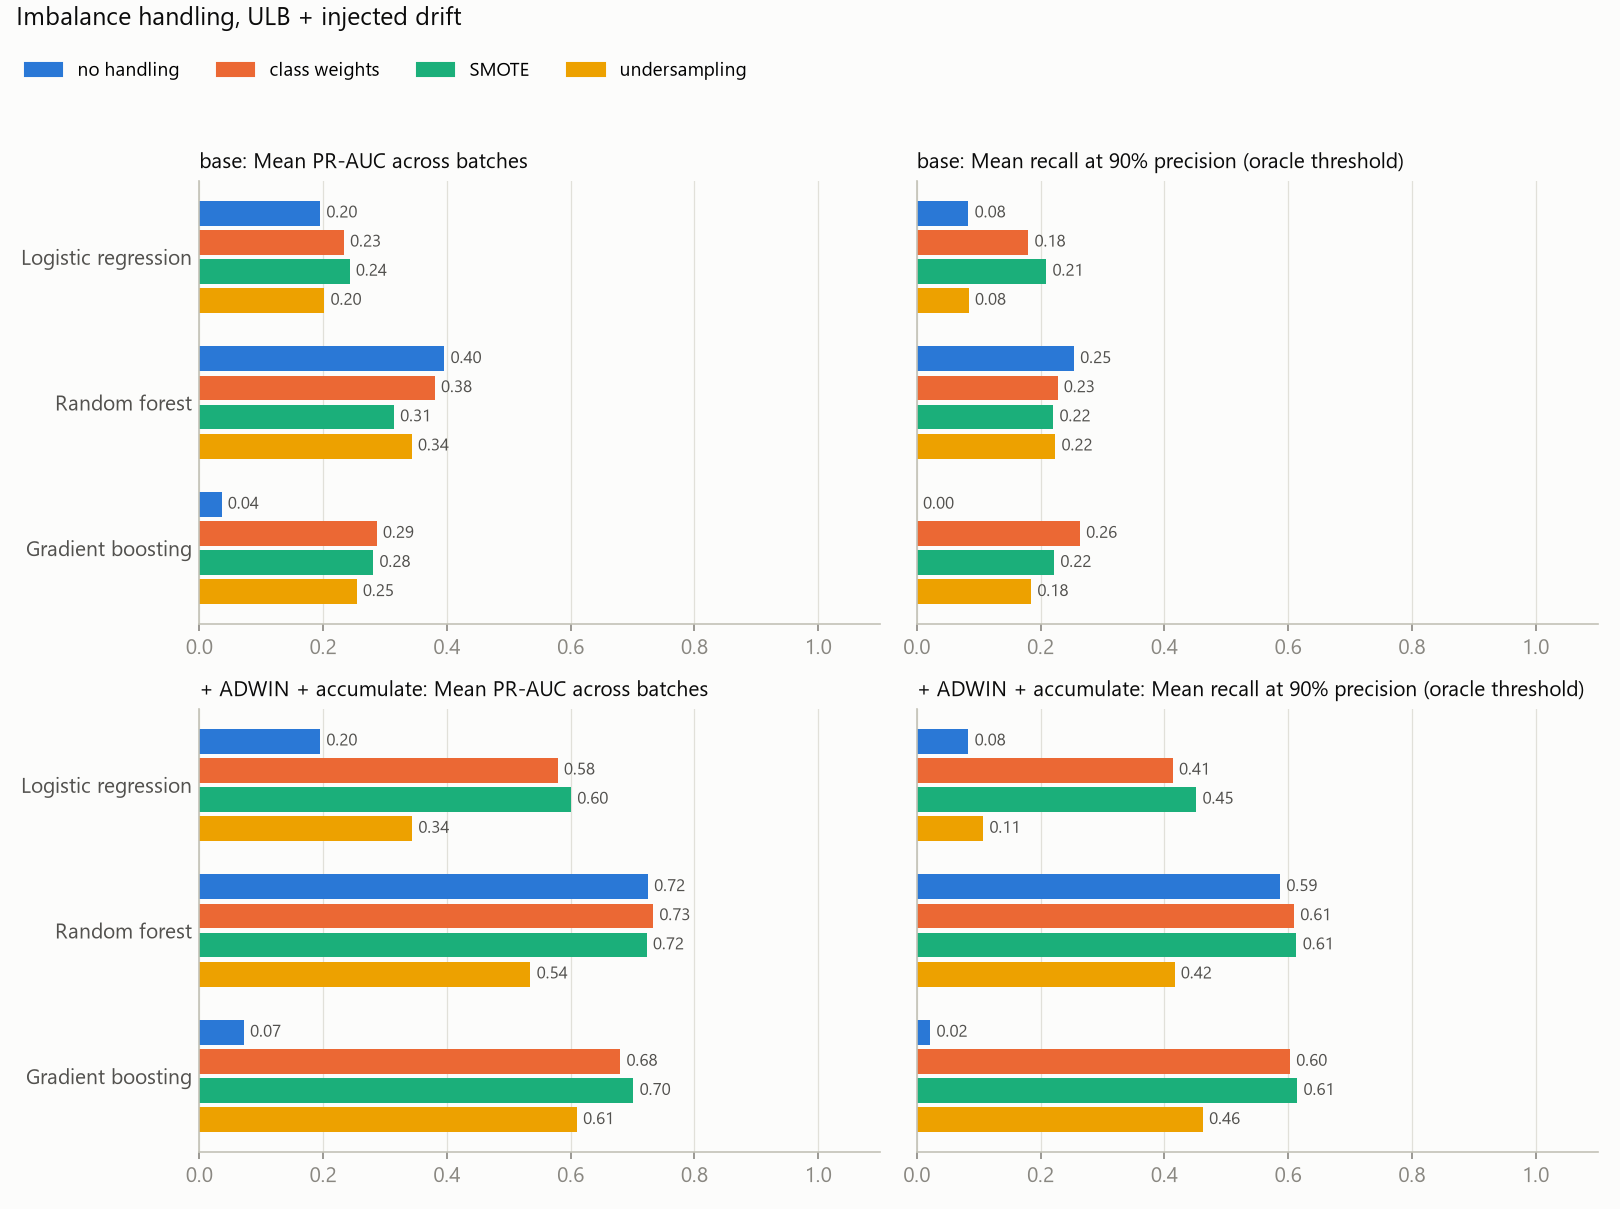

In [61]:
show(plot_grouped_bars, pd.read_csv(f"{R}/creditcard_drift50_imbalance_summary.csv"),
     metrics=["mean_pr_auc", "mean_recall_at_p"], title="Imbalance handling, ULB + injected drift")

**Interpretation (imbalance handling; single runs, seed 42).**
- **Some handling is better than none on real data, but there is no universal winner.**
  - On ULB as recorded, class weights are best for logistic regression (0.598 vs 0.432 with none) and gradient
    boosting (0.741 vs 0.129). SMOTE is marginally ahead for random forest (0.767 vs 0.762).
  - Gradient boosting with no handling collapses to 0.129, so it needs some form of balancing.
- **After the drift, with accumulate** (ULB + drift): SMOTE is best for logistic regression (0.601) and
  gradient boosting (0.701), class weights for random forest (0.733). Random forest with no handling is within
  0.01 of the best (0.725).
- **Undersampling is the cheapest and the weakest after drift.** Random forest with accumulate: 0.535 vs 0.733,
  at 5.9 s vs 19.8 s.
- **On synthetic data differences are small and the order is inconsistent** (the fraud is easy to separate), so
  nothing should be concluded from that dataset.
- **Differences of about 0.01–0.02 are within run-to-run noise** (single seed, no intervals here). Only the
  large gaps (no handling for gradient boosting, undersampling after drift) are reliable.
- **Class weights stay the default** for the main experiments: they are never far from the best and need no
  extra data generation.

### Question 2: How badly does a model that is never updated degrade, and would a standard evaluation notice?

Prequential (test-then-train) evaluation over the time-ordered stream: every batch is scored before the model
may learn from it. This section measures the problem that the adaptive strategies must solve.

#### 2.1 Reported vs deployed: why shuffled evaluation misleads
A model trained once on the earliest 40% of the stream "reports" a test score (random or time-ordered 70/30
split of that 40%) and is then scored on each later 10% of the stream.

In [62]:
rows = {}
for tag in DATASETS:
    raw = pd.read_csv(f"{R}/{tag}_reported_vs_deployed.csv")
    rep = raw[raw["evaluation"] != "deployed"].groupby(["family", "evaluation"])["pr_auc"].mean().unstack()
    dep = raw[raw["evaluation"] == "deployed"]
    drift_pct = DATASETS[tag]["drift_pct"]
    if drift_pct is not None:
        rep["deployed, before drift"] = dep[dep["end_pct"] <= drift_pct].groupby("family")["pr_auc"].mean()
        rep["deployed, after drift"] = dep[dep["start_pct"] >= drift_pct].groupby("family")["pr_auc"].mean()
    else:
        rep["deployed, all later data"] = dep.groupby("family")["pr_auc"].mean()
    rows[DATASETS[tag]["label"]] = rep
pd.concat(rows, names=["dataset"]).round(3)

evaluation                                reported, random split  reported, time-ordered split  deployed, before drift  deployed, after drift  deployed, all later data
dataset              family                                                                                                                                            
Synthetic            Gradient boosting                     0.782                         0.770                   0.780                  0.029                       NaN
                     Logistic regression                   0.828                         0.738                   0.797                  0.010                       NaN
                     Random forest                         0.771                         0.730                   0.769                  0.014                       NaN
ULB + injected drift Gradient boosting                     0.883                         0.768                   0.789                  0.006                       NaN
                     Logistic regression                   0.673                         0.710                   0.734                  0.004                       NaN
                     Random forest                         0.888                         0.813                   0.715                  0.069                       NaN
ULB as recorded      Gradient boosting                     0.883                         0.768                     NaN                    NaN                     0.731
                     Logistic regression                   0.673                         0.710                     NaN                    NaN                     0.726
                     Random forest                         0.888                         0.813                     NaN                    NaN                     0.765

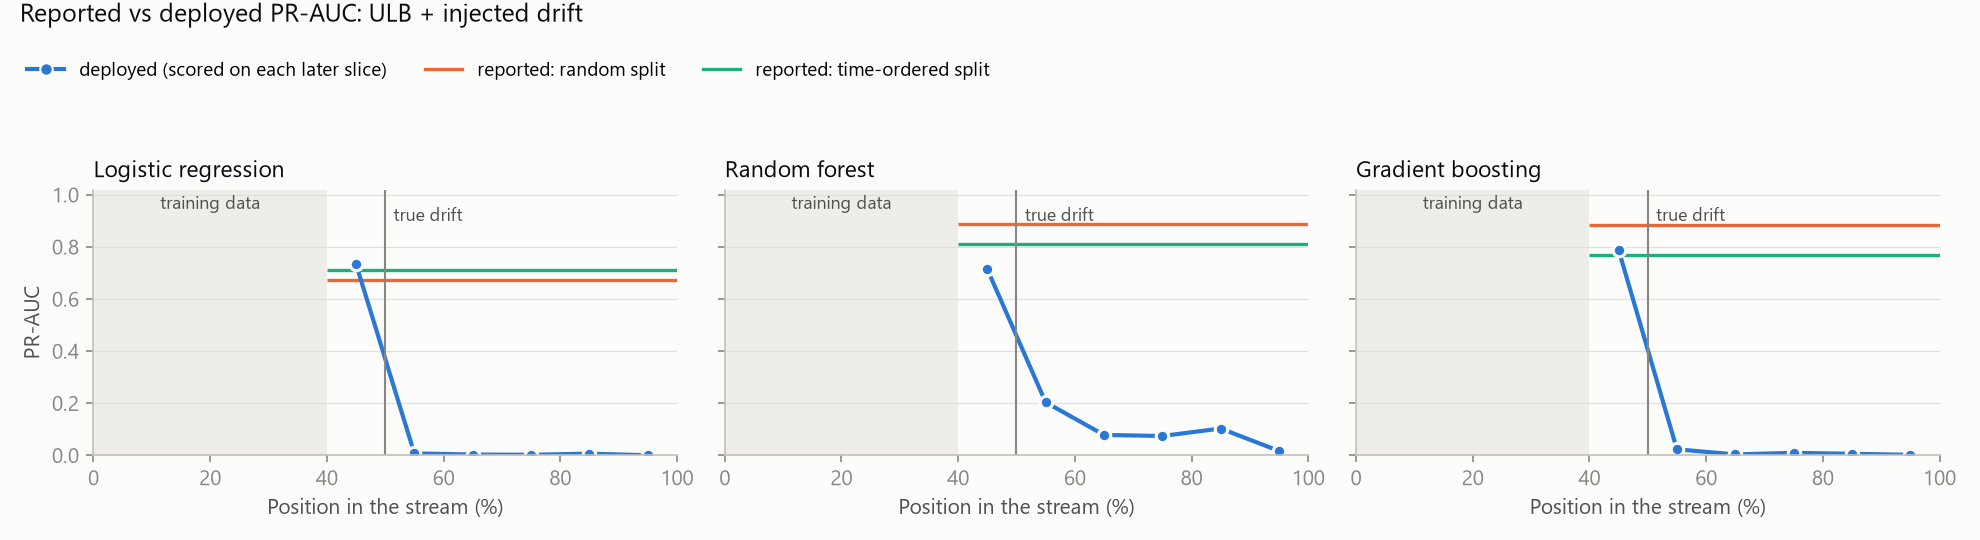

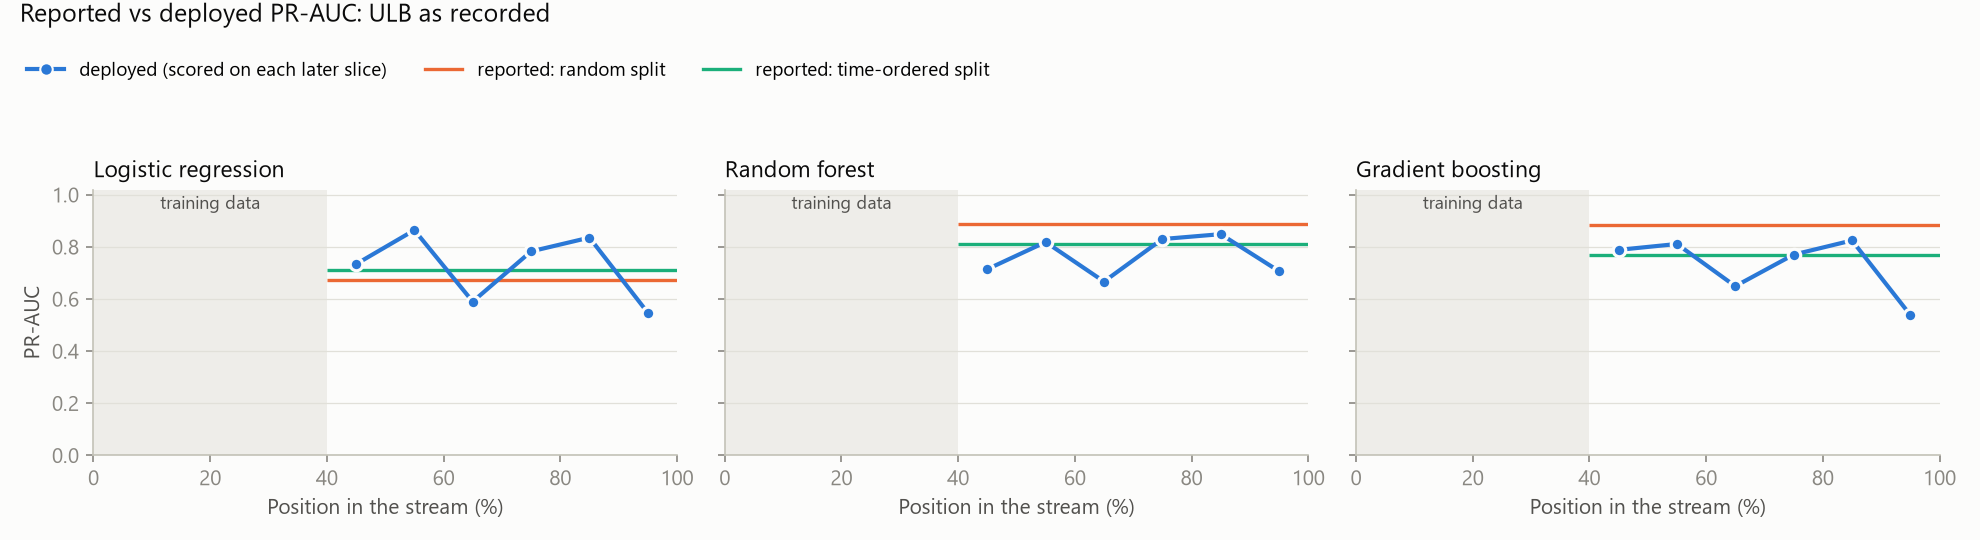

In [63]:
for tag in ["creditcard_drift50", "creditcard"]:
    raw = pd.read_csv(f"{R}/{tag}_reported_vs_deployed.csv")
    show(plot_reported_vs_deployed, raw, train_pct=40, drift_pct=DATASETS[tag]["drift_pct"],
         title=f"Reported vs deployed PR-AUC: {DATASETS[tag]['label']}")

**Interpretation (reported vs deployed).**
- **The headline: a good test score says nothing about behaviour after the drift.** On ULB + drift, models
  that "report" 0.67–0.89 PR-AUC deploy at 0.004–0.069 once the drift hits (gradient boosting 0.006,
  logistic regression 0.004, random forest 0.069). Synthetic data shows the same (0.010–0.029).
- **Before the drift the reports are roughly right**, for the time-ordered split: synthetic 0.73–0.77 reported
  vs 0.77–0.80 deployed.
- **A random split is optimistic for the trees on ULB.** Random forest reports 0.888 with a random split,
  0.813 time-ordered, and then deploys at 0.715 before the drift. Gradient boosting: 0.883, 0.768, 0.789.
  The cause is not established (it is not duplicated rows, which were checked; fraud arriving in bursts is a
  hypothesis).
- **Logistic regression is the exception on ULB:** its random-split report (0.673) is below its deployed score
  (0.734), so the optimism is not universal.
- **Practical rule:** evaluate on time-ordered data and keep testing after deployment. Neither split can warn of
  a drift that has not happened yet.

#### 2.2 Performance over time, batch by batch (3-batch rolling mean; dots = drift alarms)

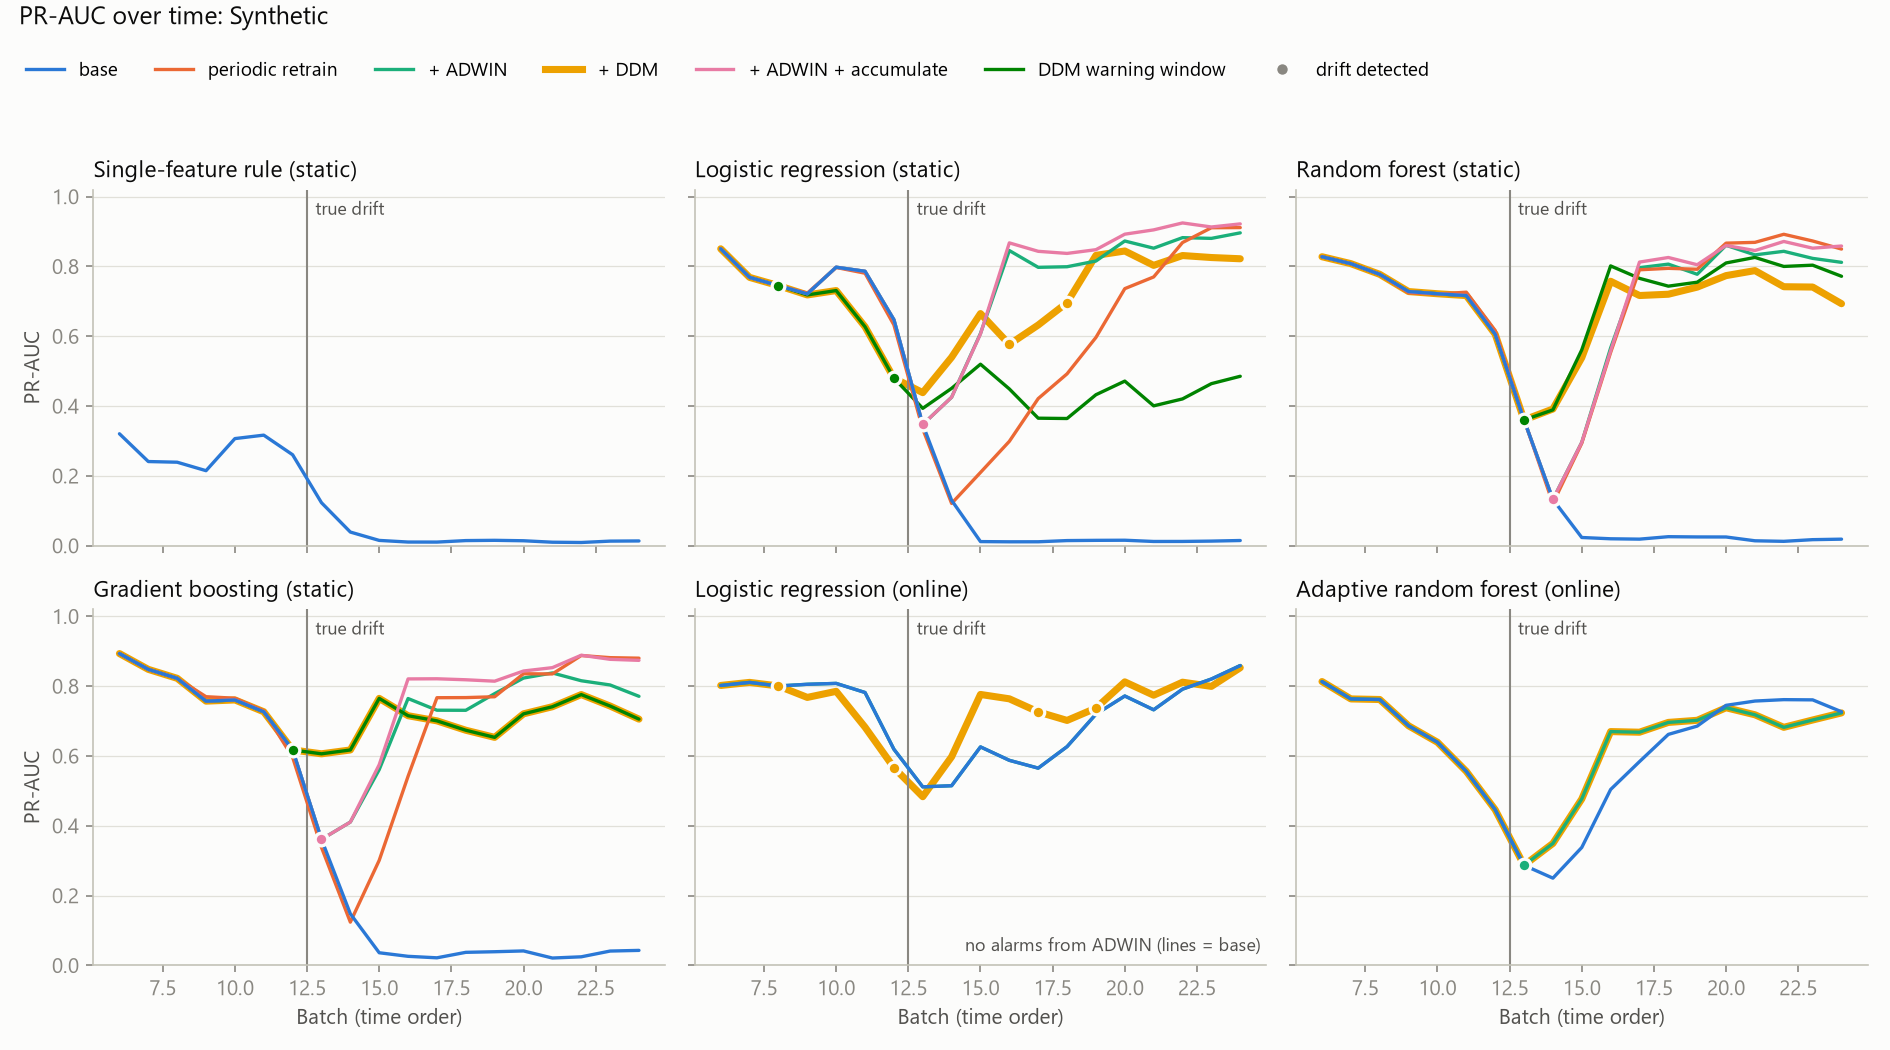

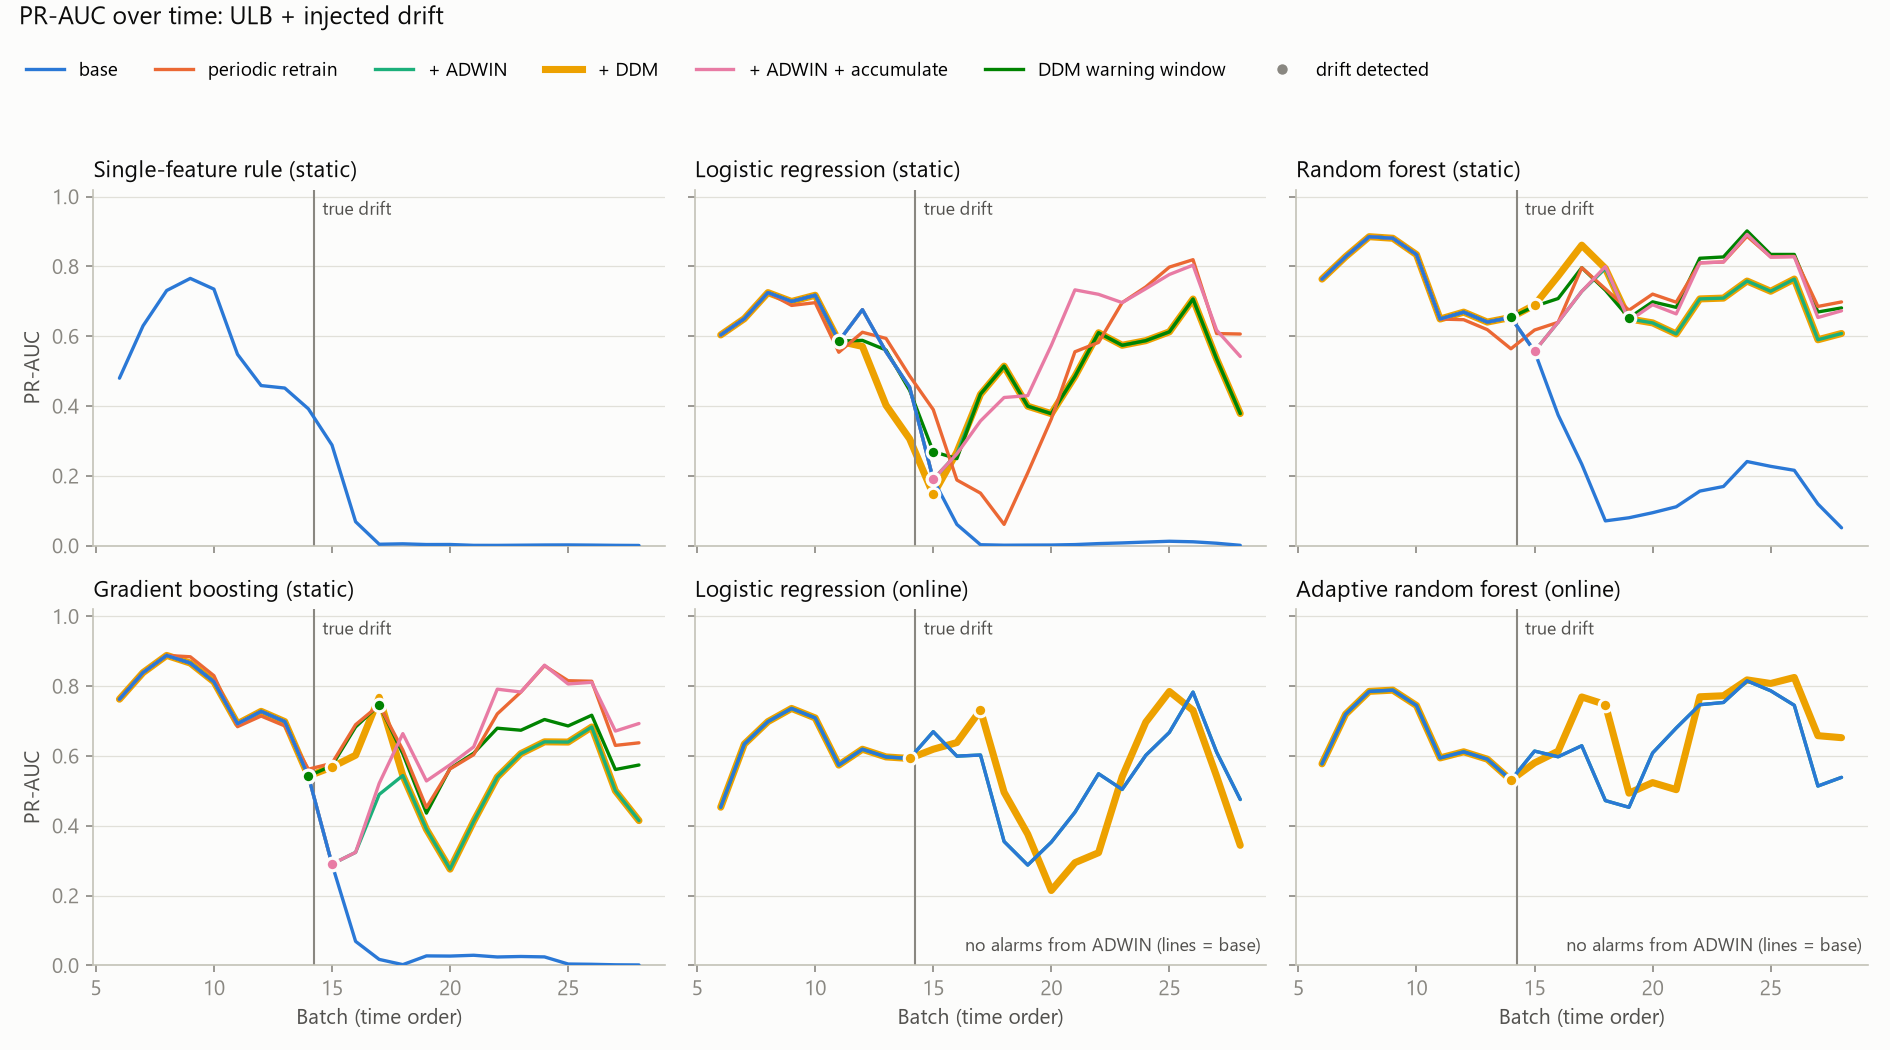

In [64]:
for tag in ["synthetic", "creditcard_drift50"]:
    summary, runs = data[tag]
    show(plot_metric_over_time, runs, metric="pr_auc", drift_batch=DATASETS[tag]["drift_batch"],
         title=f"PR-AUC over time: {DATASETS[tag]['label']}")

#### 2.3 How much performance is lost after the drift? (development scenario, seed 42)

In [65]:
def response(tag):
    summary, runs = data[tag]
    return drift_response_table(runs, DATASETS[tag]["drift_batch"]).merge(
        summary[["model_name", "family", "strategy"]], on="model_name")

cols = ["before", "after", "drop", "drop_pct", "worst_after"]
degradation = pd.concat({DATASETS[t]["label"]: response(t).query("strategy in ['base', 'periodic retrain']")
                         .set_index(["family", "strategy"])[cols] for t in ["synthetic", "creditcard_drift50"]},
                        names=["dataset"])
degradation.round(3)

before  after   drop  drop_pct  worst_after
dataset              family                          strategy                                                     
Synthetic            Single-feature rule (static)    base               0.278  0.014  0.265    95.141        0.009
                     Logistic regression (static)    base               0.766  0.014  0.752    98.235        0.011
                                                     periodic retrain   0.763  0.596  0.167    21.883        0.011
                     Random forest (static)          base               0.747  0.021  0.726    97.230        0.013
                                                     periodic retrain   0.752  0.702  0.050     6.664        0.012
                     Gradient boosting (static)      base               0.775  0.035  0.740    95.525        0.021
                                                     periodic retrain   0.776  0.696  0.080    10.323        0.015
                     Logistic regression (online)    base               0.791  0.711  0.080    10.124        0.504
                     Adaptive random forest (online) base               0.659  0.621  0.038     5.755        0.095
ULB + injected drift Single-feature rule (static)    base               0.603  0.003  0.600    99.575        0.001
                     Logistic regression (static)    base               0.640  0.005  0.635    99.160        0.001
                                                     periodic retrain   0.646  0.502  0.145    22.358        0.061
                     Random forest (static)          base               0.760  0.156  0.604    79.467        0.051
                                                     periodic retrain   0.752  0.762 -0.010    -1.382        0.675
                     Gradient boosting (static)      base               0.777  0.016  0.761    97.953        0.002
                                                     periodic retrain   0.778  0.698  0.080    10.319        0.453
                     Logistic regression (online)    base               0.649  0.524  0.125    19.258        0.288
                     Adaptive random forest (online) base               0.681  0.649  0.032     4.679        0.453

**Interpretation (degradation).** Every frozen model collapses after the swap.
- **ULB + drift, frozen models:** logistic regression falls from 0.640 to 0.005 (−99%), random forest from
  0.760 to 0.156 (−79%) and gradient boosting from 0.777 to 0.016 (−98%).
- **Periodic retraining limits the loss.** Losses are 22% (logistic regression), 10% (gradient boosting) and
  none for random forest (−1.4%).
- **Synthetic data shows the same pattern.** Frozen models lose 95–98%; periodic retraining limits the loss
  to 7–22%.
- **Caveat:** these are single runs with seed 42. The multi-seed numbers are in section 3.2.

#### 2.4 ULB as recorded: slow decay without an injected drift? (PR-AUC trend per 10 batches)

In [66]:
summary, runs = data["creditcard"]
trend = summary.set_index("model_name")[["strategy", "mean_pr_auc", "n_drift_flags", "pr_auc_trend_per_10_batches"]]
trend[trend["strategy"].isin(["base", "periodic retrain"])].round(3)

,strategy,mean_pr_auc,n_drift_flags,pr_auc_trend_per_10_batches
model_name,,,,
rule,base,0.588,0,-0.066
logreg,base,0.598,0,-0.054
logreg_retrain3,periodic retrain,0.625,0,0.015
random_forest,base,0.762,0,-0.030
random_forest_retrain3,periodic retrain,0.771,0,-0.015
gradient_boosting,base,0.741,0,-0.057
gradient_boosting_retrain3,periodic retrain,0.742,0,-0.039
online_logreg,base,0.590,0,-0.049
online_arf,base,0.728,0,0.009


**Interpretation (ULB as recorded).** Without an injected drift, the two days of real data show at most a mild
decay.
- **Static models trend slightly down.** The trend is −0.03 to −0.07 PR-AUC per 10 batches; periodic
  retraining is roughly flat (−0.04 to +0.02).
- **Retraining gains little.** Logistic regression goes from 0.598 to 0.625, random forest from 0.762 to
  0.771 and gradient boosting from 0.741 to 0.742.
- **The trends are not tested for significance.** They come from 23 noisy batches.
- **ADWIN raised no alarm on any static model.** DDM raised one alarm on logistic regression. That refit on a
  single batch lowered its mean PR-AUC from 0.598 to 0.480, a false alarm with a real cost.
- **Why the drift is injected:** the recorded data alone cannot show drift detection. That is why a known drift
  is injected for Questions 2 and 3.

#### 2.5 Drift severity vs performance loss
How does the severity of the drift relate to the loss of performance? Severity is the number of swapped
feature pairs on ULB, and the size of the fraud shift on synthetic data.

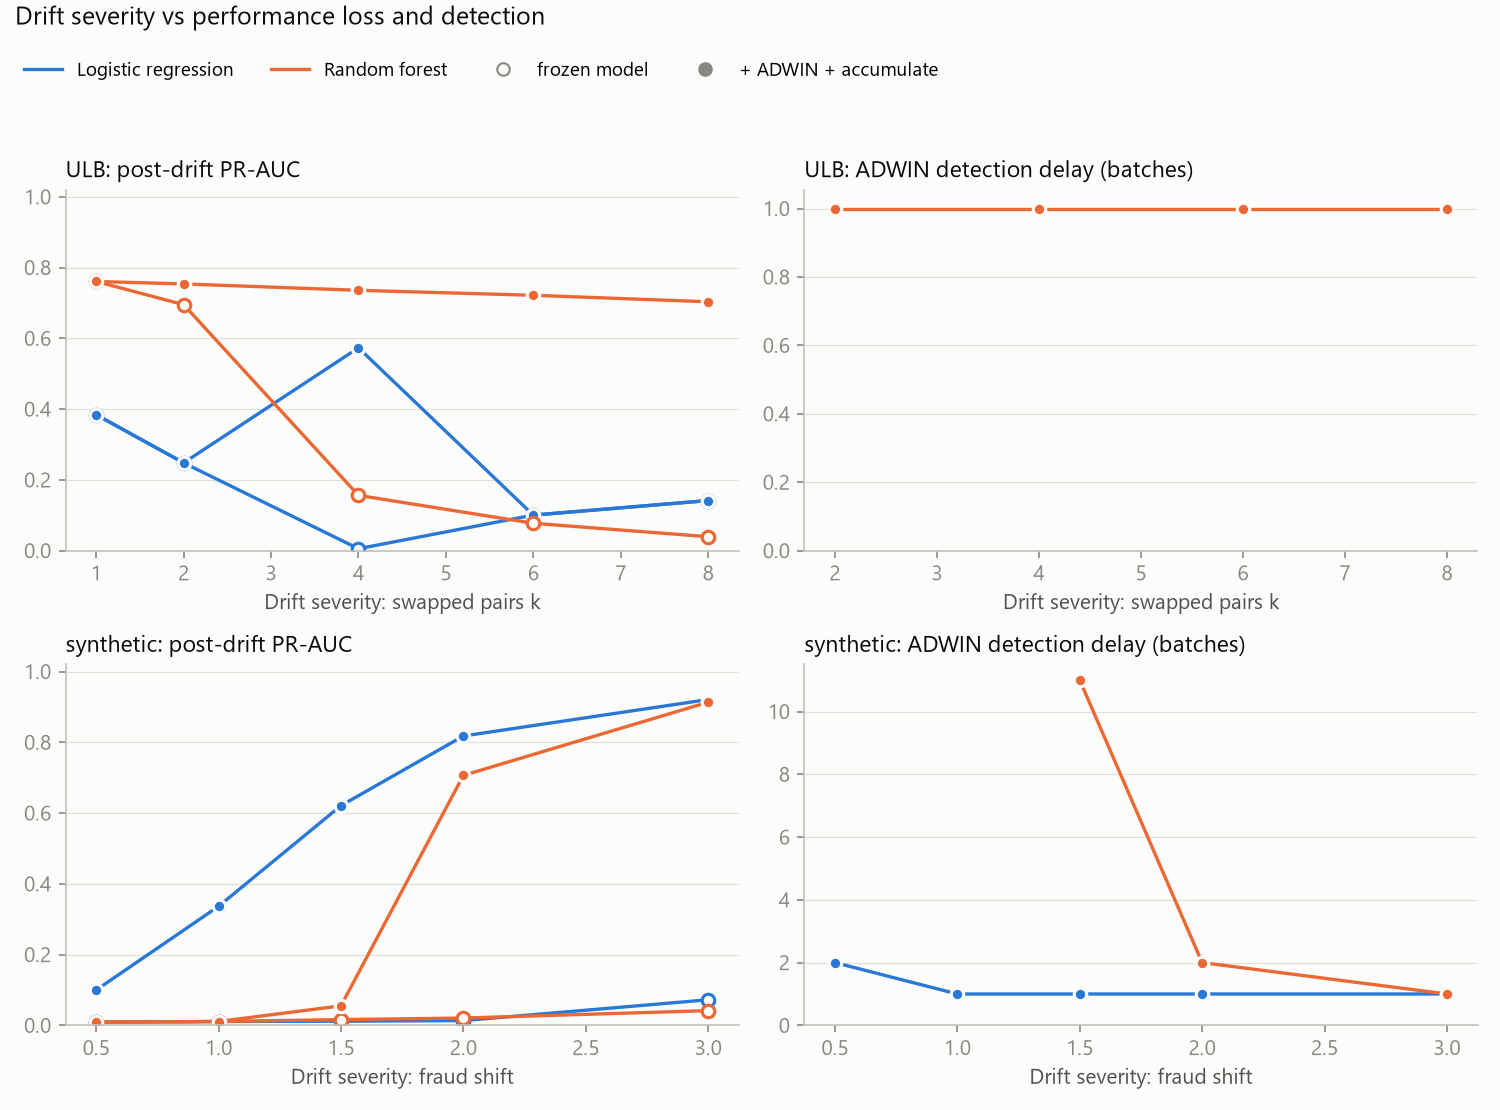

,dataset,axis,level,model,pr_auc_before,frozen_pr_auc_after,frozen_drop_pct,adwin_delay_batches,adwin_false_alarms,accumulate_pr_auc_after,accumulate_recovery_batches
0,ULB,swapped pairs k,1.0,Logistic regression,0.640,0.384,40.002,NaN,0,0.384,9.0
1,ULB,swapped pairs k,1.0,Random forest,0.760,0.761,-0.071,NaN,0,0.761,5.0
2,ULB,swapped pairs k,2.0,Logistic regression,0.640,0.248,61.250,NaN,0,0.248,NaN
3,ULB,swapped pairs k,2.0,Random forest,0.760,0.695,8.539,1.0,0,0.754,5.0
4,ULB,swapped pairs k,4.0,Logistic regression,0.640,0.005,99.160,1.0,0,0.573,6.0
5,ULB,swapped pairs k,4.0,Random forest,0.760,0.156,79.467,1.0,0,0.736,1.0
6,ULB,swapped pairs k,6.0,Logistic regression,0.640,0.100,84.320,NaN,0,0.100,NaN
7,ULB,swapped pairs k,6.0,Random forest,0.760,0.077,89.837,1.0,0,0.722,3.0
8,ULB,swapped pairs k,8.0,Logistic regression,0.640,0.141,77.900,NaN,0,0.141,NaN
9,ULB,swapped pairs k,8.0,Random forest,0.760,0.039,94.832,1.0,0,0.703,3.0


In [67]:
severity = pd.read_csv(f"{R}/severity_summary.csv")
show(plot_severity, severity)
severity.round(3)

**Interpretation (severity; single runs with seed 42).**
- **Random forest's loss grows steadily with severity.** On ULB the loss is none at 1 swapped pair, 9% at 2,
  79% at 4, 90% at 6 and 95% at 8. ADWIN detects every case from 2 pairs upward, 1 batch after the drift.
  Accumulate brings PR-AUC back to 0.70–0.76 at every level.
- **Logistic regression is not monotone.** It loses 40% at k=1, 61% at k=2, 99% at k=4, 84% at k=6 and 78% at
  k=8. ADWIN fires only at k=4, so accumulate rescues only that case (0.573). At the other levels the miss
  rate rises too little for ADWIN to notice with ~13 frauds per batch (section 3.1).
- **On synthetic data every shift level wipes out the frozen model** (86–98% loss).
  - Logistic regression is detected at every level.
  - Random forest is detected only from shift 1.5 upward, 11 batches late at 1.5. At small shifts its
    pre-drift PR-AUC is already low (0.07–0.16), so it misses most frauds even before the drift and the miss
    rate has little room to rise.

### 3. Settings: sensitivity on the development scenarios
Each setting is varied alone on synthetic data and ULB + drift at 50% (the development scenarios) before the
settings are frozen for the held-out evaluation. Mean post-drift PR-AUC over the three static models.

In [68]:
sens = pd.read_csv(f"{R}/sensitivity_summary.csv")
sens["value"] = sens["value"].astype(str)
sens.pivot_table(index=["parameter", "strategy", "dataset"], columns="value", values="pr_auc_after").round(3)

value                                             0.0002  0.002   0.02   10.0    2.0    3.0    5.0    6.0
parameter     strategy             dataset                                                               
accumulate    + ADWIN + accumulate ULB drift 50%     NaN    NaN    NaN  0.674    NaN  0.585    NaN  0.657
                                   synthetic         NaN    NaN    NaN  0.769    NaN  0.762    NaN  0.768
adwin-delta   + ADWIN              ULB drift 50%   0.545  0.545  0.574    NaN    NaN    NaN    NaN    NaN
                                   synthetic       0.698  0.734  0.734    NaN    NaN    NaN    NaN    NaN
              + ADWIN + accumulate ULB drift 50%   0.657  0.657  0.688    NaN    NaN    NaN    NaN    NaN
                                   synthetic       0.718  0.768  0.768    NaN    NaN    NaN    NaN    NaN
retrain-every periodic retrain     ULB drift 50%     NaN    NaN    NaN    NaN  0.636  0.654  0.620    NaN
                                   synthetic         NaN    NaN    NaN    NaN  0.704  0.665  0.594    NaN

**Interpretation (sensitivity).** The rule set beforehand: keep the default unless another value is clearly
better on *both* development datasets.
- **Accumulate size:** 3 is clearly worse on ULB (0.585 vs 0.657). 10 is slightly better on ULB (0.674) and
  equal on synthetic (0.769 vs 0.768). Kept at **6**.
- **Retrain every:** every 2 batches is better on synthetic (0.704 vs 0.665) but worse on ULB (0.636 vs 0.654).
  Every 5 is worse on both. Kept at **3**.
- **ADWIN δ:** 0.0002 is the same as 0.002 on ULB and worse on synthetic.
  - 0.02 raises the ULB means, mostly through gradient boosting (plain ADWIN 0.484 → 0.638).
  - For logistic regression, 0.02 lowers plain ADWIN from 0.473 to 0.406.
  - It makes no difference on synthetic data.
  - Because the gain is not consistent across models, δ was kept at River's default of **0.002**.

These settings were then frozen for every result below.

### Question 3: Which adaptive strategy keeps a fraud model working best, and why?

Post-drift performance, gain in fraud recall, recovery time, false alarms and cost, across development,
held-out and label-delay scenarios with 3 seeds each. Besides periodic retraining, the detector-based
strategies compared on every static model are:
- **`+ ADWIN` / `+ DDM`:** refit on the alarm batch.
- **`DDM warning window`:** the original scheme of Gama et al. (2004). DDM's warning starts a buffer, and at
  the drift a new model is learnt from the examples since the warning.
- **`+ ADWIN + accumulate`:** this project's variant. After an ADWIN alarm, keep refitting on every new batch
  until 6 are gathered.

#### 3.1 Alarms: false alarms and detection delay across all scenarios (mean per run over 3 seeds)

In [69]:
alarm_table = protocol.pivot_table(index=["role", "scenario"], columns="strategy",
                                   values=["false_alarms_per_run", "alarms_after_drift_per_run"], aggfunc="mean",
                                   sort=False)
alarm_table.loc[:, (slice(None), ["+ ADWIN", "+ DDM", "DDM warning window"])].round(2)

false_alarms_per_run                          alarms_after_drift_per_run                         
strategy                              + ADWIN + DDM DDM warning window                    + ADWIN + DDM DDM warning window
role        scenario                                                                                                      
development dev                           0.0  0.25               0.33                       0.75  1.75               1.67
            synthetic                     0.0  0.25               0.11                       0.92  1.25               1.22
held-out    drift30                       0.0  0.00               0.00                       0.75  1.25               1.33
            drift70                       0.0  0.25               0.67                       0.75  0.75               0.67
            k2                            0.0  0.25               0.33                       0.50  1.42               1.33
            k6                            0.0  0.25               0.33                       0.50  1.75               1.67
            random_pairs                  0.0  0.25               0.33                       0.75  1.58               2.00
            gradual                       0.0  0.00               0.00                       0.75  2.00               1.89
label delay delay1                        0.0  0.33               0.33                       0.92  0.92               1.67
            delay3                        0.0  0.08               0.00                       0.92  1.50               2.00

**What the drift signal can see.** The detectors watch one value per fraud: missed or caught at the 0.5
threshold. Frozen models (trained on the 6 warm-up batches), seed 42. First: fraud miss rate and share of
legitimate transactions flagged, before and after each drift. Second: the first ADWIN alarm on the usual
missed-fraud signal vs a preliminary flagged-legitimate signal.

In [70]:
pd.read_csv(f"{R}/detector_blindspot.csv").pivot_table(
    index=["model", "scenario"], columns="period", values=["fraud_miss_rate", "legit_flagged_rate"], sort=False).round(3)

fraud_miss_rate             legit_flagged_rate            
period                        before drift after drift       before drift after drift
model             scenario                                                           
logreg            k2                 0.158       0.342              0.016       0.011
                  k4 (dev)           0.158       0.824              0.016       0.052
                  k6                 0.158       0.367              0.016       0.074
                  drift30            0.121       0.851              0.015       0.046
                  drift70            0.207       0.776              0.015       0.044
                  gradual            0.145       0.690              0.016       0.045
random_forest     k2                 0.347       1.000              0.000       0.000
                  k4 (dev)           0.347       1.000              0.000       0.000
                  k6                 0.347       1.000              0.000       0.000
                  drift30            0.242       1.000              0.000       0.000
                  drift70            0.337       1.000              0.000       0.000
                  gradual            0.303       0.849              0.000       0.000
gradient_boosting k2                 0.287       0.975              0.000       0.000
                  k4 (dev)           0.287       0.990              0.000       0.000
                  k6                 0.287       0.990              0.000       0.000
                  drift30            0.212       0.993              0.000       0.000
                  drift70            0.260       1.000              0.000       0.000
                  gradual            0.263       0.808              0.000       0.000

In [71]:
signals = pd.read_csv(f"{R}/detector_signals.csv")
order = ["missed frauds", "fraud score drop", "alert rate", "mean score"]
table = signals.pivot_table(index=["model", "scenario"], columns="signal", values=["delay_batches", "false_alarms"],
                            sort=False, dropna=False)
table.loc[:, (slice(None), order)]

delay_batches                                         false_alarms                                       
signal                        missed frauds fraud score drop alert rate mean score missed frauds fraud score drop alert rate mean score
model             scenario                                                                                                             
logreg            as recorded           NaN              NaN        NaN        NaN           0.0              0.0        1.0        3.0
                  k2                    NaN              NaN        0.0        0.0           0.0              0.0        0.0        1.0
                  k4 (dev)              1.0              1.0        0.0        0.0           0.0              0.0        0.0        1.0
                  k6                    NaN              NaN        0.0        0.0           0.0              0.0        0.0        1.0
                  drift30               3.0              2.0        0.0        1.0           0.0              0.0        0.0        0.0
                  drift70               3.0              3.0        1.0        1.0           0.0              0.0        1.0        3.0
                  gradual               6.0              4.0        3.0        3.0           0.0              0.0        0.0        1.0
random_forest     as recorded           NaN              NaN        NaN        NaN           0.0              0.0        1.0        2.0
                  k2                    1.0              1.0        3.0        1.0           0.0              0.0        0.0        0.0
                  k4 (dev)              1.0              1.0        3.0        1.0           0.0              0.0        0.0        0.0
                  k6                    1.0              1.0        3.0        3.0           0.0              0.0        0.0        0.0
                  drift30               4.0              4.0        3.0        7.0           0.0              0.0        0.0        0.0
                  drift70               3.0              3.0        NaN        NaN           0.0              0.0        1.0        2.0
                  gradual               8.0             10.0        4.0        4.0           0.0              0.0        0.0        0.0
gradient_boosting as recorded           NaN              NaN        NaN        NaN           0.0              0.0        1.0        1.0
                  k2                    1.0              1.0        3.0        3.0           0.0              0.0        0.0        0.0
                  k4 (dev)              1.0              1.0        3.0        4.0           0.0              0.0        0.0        0.0
                  k6                    1.0              1.0        3.0        3.0           0.0              0.0        0.0        0.0
                  drift30               4.0              4.0        4.0        4.0           0.0              0.0        0.0        0.0
                  drift70               3.0              3.0        8.0        7.0           0.0              0.0        1.0        1.0
                  gradual               9.0              8.0        4.0        4.0           0.0              0.0        0.0        0.0

**Interpretation (alarms).**
- **ADWIN raised no false alarms in any scenario.** On the tree models it fired exactly once after the drift in
  every scenario and seed. The count includes the batch that contains the drift point.
- **DDM and the DDM warning window raise false alarms only on logistic regression.** That is about 1 per run on
  most ULB scenarios and 0.33 on synthetic. On the tree models they often fire twice after the drift.
- **ADWIN misses the 2- and 6-pair swaps on logistic regression.** The tables above show why.
  - Random forest misses *every* fraud after a swap (miss rate 0.35 → 1.00), so the signal jumps and the
    missed-fraud ADWIN fires one batch after the drift batch.
  - Logistic regression's miss rate only doubles (0.16 → 0.34 at k=2, 0.37 at k=6). With ~13 frauds per batch
    that rise is too small for ADWIN at δ = 0.002, so it never fires. After a 4-pair swap the miss rate jumps to
    0.82 and ADWIN fires.
  - So the limit is the *amount of evidence*: one value per fraud, and frauds are rare.
- **Would a different signal detect sooner?** The second table compares four signals, each watched by ADWIN, on
  frozen models (seed 42). The delay is in batches after the drift batch.
  - **Fraud score drop** keeps *how confident* the model was on each fraud, not just caught or missed. It helps
    only slightly (logistic regression: 2 instead of 3 batches at drift 30%, 4 instead of 6 for gradual drift),
    and it still misses the 2- and 6-pair swaps.
  - **Label-free signals** (alert rate, mean score) use every transaction, ~10,000 per batch, and need no fraud
    labels.
    - For logistic regression they detect every drift within 0–3 batches, including the swaps the other
      signals miss.
    - For the tree models they are often *slower* on abrupt drifts (3 instead of 1 batch) and sometimes miss a
      drift. They are faster only on the gradual drift (4 instead of 8–9).
    - They also raise 1–3 false alarms on the undrifted data, because the score distribution moves naturally
      over the day.
  - **No signal is better everywhere.** Combining a label-based and a label-free signal is a natural next step,
    but untested; these are offline checks on frozen models, not results of any strategy.
- **Correction:** an earlier version of this diagnostic accidentally used `Time` as a model feature. That made
  logistic regression appear to flag 39–49% of legitimate transactions after a swap. The main experiments were
  never affected: they use the stream's feature list, which excludes `Time`.

#### 3.2 Which strategy recovers best? Post-drift PR-AUC across scenarios (mean of 3 seeds)
Development scenarios shaped the method; **held-out** scenarios did not.

In [72]:
static = protocol[protocol["family"].str.contains("static") & ~protocol["family"].str.contains("rule")]
post = static.pivot_table(index=["role", "scenario", "family"], columns="strategy", values="pr_auc_after", sort=False)
ordered(post).round(3)

strategy                                                base  periodic retrain  + ADWIN  + DDM  DDM warning window  + ADWIN + accumulate
role        scenario     family                                                                                                         
development dev          Logistic regression (static)  0.005             0.502    0.473  0.473               0.473                 0.573
                         Random forest (static)        0.168             0.770    0.680  0.702               0.702                 0.735
                         Gradient boosting (static)    0.016             0.698    0.484  0.543               0.644                 0.662
            synthetic    Logistic regression (static)  0.009             0.596    0.748  0.421               0.421                 0.788
                         Random forest (static)        0.012             0.660    0.504  0.687               0.697                 0.543
                         Gradient boosting (static)    0.015             0.668    0.662  0.722               0.675                 0.690
held-out    drift30      Logistic regression (static)  0.004             0.561    0.356  0.673               0.673                 0.552
                         Random forest (static)        0.187             0.743    0.570  0.674               0.707                 0.644
                         Gradient boosting (static)    0.018             0.662    0.325  0.672               0.672                 0.547
            drift70      Logistic regression (static)  0.007             0.488    0.407  0.612               0.557                 0.483
                         Random forest (static)        0.157             0.696    0.554  0.544               0.558                 0.569
                         Gradient boosting (static)    0.010             0.619    0.486  0.486               0.496                 0.506
            k2           Logistic regression (static)  0.248             0.538    0.248  0.473               0.473                 0.248
                         Random forest (static)        0.639             0.782    0.691  0.695               0.694                 0.757
                         Gradient boosting (static)    0.039             0.707    0.483  0.544               0.607                 0.662
            k6           Logistic regression (static)  0.100             0.491    0.100  0.473               0.473                 0.100
                         Random forest (static)        0.073             0.773    0.658  0.700               0.699                 0.718
                         Gradient boosting (static)    0.018             0.682    0.484  0.542               0.595                 0.663
            random_pairs Logistic regression (static)  0.001             0.533    0.274  0.473               0.461                 0.599
                         Random forest (static)        0.524             0.757    0.694  0.693               0.693                 0.760
                         Gradient boosting (static)    0.342             0.744    0.526  0.546               0.543                 0.710
            gradual      Logistic regression (static)  0.102             0.522    0.412  0.502               0.514                 0.502
                         Random forest (static)        0.272             0.738    0.584  0.686               0.699                 0.600
                         Gradient boosting (static)    0.149             0.638    0.493  0.650               0.609                 0.492
label delay delay1       Logistic regression (static)  0.005             0.438    0.430  0.429               0.429                 0.534
                         Random forest (static)        0.168             0.721    0.625  0.739               0.678                 0.685
                         Gradient boosting (static)    0.016             0.617    0.429  0.630               0.576                 0.591
            delay3       Lo

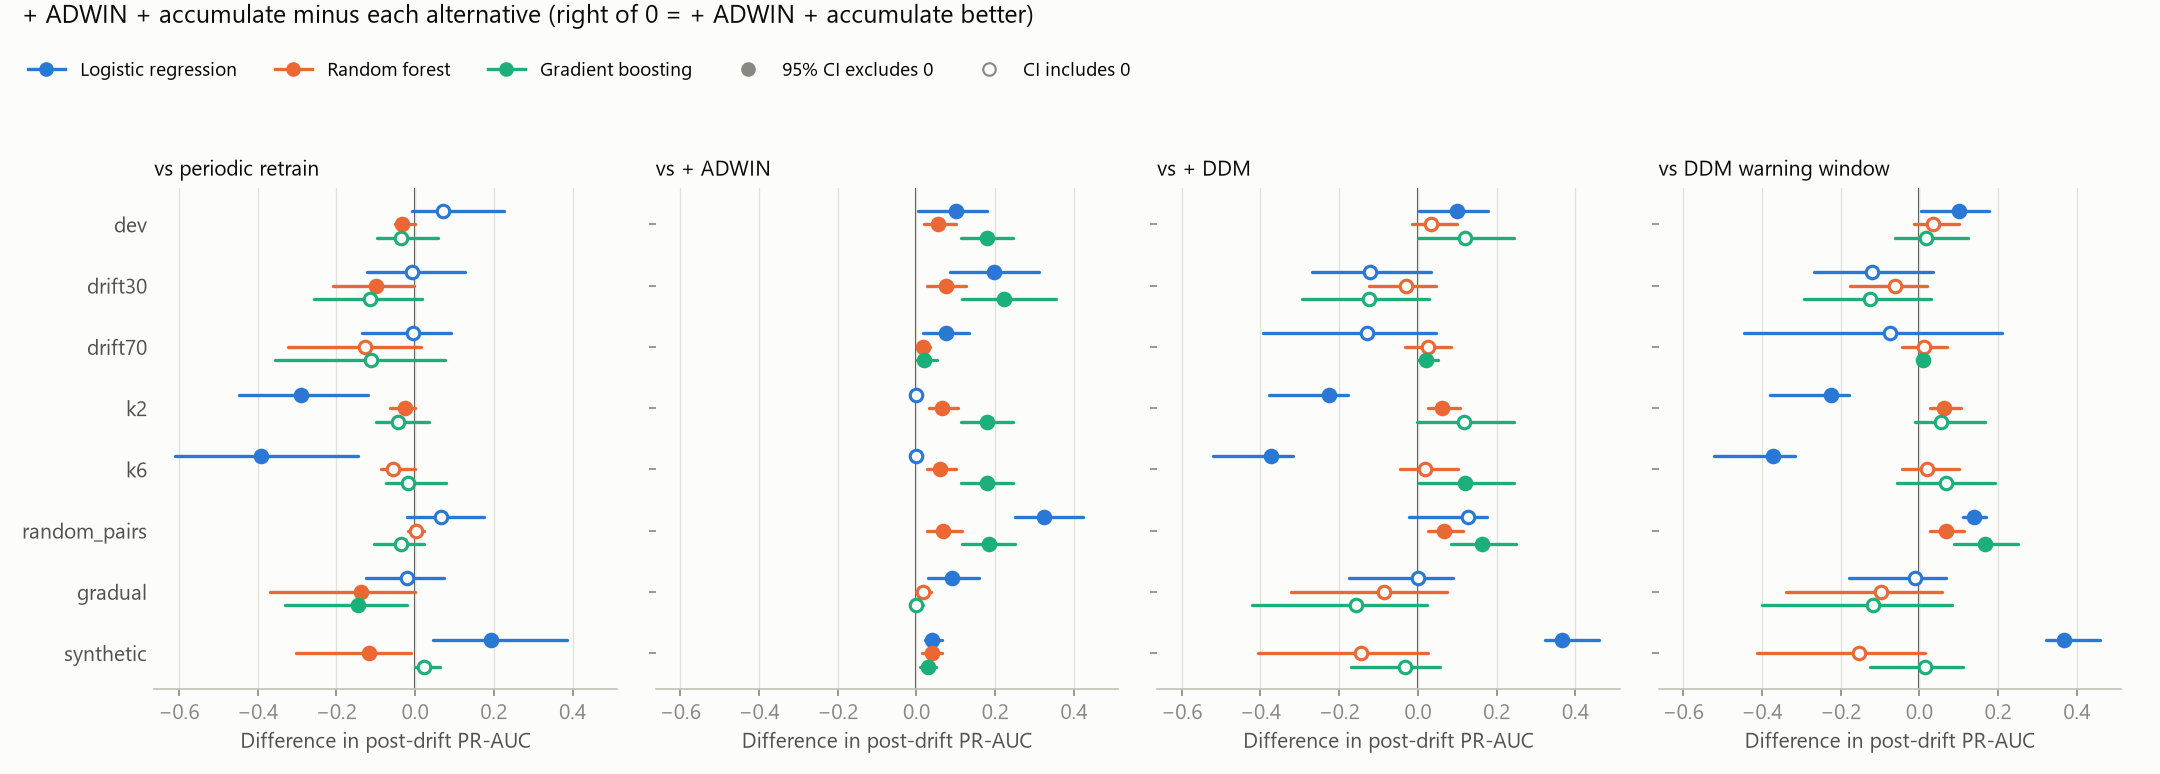

In [73]:
show(plot_comparison_intervals, comparisons[comparisons["role"] != "label delay"], reference="+ ADWIN + accumulate")

In [74]:
c = comparisons[comparisons["vs"] != "base"].copy()
c["outcome"] = np.select([c["lo"] > 0, c["hi"] < 0], ["accumulate better", "accumulate worse"], "no significant difference")
c.pivot_table(index=["role", "vs"], columns="outcome", values="mean", aggfunc="size", fill_value=0)

outcome                         accumulate better  accumulate worse  no significant difference
role        vs                                                                                
development + ADWIN                             6                 0                          0
            + DDM                               2                 0                          4
            DDM warning window                  2                 0                          4
            periodic retrain                    1                 2                          3
held-out    + ADWIN                            14                 0                          4
            + DDM                               5                 2                         11
            DDM warning window                  5                 2                         11
            periodic retrain                    0                 6                         12
label delay + ADWIN                             5                 0                          1
            + DDM                               1                 0                          5
            DDM warning window                  1                 0                          5
            periodic retrain                    1                 0                          5

**Interpretation (which strategy recovers best).** The forest plot compares accumulate with each other
strategy (difference in post-drift PR-AUC, block-bootstrap 95% interval; a filled marker means the interval
excludes zero).

1. **Accumulating after an alarm beats refitting on the alarm batch alone.** Accumulate is significantly better
   than plain ADWIN in 14 of 18 held-out comparisons and never worse. This holds across models, drift
   positions, swap sizes and gradual drift, so the ablation is robust.
2. **It does not beat periodic retraining.**
   - On held-out scenarios it is never significantly better than periodic retraining: 12 differences are not
     significant and 6 are significantly worse (3 on random forest, 2 on logistic regression and 1 on gradient
     boosting).
   - Mean held-out post-drift PR-AUC is 0.649 for periodic retraining vs 0.562 for accumulate.
3. **Against DDM and the DDM warning window (prior art) the result is mixed:** 5 better, 11 not significant and
   2 worse, each. Both losses are logistic regression on k=2 and k=6, where ADWIN never fired.
4. **The development scenarios flattered the method.** On them, accumulate had the best mean (0.665). On
   held-out scenarios it fell to 0.562, behind periodic retraining, DDM (0.591) and the DDM warning window
   (0.596). Without the held-out protocol, the development numbers would have suggested a conclusion that
   does not generalise.

#### 3.3 Recall gain after the drift (operational threshold, mean of 3 seeds)

In [75]:
op = static.pivot_table(index=["role", "scenario", "family"], columns="strategy", values="op_recall_after", sort=False)
gain = ordered(op).sub(op["base"], axis=0).drop(columns="base")
gain.groupby(level="role", sort=False).mean().round(3)

strategy,periodic retrain,+ ADWIN,+ DDM,DDM warning window,+ ADWIN + accumulate
role,,,,,
development,0.456,0.343,0.346,0.352,0.478
held-out,0.434,0.236,0.334,0.326,0.361
label delay,0.342,0.230,0.279,0.261,0.381


In [76]:
ordered(op).round(3)

strategy                                                base  periodic retrain  + ADWIN  + DDM  DDM warning window  + ADWIN + accumulate
role        scenario     family                                                                                                         
development dev          Logistic regression (static)  0.000             0.406    0.233  0.234               0.234                 0.456
                         Random forest (static)        0.002             0.584    0.398  0.494               0.488                 0.540
                         Gradient boosting (static)    0.000             0.537    0.260  0.316               0.418                 0.512
            synthetic    Logistic regression (static)  0.000             0.374    0.490  0.179               0.179                 0.571
                         Random forest (static)        0.000             0.407    0.283  0.403               0.409                 0.343
                         Gradient boosting (static)    0.000             0.429    0.397  0.448               0.384                 0.449
held-out    drift30      Logistic regression (static)  0.001             0.539    0.247  0.495               0.495                 0.403
                         Random forest (static)        0.011             0.590    0.313  0.550               0.548                 0.486
                         Gradient boosting (static)    0.004             0.471    0.196  0.521               0.521                 0.361
            drift70      Logistic regression (static)  0.000             0.427    0.340  0.507               0.246                 0.448
                         Random forest (static)        0.000             0.568    0.421  0.379               0.406                 0.424
                         Gradient boosting (static)    0.000             0.493    0.334  0.334               0.405                 0.425
            k2           Logistic regression (static)  0.101             0.437    0.101  0.233               0.234                 0.101
                         Random forest (static)        0.390             0.610    0.462  0.509               0.509                 0.616
                         Gradient boosting (static)    0.006             0.558    0.260  0.373               0.473                 0.517
            k6           Logistic regression (static)  0.084             0.382    0.084  0.234               0.239                 0.084
                         Random forest (static)        0.002             0.597    0.397  0.483               0.473                 0.557
                         Gradient boosting (static)    0.005             0.518    0.278  0.332               0.337                 0.535
            random_pairs Logistic regression (static)  0.001             0.413    0.299  0.233               0.209                 0.455
                         Random forest (static)        0.287             0.566    0.469  0.516               0.515                 0.606
                         Gradient boosting (static)    0.174             0.513    0.342  0.375               0.374                 0.608
            gradual      Logistic regression (static)  0.037             0.413    0.212  0.298               0.304                 0.317
                         Random forest (static)        0.071             0.518    0.386  0.442               0.477                 0.426
                         Gradient boosting (static)    0.088             0.465    0.364  0.462               0.357                 0.387
label delay delay1       Logistic regression (static)  0.001             0.326    0.251  0.307               0.251                 0.412
                         Random forest (static)        0.002             0.457    0.386  0.461               0.393                 0.524
                         Gradient boosting (static)    0.001             0.433    0.236  0.314               0.323                 0.441
            delay3       Lo

**Interpretation (recall gain).** Gain in operational recall after the drift over the frozen model, in the
mean of the held-out scenarios:

| Strategy | Gain in operational recall |
|---|---|
| periodic retraining | +0.43 |
| accumulate | +0.36 |
| DDM | +0.33 |
| DDM warning window | +0.33 |
| plain ADWIN | +0.24 |

- **Every adaptive strategy recovers a large share of the minority-class recall** that the frozen model loses
  (about 0.07 on held-out scenarios).
- **The ranking matches the PR-AUC result.** Periodic retraining leads on held-out data, and accumulate leads
  on the development and label-delay scenarios (+0.48 and +0.38).

#### 3.4 Recovery time (development scenario, seed 42)
Batches from the drift until the 3-batch rolling PR-AUC is back at 90% of the model's own pre-drift level, after
having dropped (0 = never dropped; NaN = never recovered).

In [77]:
rec = pd.concat({DATASETS[t]["label"]: response(t) for t in ["synthetic", "creditcard_drift50"]}, names=["dataset"])
rec = rec.reset_index(level=0)
rec[rec["family"].str.contains("static")].pivot_table(index=["dataset", "family"], columns="strategy",
                                                       values="recovery_batches", sort=False).pipe(ordered)

strategy                                           periodic retrain  + ADWIN  + DDM  DDM warning window  + ADWIN + accumulate
dataset              family                                                                                                  
Synthetic            Logistic regression (static)               7.0      3.0    1.0                 NaN                   3.0
                     Random forest (static)                     4.0      4.0    3.0                 3.0                   4.0
                     Gradient boosting (static)                 4.0      3.0    7.0                 7.0                   3.0
ULB + injected drift Logistic regression (static)               7.0      7.0    7.0                 7.0                   6.0
                     Random forest (static)                     5.0      1.0    7.0                 5.0                   1.0
                     Gradient boosting (static)                 7.0      NaN    NaN                 9.0                   7.0

**Interpretation (recovery time; single runs, so treat as indicative).**
- **Frozen models never recover.**
- **ULB + drift.** On random forest, ADWIN and accumulate are back within 1 batch, against 5 for periodic
  retraining. On logistic regression all strategies take 6–7 batches. On gradient boosting plain ADWIN and DDM
  never get back to 90% of the pre-drift level, while accumulate and periodic retraining take 7 batches.
- **Synthetic.** Most strategies recover in 3–4 batches. The DDM warning window never recovers on logistic
  regression (post-drift PR-AUC 0.443). It had already raised a false alarm before the drift.

#### 3.5 Label delay
Labels reach the models and detectors 1 or 3 batches (10,000–30,000 transactions) after scoring, instead of
immediately. ULB + drift at 50%, mean of 3 seeds.

In [78]:
delay = protocol[protocol["scenario"].isin(["dev", "delay1", "delay3"]) & protocol["family"].str.contains("static")
                 & ~protocol["family"].str.contains("rule")]
ordered(delay.pivot_table(index=["family", "scenario"], columns="strategy", values="pr_auc_after", sort=False)).round(3)

strategy                                base  periodic retrain  + ADWIN  + DDM  DDM warning window  + ADWIN + accumulate
family                       scenario                                                                                   
Logistic regression (static) dev       0.005             0.502    0.473  0.473               0.473                 0.573
                             delay1    0.005             0.438    0.430  0.429               0.429                 0.534
                             delay3    0.005             0.352    0.363  0.364               0.363                 0.428
Random forest (static)       dev       0.168             0.770    0.680  0.702               0.702                 0.735
                             delay1    0.168             0.721    0.625  0.739               0.678                 0.685
                             delay3    0.168             0.606    0.529  0.635               0.571                 0.581
Gradient boosting (static)   dev       0.016             0.698    0.484  0.543               0.644                 0.662
                             delay1    0.016             0.617    0.429  0.630               0.576                 0.591
                             delay3    0.016             0.494    0.367  0.505               0.477                 0.484

**Interpretation (label delay).**
- **Delayed labels cost every strategy.** With a 3-batch delay, post-drift PR-AUC falls by about 0.1–0.2. For
  example, random forest with periodic retraining drops from 0.77 to 0.61, and gradient boosting with
  accumulate from 0.66 to 0.48.
- **The ranking mostly survives.** Accumulate stays best for logistic regression (0.57 → 0.53 → 0.43).
- **DDM moves to the top for the trees.** It reaches 0.64 for random forest and 0.51 for gradient boosting
  at a 3-batch delay.
- **On the paired intervals, accumulate still beats plain ADWIN** (5 of 6 comparisons) but is not
  significantly different from periodic retraining or DDM in most cases.
- **Why this matters:** fraud labels in practice arrive days to weeks late, so the immediate-label numbers
  elsewhere in this notebook are optimistic.

#### 3.6 Cost: refits and runtime (development scenario, seed 42)

In [79]:
summary, runs = data["creditcard_drift50"]
cost = summary[summary["family"].str.contains("static") & ~summary["family"].str.contains("rule")]
cost.pivot_table(index="family", columns="strategy", values=["runtime_s", "n_drift_flags"], sort=False).round(1)

runtime_s                                                                        n_drift_flags                                                                       
strategy                          base periodic retrain + ADWIN + DDM + ADWIN + accumulate DDM warning window          base periodic retrain + ADWIN + DDM + ADWIN + accumulate DDM warning window
family                                                                                                                                                                                            
Logistic regression (static)       0.8              3.3     0.8   0.9                  2.0                1.2           0.0              0.0     1.0   2.0                  1.0                2.0
Random forest (static)             5.3             29.7     6.4   7.1                 15.8               12.5           0.0              0.0     1.0   2.0                  1.0                2.0
Gradient boosting (static)         8.3             63.0    14.1  18.7                 48.0               22.4           0.0              0.0     1.0   2.0                  1.0                2.0

**Interpretation (cost).**
- **Periodic retraining is the most expensive strategy.** It refits on a fixed schedule whether or not anything
  changed: 29.7 s for random forest and 63.0 s for gradient boosting over the stream.
- **Accumulate refits only after an alarm** (1 alarm plus 5 further refits): 15.8 s and 48.0 s.
- **Plain ADWIN and DDM add almost nothing over the frozen model.**
- **For these small models the difference is seconds,** so cost does not change the recommendation. It would
  matter for larger models or more frequent batches.

### 4. Error analysis (ULB + drift, random forest, operational threshold)
Which frauds are missed, what the alerts cost, and why DDM raises false alarms.

In [80]:
pd.read_csv(f"{R}/creditcard_drift50_errors_confusion.csv").round(3)

,strategy,period,transactions,TP,FN,FP,TN,recall,precision,alerts_per_10k,fraud_amount_caught_pct
0,frozen,after drift,134807,0,199,1,134607,0.000,0.000,0.074,0.000
1,frozen,before drift,70000,68,21,9,69902,0.764,0.883,11.000,84.641
2,+ ADWIN + accumulate,after drift,134807,91,108,16,134592,0.457,0.850,7.937,51.177
3,+ ADWIN + accumulate,before drift,70000,68,21,9,69902,0.764,0.883,11.000,84.641
4,+ DDM,after drift,134807,106,93,13,134595,0.533,0.891,8.827,55.661
5,+ DDM,before drift,70000,68,21,9,69902,0.764,0.883,11.000,84.641


In [81]:
pd.read_csv(f"{R}/creditcard_drift50_errors_by_group.csv").pivot_table(
    index=["period", "group"], columns="strategy", values="recall", sort=False).round(3)

strategy                        frozen  + ADWIN + accumulate  + DDM
period       group                                                 
after drift  1 < amount <= 100   0.000                 0.397  0.500
             amount <= 1         0.000                 0.500  0.485
             amount > 100        0.000                 0.491  0.642
             busy hours          0.000                 0.669  0.529
             quiet hours         0.000                 0.000  0.540
before drift 1 < amount <= 100   0.654                 0.654  0.654
             amount <= 1         0.793                 0.793  0.793
             amount > 100        0.824                 0.824  0.824
             busy hours          0.764                 0.764  0.764

In [82]:
alarms = pd.read_csv(f"{R}/creditcard_drift50_errors_alarms.csv")
print("median frauds per batch:", alarms["frauds"].median(), "| median missed share:", round(alarms["missed_at_0.5"].median(), 2))
alarms[alarms["alarm"] == 1]

median frauds per batch: 12.5 | median missed share: 0.5


,batch_idx,frauds,missed_at_0.5,alarm,before_drift
7,14,29.0,0.828,1,False
8,15,63.0,0.238,1,False


**Interpretation (error analysis; random forest, development scenario, seed 42).**
- **Before the drift** the deployed model catches 68 of 89 frauds (recall 0.76) with 9 false alerts in 70,000
  transactions (precision 0.88). That is 11 alerts per 10,000 transactions and 85% of the fraud amount.
- **After the drift the frozen model fails silently.** It catches none of the 199 frauds and raises a single
  alert in 134,807 transactions.
  - Nothing in its alert stream looks alarming; the alerts simply stop.
  - Together with section 3.1, this suggests monitoring the *alert rate* as well as missed frauds.
- **The adaptive strategies win back about half.**
  - Accumulate catches 91 of 199 frauds (precision 0.85, 51% of the fraud amount).
  - DDM catches 106 (precision 0.89, 56% of the amount).
- **Missed frauds by amount band show no strong pattern** after adaptation (recall 0.40–0.64).
- **Quiet-hour result: one batch, not a night-time weakness.** Accumulate catches none of the 63 quiet-hour
  frauds after the drift, while DDM catches 54%.
  - Nearly all of them fall in one batch (batch 15, 2–6 a.m., the largest fraud burst in the stream).
  - DDM fired one batch earlier (batch 14), so batch 15 was scored by a refitted model.
  - ADWIN fired on batch 15 only after it had been scored by the stale model.
- **Caveat:** with ~17 frauds per batch, one batch of detection delay can decide a third of the post-drift
  frauds. Group-level recalls here should be read as single-run observations.

### 5. Explainability: what the model looks at before and after the drift (SHAP, random forest)

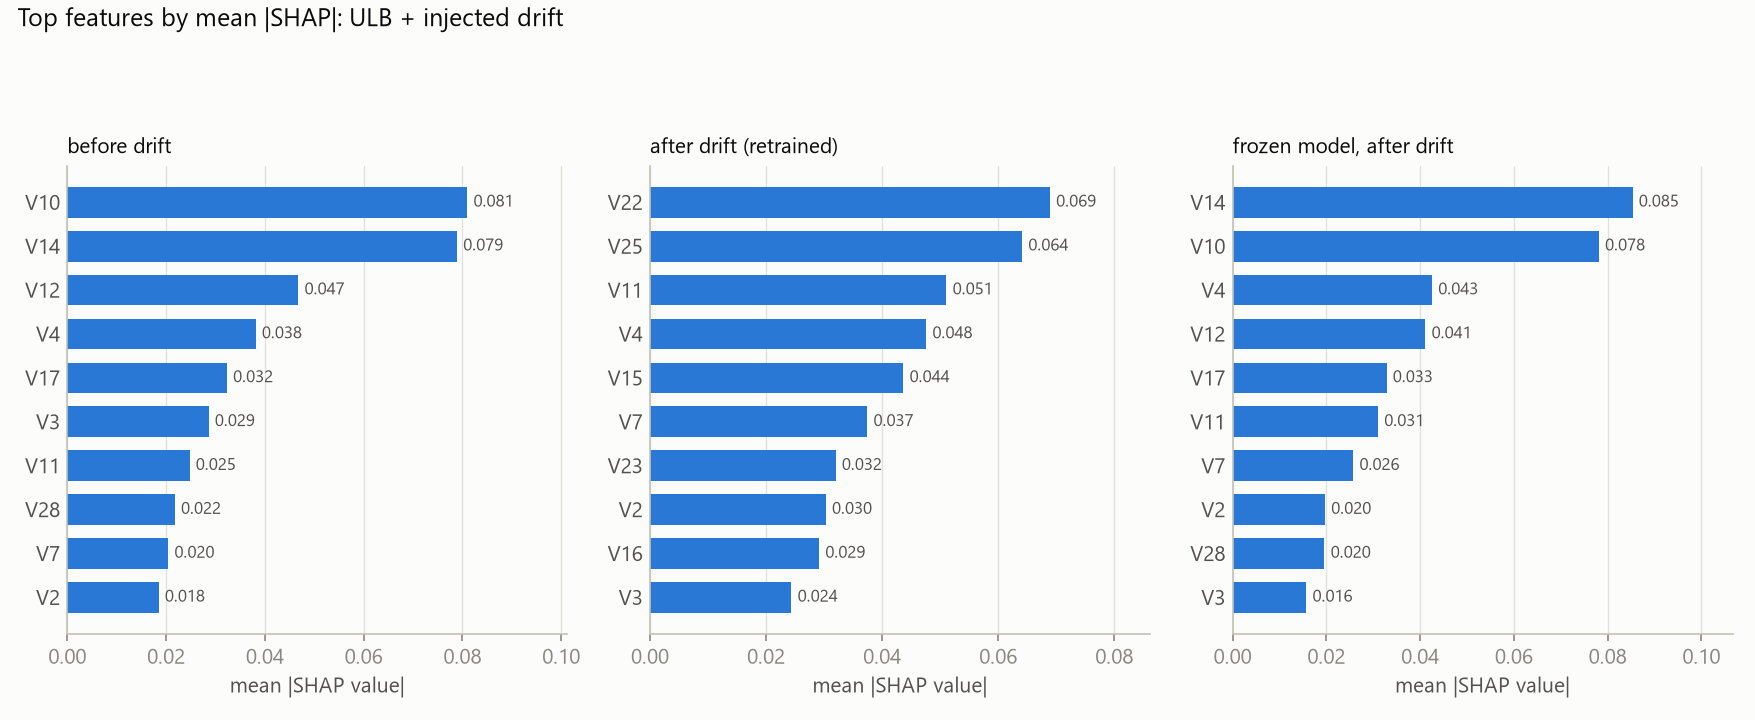

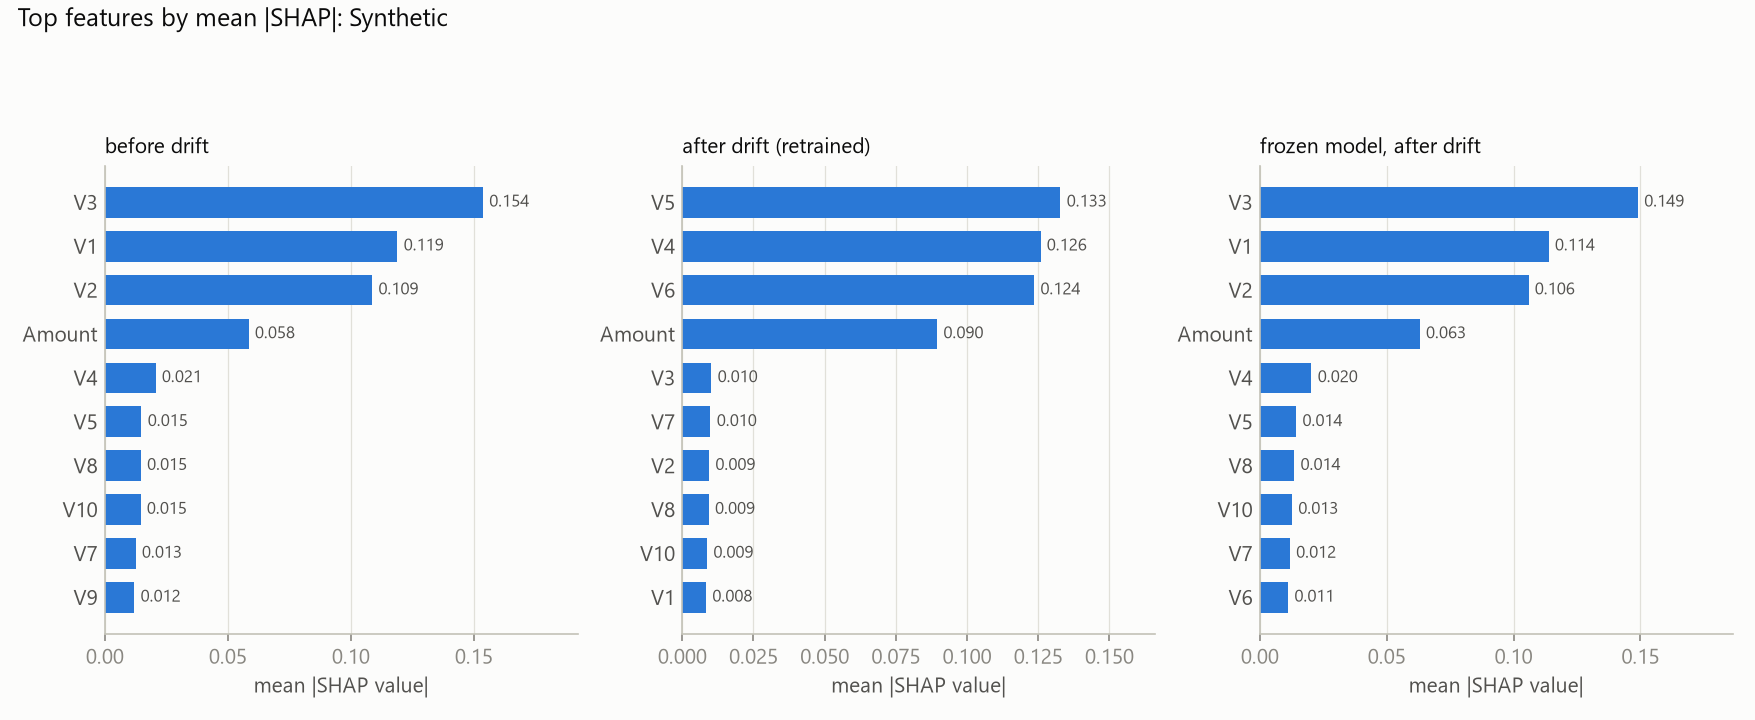

In [83]:
for tag in ["creditcard_drift50", "synthetic"]:
    imp = pd.read_csv(f"{R}/{tag}_shap_importance.csv").set_index("feature")
    show(plot_feature_importance, {c: imp[c] for c in imp.columns},
         title=f"Top features by mean |SHAP|: {DATASETS[tag]['label']}")

**Interpretation (SHAP).** The importance shift reproduces the mechanism of each drift exactly.
- **ULB + drift.**
  - **Before the drift** the random forest relies on V10 (0.081), V14 (0.079), V12 (0.047) and V17 (0.032).
    All four are swapped with weak features at the drift (V10↔V15, V14↔V23, V12↔V25, V17↔V22).
  - **After retraining** the model moves to the columns that now hold those signals: V22 (0.069), V25 (0.064)
    and V15 (0.044). The old top features drop to about 0.004.
  - **The frozen model keeps relying on V14, V10 and V12.** After the swap those columns carry the weak
    features' values, which explains its collapse.
- **Synthetic.** Before the drift the fraud signal is in V1–V3 (top three features); after retraining it is in
  V4–V6. This matches how the generator moves fraud from V1–V3 to V4–V6. The frozen model still looks at V1–V3.
- **Amount** stays a secondary feature in both datasets.
- **Takeaway:** retraining does not just raise the score; it learns the new pattern. SHAP gives a simple check
  that a recovered model looks at the right features.

### 6. Supplementary: why does accumulate not beat periodic retraining?

Added **after** the held-out protocol was evaluated. Nothing in sections 1–5 was changed by it.

#### 6.1 Where the gap comes from
Each post-drift batch of the protocol (ULB scenarios, 3 seeds), split by phase relative to accumulate's ADWIN
alarm. The value is accumulate minus periodic retraining, in PR-AUC.

In [84]:
gap = pd.read_csv(f"{R}/supplementary_gap_by_phase.csv")
phases = ["waiting for alarm", "no alarm", "accumulating", "frozen after"]
gap.groupby("phase").agg(batches=("diff", "size"), accumulate=("pr_auc_accumulate", "mean"),
                         periodic=("pr_auc_periodic", "mean"), difference=("diff", "mean")).loc[phases].round(3)

,batches,accumulate,periodic,difference
phase,,,,
waiting for alarm,210,0.202,0.481,-0.279
no alarm,84,0.174,0.515,-0.341
accumulating,375,0.664,0.605,0.058
frozen after,501,0.724,0.724,-0.000


In [85]:
# detection delay (batches after the drift batch) vs frauds arriving in the 3 batches from the drift on
delay = gap.groupby(["role", "scenario"], sort=False).agg(
    frauds_in_next_3_batches=("frauds_next_3_batches", "first"),
    adwin_delay_batches=("detection_delay", "mean"))
delay.round(1)

frauds_in_next_3_batches  adwin_delay_batches
role        scenario                                                   
development dev                                 96                  1.0
held-out    drift30                             43                  3.7
            drift70                             35                  3.0
            k2                                  96                  1.0
            k6                                  96                  1.0
            random_pairs                        96                  0.7
            gradual                             25                  7.7
label delay delay1                              96                  2.0
            delay3                              96                  4.0

**Interpretation (where the gap comes from).**
- **The whole deficit is in the waiting.** While the drift has happened but accumulate has not yet refit,
  accumulate trails periodic retraining by 0.28 PR-AUC (210 batches). When ADWIN never fires at all (logistic
  regression, 2- and 6-pair swaps) it trails by 0.34. In those batches accumulate is still the frozen pre-drift
  model, while periodic retraining has already refit once or twice on a window that includes post-drift data.
- **Once it reacts, accumulate is ahead.** It leads by +0.06 while it accumulates. Most likely this is because
  its window holds only post-drift data, while periodic's 6-batch window still contains pre-drift batches.
- **After that the two are level** (−0.000 over 501 batches). So a stale model after accumulation is *not* the
  problem, and a longer or shorter accumulation window would not change the picture.
  The sensitivity sweep (section 3) agrees: 6 and 10 batches gave nearly the same score.
- **Detection delay depends on how many frauds follow the drift.**
  - ADWIN learns from one value per fraud. In the scenarios at 50% the drift is followed by the two largest
    fraud bursts in the dataset (96 frauds in 3 batches), and ADWIN fires within about 1 batch.
  - At 30% and 70% (35–43 frauds in 3 batches) it takes 3–4 batches; for the gradual drift (25 frauds), about 8.
  - Label delay adds its own batches on top.
- **This explains the development-vs-held-out drop.** The development scenario happened to sit just before a
  fraud burst, which made detection unusually fast. The held-out scenarios at 50% (k2, k6, random pairs) share
  that luck. There, for the tree models, accumulate is within −0.06 to +0.00 of periodic retraining, and only
  one small difference is significant (random forest, k2: −0.026). The losses concentrate
  where detection is slow (drift at 30%, gradual drift) or absent (logistic regression, k2 and k6).
- **Ruled out:**
  - Mixing old and new data: accumulate trains only on post-alarm batches.
  - Too few frauds to train on: 6 post-drift batches is the same volume as periodic's window.

#### 6.2 A candidate fix: periodic retraining with an ADWIN reset
**Periodic + ADWIN reset:** retrain every 3 batches as periodic retraining does, and on an ADWIN alarm drop the
old window and refit on every new batch until it holds 6 post-drift batches. Then return to the schedule.
- **Origin:** this strategy was designed from the analysis above.
- **Independent test:** 4 new drift scenarios, fixed before any run and never used for anything else
  (drift at 40%; drift at 60% with 3 pairs; random pairs at 35%; gradual from 55% over 15%), with 3 seeds.
- **The original 10 scenarios** (seed 0) are development data for this fix and are reported separately.

In [86]:
sup = pd.read_csv(f"{R}/supplementary_summary.csv")
sup_cmp = pd.read_csv(f"{R}/supplementary_comparisons.csv")
order = ["periodic retrain", "+ ADWIN + accumulate", "periodic + ADWIN reset"]
fresh = sup[sup["role"].str.startswith("fresh")]
fresh.pivot_table(index=["scenario", "family"], columns="strategy", values="pr_auc_after", sort=False)[order].round(3)

strategy                                   periodic retrain  + ADWIN + accumulate  periodic + ADWIN reset
scenario     family                                                                                      
drift40      Gradient boosting (static)               0.673                 0.601                   0.655
             Logistic regression (static)             0.532                 0.523                   0.532
             Random forest (static)                   0.734                 0.671                   0.722
drift60_k3   Gradient boosting (static)               0.692                 0.546                   0.692
             Logistic regression (static)             0.579                 0.192                   0.579
             Random forest (static)                   0.760                 0.593                   0.755
rand2_at35   Gradient boosting (static)               0.707                 0.526                   0.707
             Logistic regression (static)             0.597                 0.299                   0.597
             Random forest (static)                   0.758                 0.757                   0.758
gradual_late Gradient boosting (static)               0.585                 0.480                   0.585
             Logistic regression (static)             0.448                 0.465                   0.448
             Random forest (static)                   0.686                 0.539                   0.684

In [87]:
c = sup_cmp.copy()
c["comparison"] = c["a"] + "  minus  " + c["b"]
c["outcome"] = np.select([c["lo"] > 0, c["hi"] < 0], ["first better", "first worse"], "not significant")
c["scenarios"] = np.where(c["role"].str.startswith("fresh"), "fresh (independent test)",
                          "original, seed 0 (development for the fix)")
counts = c.pivot_table(index=["scenarios", "comparison"], columns="outcome", values="mean", aggfunc="size",
                       fill_value=0)
counts["mean difference"] = c.groupby(["scenarios", "comparison"])["mean"].mean()
counts.round(3)

outcome                                                                                         first better  first worse  not significant  mean difference
scenarios                                  comparison                                                                                                      
fresh (independent test)                   + ADWIN + accumulate  minus  periodic retrain                   0            5                7           -0.130
                                           periodic + ADWIN reset  minus  + ADWIN + accumulate             4            0                8            0.127
                                           periodic + ADWIN reset  minus  periodic retrain                 0            2               10           -0.003
original, seed 0 (development for the fix) periodic + ADWIN reset  minus  + ADWIN + accumulate             7            0               23            0.066
                                           periodic + ADWIN reset  minus  periodic retrain                 3            0               27            0.015

In [88]:
c[c["role"].str.startswith("fresh")][["scenario", "family", "comparison", "mean", "lo", "hi", "significant"]].round(3)

,scenario,family,comparison,mean,lo,hi,significant
0,drift40,Logistic regression (static),periodic + ADWIN reset minus periodic retrain,0.000,0.000,0.000,False
1,drift40,Logistic regression (static),periodic + ADWIN reset minus + ADWIN + accumulate,0.009,-0.161,0.101,False
2,drift40,Logistic regression (static),+ ADWIN + accumulate minus periodic retrain,-0.009,-0.101,0.161,False
3,drift40,Random forest (static),periodic + ADWIN reset minus periodic retrain,-0.011,-0.034,0.004,False
4,drift40,Random forest (static),periodic + ADWIN reset minus + ADWIN + accumulate,0.051,-0.003,0.135,False
5,drift40,Random forest (static),+ ADWIN + accumulate minus periodic retrain,-0.063,-0.142,0.000,False
6,drift40,Gradient boosting (static),periodic + ADWIN reset minus periodic retrain,-0.019,-0.079,0.021,False
7,drift40,Gradient boosting (static),periodic + ADWIN reset minus + ADWIN + accumulate,0.054,-0.010,0.128,False
8,drift40,Gradient boosting (static),+ ADWIN + accumulate minus periodic retrain,-0.073,-0.147,-0.006,True
9,drift60_k3,Logistic regression (static),periodic + ADWIN reset minus periodic retrain,0.000,0.000,0.000,False


**Interpretation (supplementary).**
- **On the 4 fresh scenarios the main conclusion is confirmed.** Accumulate trails periodic retraining by 0.13
  PR-AUC on average. It is significantly worse in 5 of 12 comparisons and better in none. In several cases ADWIN
  never fired at all, and accumulate stayed frozen (logistic regression, 60% drift with 3 pairs: −0.39).
- **The candidate fix brings no gain where it counts.** On the fresh scenarios, "periodic + ADWIN reset" is
  level with plain periodic retraining (−0.003 on average; 0 better, 2 tiny significant losses of −0.005 and
  −0.002).
  - It beats accumulate (+0.13), but only because it behaves like periodic retraining.
  - Because it keeps adapting on schedule, its miss rate never jumps much, and ADWIN fired in only a third of
    its runs.
- **The original scenarios told a rosier story.** There the fix looked slightly better than periodic
  retraining: +0.015 over all original scenarios (+0.029 on the development ones, +0.043 with label delay),
  with 3 significant gains. Those are the
  scenarios it was designed from. On untouched scenarios the gain disappeared. This is exactly why the fix is
  judged on the fresh scenarios only.
- **Decision:** the fix is not adopted. Periodic retraining remains the recommended strategy. The reset variant
  stays in the code as a documented, switched-off option (`eager_after_reset`), so that this negative result
  can be reproduced.
- **Agreement with other work.** Comparable studies found the same: on injected abrupt drift in credit-card
  fraud, periodic retraining recovered more than ADWIN-triggered retraining, and ADWIN reacted only after
  several windows (see the report's literature review).

### Overall ranking of the adaptive strategies (held-out scenarios, mean of 3 seeds)
Every approach averaged over the 6 held-out scenarios and the models it applies to.

In [89]:
held = protocol[(protocol["role"] == "held-out") & ~protocol["family"].str.contains("rule")].copy()
held["approach"] = np.where(held["family"].str.contains("online"), "online logistic regression",
                            "static models") + " / " + held["strategy"]
ranking = held.groupby("approach").agg(
    post_drift_pr_auc=("pr_auc_after", "mean"), operational_recall=("op_recall_after", "mean"),
    operational_precision=("op_precision_after", "mean"), false_alarms_per_run=("false_alarms_per_run", "mean"))
ranking.sort_values("post_drift_pr_auc", ascending=False).round(3)

,post_drift_pr_auc,operational_recall,operational_precision,false_alarms_per_run
approach,,,,
static models / periodic retrain,0.649,0.504,0.802,0.000
static models / DDM warning window,0.596,0.396,0.817,0.278
static models / + DDM,0.591,0.404,0.813,0.222
static models / + ADWIN + accumulate,0.562,0.431,0.762,0.000
static models / + ADWIN,0.464,0.306,0.713,0.000
online logistic regression / + DDM,0.443,0.333,0.491,0.000
online logistic regression / + ADWIN,0.432,0.333,0.449,0.000
online logistic regression / base,0.432,0.333,0.449,0.000
static models / base,0.161,0.070,0.338,0.000


In [90]:
# best model per strategy (held-out mean post-drift PR-AUC)
held[held["family"].str.contains("static")].pivot_table(index="family", columns="strategy", values="pr_auc_after",
                                                        sort=False).pipe(ordered).round(3)

strategy,base,periodic retrain,+ ADWIN,+ DDM,DDM warning window,+ ADWIN + accumulate
family,,,,,,
Logistic regression (static),0.077,0.522,0.300,0.534,0.525,0.414
Random forest (static),0.309,0.748,0.625,0.666,0.675,0.675
Gradient boosting (static),0.096,0.675,0.466,0.573,0.587,0.597


### Synthesis

**1. Classical models detect this fraud well, when measured properly.** Random forest reaches PR-AUC 0.76 on
ULB, about 440 times the random baseline, and keeps ~0.9 precision at a threshold carried over from the
previous batch.

**2. Without maintenance, they break silently.**
- After an abrupt drift, frozen models lose 79–99% of their PR-AUC.
- The random forest's pre-deployment test scores (0.81–0.89) still look excellent.
- After the drift, the frozen random forest raised a single alert in 134,807 transactions, so nobody would
  notice from the alert stream.

**3. Every adaptive strategy helps, and periodic retraining helps most.**
- **Size of the gain:** on the held-out scenarios, adaptation lifts post-drift PR-AUC from 0.16 (frozen) to as
  much as 0.65, and operational fraud recall by up to +0.43.
- **The ranking** (table above), confirmed with paired 95% confidence intervals and on 4 fresh scenarios:
  1. periodic retraining
  2. the DDM methods
  3. accumulate-after-drift
  4. ADWIN refit-on-alarm
  5. online logistic regression
- **The best combination is random forest with periodic retraining** (0.75 post-drift PR-AUC on held-out
  scenarios).

**4. Why the detector-based strategies trail.**
- **They wait.** Each one is frozen until its detector raises an alarm. The detectors learn from fraud labels,
  about 13 per batch, so they react 1–9 batches after the drift, depending on how many frauds follow it, and
  can miss mild drifts entirely. All of accumulate's deficit against periodic retraining lies in that waiting
  time; once it reacts it is ahead.
- **What still works:**
  - Our accumulate-after-drift variant significantly improves on standard refit-on-alarm (14 of 18 held-out
    comparisons, none worse).
  - ADWIN never raised a false alarm, which makes it a good *monitor*.
- **A tested hybrid of the two approaches** (periodic retraining + ADWIN reset) did not improve on periodic
  retraining.

**5. Practical recommendation.** Retrain fraud models on a fixed schedule, with a window of recent data. Use
drift detectors as alarms for investigation rather than as the only trigger for retraining.

**Limits and future work.**
- All drift is injected into one 48-hour dataset; a natural-drift dataset is the next step.
- Label delay lowers every strategy, and real delays are longer than the 1–3 batches tested.
- About 17 frauds per batch means individual-batch results are noisy.
- Faster detection is not free. In an offline check, label-free signals (alert rate, mean score of all
  transactions) caught every drift on logistic regression within 0–3 batches. They were slower for tree models
  on abrupt drift and raised 1–3 false alarms on undrifted data. Combining label-based and label-free signals is
  future work.

## Part E: Reproducibility check

Confirms that every module defined in this notebook is identical to the corresponding file in the repository,
so presenting from this notebook shows exactly the code that produced the results. The optional test run uses
the repository's 89 automated tests.

In [91]:
import subprocess


def normalise(text):
    return "\n".join(line.rstrip() for line in text.replace("\r\n", "\n").strip().splitlines())


rows = []
for name, source in NOTEBOOK_SOURCES.items():
    disk = PROJECT.joinpath(*name.split(".")).with_suffix(".py")
    status = "identical" if disk.exists() and normalise(disk.read_text(encoding="utf-8")) == normalise(source) else (
        "file not found" if not disk.exists() else "DIFFERENT")
    rows.append({"module": name, "repository file": disk.relative_to(PROJECT).as_posix(), "status": status})
check = pd.DataFrame(rows)
print(f"{(check['status'] == 'identical').sum()} of {len(check)} modules identical to the repository")
check[check["status"] != "identical"] if (check["status"] != "identical").any() else check.tail(3)

27 of 27 modules identical to the repository


,module,repository file,status
24,experiments.run_severity,experiments/run_severity.py,identical
25,experiments.run_shap,experiments/run_shap.py,identical
26,experiments.run_supplementary,experiments/run_supplementary.py,identical


In [92]:
if RUN["tests"]:
    result = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=PROJECT, capture_output=True, text=True)
    print(result.stdout[-1500:])
else:
    print("skipped (switch off)")

skipped (switch off)
